# 最後一哩物流資料集:資料盤點與探索

本 notebook 整合先前的兩份探索報告(`overview.html` 資料總覽、`profile_report.html` 完整剖析),目標是:

1. **盤點**課程提供的全部資料(含助教後來補充的其他場站配送計畫與車型表):有哪些資料夾、多少檔案、幾筆、涵蓋哪段時間、一列代表什麼。
2. **說明每個欄位**:中文意思、型態、缺失率、數值範圍或常見值。
3. 對每個資料集依序做**七個探索檢查步驟**,並指出使用前必須處理的資料品質問題。

### 七個檢查步驟

| 步驟 | 要做什麼 | 白話 | 常用寫法 |
|---|---|---|---|
| 1. Peek | 看前幾筆原始資料 | 先翻開來看一眼 | `df.head()` |
| 2. Dimensions | 看有幾列幾欄 | 有幾筆資料、幾個特徵 | `df.shape` |
| 3. Data types | 看每欄的資料型態 | 是數字?文字?日期? | `df.dtypes` |
| 4. Class distribution | 看各類別各有幾筆 | 是否**不平衡** | `df['y'].value_counts()` |
| 5. Descriptive statistics | 算統計摘要 | 平均、標準差、最大最小值 | `df.describe()` |
| 6. Correlations | 看欄位之間的關係 | 哪兩個特徵會一起變 | `df.corr()` |
| 7. Skew | 看分布是否偏一邊 | 分布對不對稱 | `df.skew()` |

這份資料不是分類問題,沒有單一的目標欄位 `y`,所以第 4 步改看**類別型欄位**(任務類型、事件、準點狀態等)的分布。

### 執行說明

- 欄位缺失率與範圍等**全資料統計**,讀取 `explore/profile/results.pkl`(由 `explore/profile_data.py` 產生,讀完約 3 GB 原始資料需十餘分鐘,本 notebook 不重跑)。
- 七個步驟的 Peek、型態、分布、相關係數、偏態,直接讀原始檔;GPS 與車載資料檔案很大,這部分以**代表性檔案**示範,會在各節註明用了哪些檔。
- 欄位中文說明取自 `explore/column_dictionary.py`(依各資料夾 `data_dictionary.md`、實際數值與助教問答整理;標〔助教〕者為助教回答,標「推測」者資料字典沒寫,需向課程確認)。
- **助教 Q&A:** 助教在 `綠色工程專案研究POC Proposal-1.docx` 逐一回答了各資料夾的欄位問題。第 2 節整理成對照表,並在各資料集章節用實際資料**逐項驗證**(標題為「助教說法驗證」)。助教的回答分三種來源:助教直接回答、助教轉述 AI 的判斷、助教也不確定,表中分開標示。
- **個資遮蔽:** 司機姓名、電話、車牌等欄位一律不顯示內容。
- **用字:** 車載資料原始欄名為簡體字,顯示時一律轉為臺灣正體;程式中引用欄位仍須用原始欄名。

In [1]:
import glob, os, pickle, re, sys, time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
from IPython.display import Markdown, display
from opencc import OpenCC

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "explore" else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, "explore"))
from column_dictionary import DICT  # noqa: E402

P = lambda *a: os.path.join(ROOT, *a)
pio.renderers.default = "plotly_mimetype+notebook_connected"
plt.rcParams.update({"font.family": "Microsoft JhengHei", "axes.unicode_minus": False, "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 200)

R = pickle.load(open(P("explore", "profile", "results.pkl"), "rb"))   # 全資料剖析快取

# ---- 簡體欄名/內容 → 臺灣正體(逐字 s2tw,再換用語;不可整頁套 s2twp)
_S2TW = OpenCC("s2tw")
_TW_TERMS = [("移動網絡", "行動網路"), ("網絡", "網路"), ("信息", "資訊"), ("發動機", "引擎"), ("高分辨率", "高解析度"),
             ("遠程", "遠端"), ("剎車", "煞車"), ("當前", "目前"), ("運行速度", "運轉速度"), ("信號", "訊號")]
def tw(s):
    s = _S2TW.convert(str(s))
    for a, b in _TW_TERMS:
        s = s.replace(a, b)
    return s

PII = {"Emp_name", "Emp_tel", "tel", "onlinetel", "駕駛", "Driver", "車牌號碼", "License-Plate", "carlicence"}
SEV = {"alert": "🔴 嚴重", "warn": "🟠 注意", "info": "🔵 說明"}

def read(f, **k):
    # 依 pandas 預設推論型態讀取(第 3 步會看推論結果)
    return pd.read_csv(f, encoding="utf-8-sig", low_memory=False, **k)

def peek(df, n=5):
    # 步驟 1:前 n 筆;個資遮蔽、簡體轉正體
    d = df.head(n).copy()
    for c in d.columns:
        if c in PII:
            d[c] = "(個資遮蔽)"
        elif d[c].dtype == object:
            d[c] = d[c].map(lambda v: tw(v) if isinstance(v, str) else v)
    d.columns = [tw(c) for c in d.columns]
    return d

def dtype_table(df, key):
    # 步驟 3:pandas 推論的型態 + 欄位中文說明
    return pd.DataFrame({"欄位": [tw(c) for c in df.columns],
                         "pandas 型態": [str(t) for t in df.dtypes],
                         "說明": [DICT.get(key, {}).get(c, "—") for c in df.columns]})

def _fmt(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return ""
    if isinstance(v, (float, np.floating)):
        return f"{v:,.0f}" if abs(v) >= 1000 else f"{v:,.2f}".rstrip("0").rstrip(".")
    return tw(v)[:19]

ID_PAT = re.compile(r"^(Store_id|Store_Name|Car_licence|Car_id|carid1|CARNO|DVRID|nodeId|Tracker name|設備名稱|#|"
                    r"Route_seq|Route_id|Route_id1|商店編號|name)$")
TYPE_ORDER = ["🔑 識別碼", "🕒 時間", "🏷️ 類別", "📏 量測值", "🚩 旗標", "📝 文字", "🔒 個資"]

def classify(r):
    # 依 data:explore-data 的欄位分類:識別碼 / 時間 / 類別(維度) / 量測值(指標) / 旗標 / 文字 / 個資
    c, k, d = str(r["column"]), r["kind"], r["distinct"]
    if c in PII: return "🔒 個資"
    if ID_PAT.search(c): return "🔑 識別碼"
    if k == "時間": return "🕒 時間"
    if k == "數值": return "🚩 旗標" if d <= 2 else ("🏷️ 類別" if d <= 30 else "📏 量測值")
    return "🏷️ 類別" if d <= 60 else "📝 文字"

def level(null_rate):
    ok = 1 - null_rate
    if ok > 0.99: return "🟢 完整"
    if ok >= 0.95: return "🟡 大致完整"
    if ok >= 0.80: return "🟠 不完整"
    return "🔴 稀疏"

def col_table(prof, key):
    # 全資料欄位盤點表(來自 results.pkl):依欄位類型分組;整欄全空的欄位收在表頭說明
    empty = [tw(c) for c, k in zip(prof["column"], prof["kind"]) if k == "空"]
    rows = []
    for _, r in prof[prof["kind"] != "空"].iterrows():
        if r["kind"] == "文字":
            ex = "(個資遮蔽)" if r["column"] in PII else tw(r["top"])[:60]
        else:
            ex = f"{_fmt(r['min'])} ~ {_fmt(r['max'])}(中位數 {_fmt(r['p50'])})"
        if r["column"] in PII:
            ex = "(個資遮蔽)"
        rows.append({"類型": classify(r), "欄位": tw(r["column"]), "說明": DICT.get(key, {}).get(r["column"], "—"),
                     "完整度": f"{level(r['null_rate'])}(缺 {r['null_rate']:.1%})", "相異值": f"{int(r['distinct']):,}",
                     "範圍或常見值": ex})
    t = pd.DataFrame(rows)
    t["_o"] = t["類型"].map({v: i for i, v in enumerate(TYPE_ORDER)})
    t = t.sort_values(["_o"], kind="stable").drop(columns="_o")
    cap = f"共 {len(prof)} 欄:有資料 {len(t)} 欄" + (f";整欄全空 {len(empty)} 欄(不列出):{'、'.join(empty)}" if empty else "")
    return (t.style.hide(axis="index").set_caption(cap)
            .set_properties(**{"text-align": "left"})
            .set_table_styles([{"selector": "caption", "props": "caption-side: top; text-align: left; font-weight: bold;"}]))

def show_issues(key):
    iss = R[key]["issues"]
    return pd.DataFrame([{"等級": SEV.get(i["severity"], i["severity"]), "問題": i["title"], "說明": tw(i["detail"])}
                         for i in iss]).style.hide(axis="index").set_properties(**{"text-align": "left"})

def vc(s, n=10, name=None):
    # 步驟 4:類別分布(筆數與比例)
    c = s.value_counts(dropna=False)
    out = pd.DataFrame({"筆數": c, "比例": (c / c.sum()).map("{:.1%}".format)}).head(n)
    out.index = [tw(i) if isinstance(i, str) else ("(空)" if pd.isna(i) else i) for i in out.index]
    out.index.name = tw(name or s.name)
    return out

def num(df, cols):
    return df[cols].apply(pd.to_numeric, errors="coerce").rename(columns=tw)

def corr_heat(df, title, figsize=(7, 5.5)):
    # 步驟 6:相關係數熱圖
    c = df.corr()
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(c.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(c)), c.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(c)), c.columns)
    for i in range(len(c)):
        for j in range(len(c)):
            ax.text(j, i, f"{c.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(c.values[i, j]) > 0.6 else "black")
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.8)
    ax.set_title(title, loc="left", fontweight="bold")
    plt.tight_layout(); plt.show()
    pairs = [(c.columns[i], c.columns[j], c.values[i, j]) for i in range(len(c)) for j in range(i + 1, len(c))
             if abs(c.values[i, j]) > 0.7]
    if pairs:
        print("高度相關(|r| > 0.7)的欄位組合(相關不代表因果):")
        for a, b, v in sorted(pairs, key=lambda x: -abs(x[2])):
            print(f"  {a} ↔ {b}:r = {v:.2f}")
    else:
        print("沒有 |r| > 0.7 的欄位組合。")

def skew_table(df):
    # 步驟 7:偏態
    s = df.skew().rename("偏態")
    lab = s.map(lambda v: "左右大致對稱" if abs(v) < 0.5 else ("右偏(右側長尾)" if v > 0 else "左偏(左側長尾)")
                if abs(v) < 2 else ("嚴重右偏" if v > 0 else "嚴重左偏"))
    return pd.DataFrame({"偏態": s.round(2), "判讀": lab})

print("專案根目錄:", ROOT)

專案根目錄: C:\Users\a0903\Documents\slides\綠色工程專題研究\course_data\course_data


## 0. 一頁看懂:我們有哪些資料

**目錄:** 0 一頁看懂 · 1 資料盤點 · 2 名詞、代碼與助教 Q&A · 3 門市主檔 · 4 配送計畫 · 5 TMS · 6 GPS · 7 車載 CAN · 8 其他場站配送計畫 · 9 車型表 · 10 總結與建議

### 資料卡總表

| 資料集 | 一列代表 | 筆數 | 時間範圍 | 涵蓋對象 | 最適合用來 | 最大限制 |
|---|---|---:|---|---|---|---|
| **門市主檔** store_master | 一家全家門市 | 1,569 | 快照 | 臺北、新北、基隆門市 | 門市座標、地圖、路線距離 | 與配送資料編號不同,只能用店名對應 |
| **配送計畫** delivery_plan | 某日某車某路線的一個停靠點 | 34.7 萬 | 2024-01 ~ 2025-03 | 23 輛車、約 700 家店、5 種任務 | 路線、停靠順序、班次、車輛調度 | 沒有貨量;計畫時間是整趟的,不是逐店 |
| **TMS 配送紀錄** | 一趟配送中的一站 | 22.1 萬 | 2024-01 ~ 2026-01 | 只有任務 12(早班) | 準點分析(表訂 vs 實際)、車廂溫度 | 只有一種任務;「預計到達」疑為回填 |
| **GPS 軌跡** gps_traces | V13 的一筆定位紀錄(約每秒) | 259.6 萬 | 2024 年與 2025 年的 3–4 月 | **只有 V13 一輛車** | 逐秒軌跡、停等、駕駛行為、年度比較 | 只有一輛車;2025 年沒有任務代碼 |
| **車載 CAN** vehicle_can_telematics | 一筆車載紀錄 | 555.2 萬 | 2025-01 ~ 2025-07 | 14 輛車、4 種格式 | **實測油耗與排放**、怠速、引擎狀態 | 只有 7 輛車有油耗;沒有外氣溫度 |
| **其他場站配送計畫** delivery_plan_other_depots(助教補充) | 某日某趟的一個停靠點 | 45.0 萬 | 林口 2024-01 ~ 2025-12;高雄 2024-01 ~ 2026-10 | 林口 17 輛車、895 店;高雄 47 輛車、1,345 店;全部配別 | 跨場站比較每趟停靠數(容量上限)、共用車隊串接 | 沒有東北角門市;高雄門市無座標;林口與瑞芳共用 11 台車 |
| **車型表** vehicle_class_by_V.csv(助教補充) | 一輛車 | 23 | 快照 | V01–V23(17 台在車輛總表) | 依車型分組油耗與排放、插電制冷、車長 | 6 台臨時車無資料;趟數欄期間不明 |

### 我想做 X,該用哪份資料?

| 想分析 | 用哪份資料 | 可用程度 |
|---|---|---|
| 排放基準(L/100km、g CO₂/km) | 車載 CAN(A TransIOT + CAN 格式) | ✅ 7 輛車、約 2–3 個月 |
| 怠速與停等 | 車載 CAN(轉速 + 輪速)、GPS 與天眼「狀態」 | ✅ |
| 路線與班次最佳化 | 配送計畫 + 門市主檔 | ✅ 15 個月 |
| 準點與時間窗 | TMS | ✅ 只限任務 12 |
| 冷鏈車廂溫度 | TMS、天眼、車載溫度探頭 | ⚠️ 單一溫區;沒有冷藏設備運轉訊號 |
| 2024 vs 2025 比較 | GPS(V13,3–4 月) | ✅ 各 58 天 |
| 油耗(GPS 檔) | — | ❌ GPS「燃料」是**油位百分比**,不是油耗(助教確認);油耗只能用車載 CAN |
| 每趟容量上限(以停靠數代替) | 配送計畫 + 其他場站配送計畫 + 車型表 | ✅ 三場站、分車型 |
| 分車型的排放係數 | 車型表 + 車載 CAN | ⚠️ 只有 5t 14 尺六期有實測油耗 |
| 裝載率、每件成本 | — | ❌ **所有資料都沒有貨量** |
| 外氣溫度的影響 | — | ❌ 需外部氣象資料 |

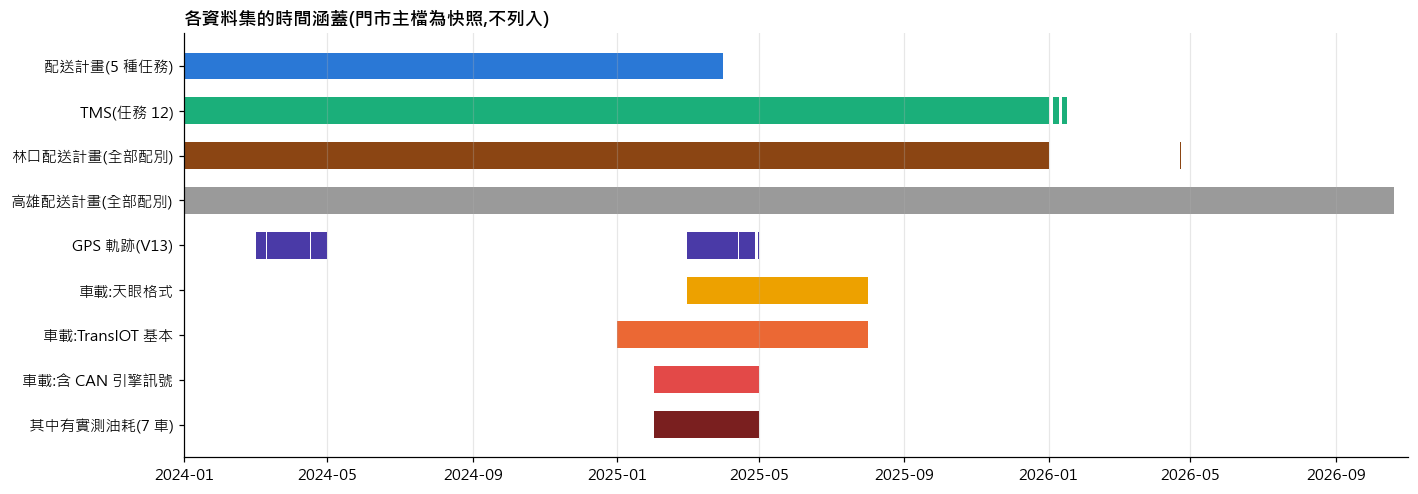

In [2]:
# 各資料集逐日涵蓋:有色區段 = 當天有資料;空白 = 沒有資料
def runs(days):
    days = sorted(pd.to_datetime(pd.Series(list(days))).dt.normalize().unique())
    out, s0, prev = [], None, None
    for d in days:
        if s0 is None: s0 = prev = d
        elif (d - prev).days == 1: prev = d
        else: out.append((s0, prev)); s0 = prev = d
    if s0 is not None: out.append((s0, prev))
    return out

def span_days(df):
    return {d for a, b in zip(df["start"], df["end"]) for d in pd.date_range(pd.Timestamp(a).normalize(), pd.Timestamp(b).normalize())}

cpf = R["vehicle_can_telematics"]["perfile"]
OD_DAYS = {d: pd.to_datetime(pd.read_csv(P("delivery_plan_other_depots", "delivery_plan_other_depots", d, "all_delivery.csv"),
                                         usecols=["Delivery_date"])["Delivery_date"].unique(), format="%m/%d/%Y %I:%M:%S %p")
           for d in ["linkou_LC", "kaohsiung_YT"]}   # 助教補充的其他場站
FUEL7 = ["V04", "V06", "V07", "V09", "V17", "V18", "V19"]
LANES = [
    ("配送計畫(5 種任務)", R["delivery_plan"]["extra"]["daily"].index, "#2a78d6"),
    ("TMS(任務 12)", R["tms"]["extra"]["daily"].index, "#1baf7a"),
    ("林口配送計畫(全部配別)", OD_DAYS["linkou_LC"], "#8b4513"),
    ("高雄配送計畫(全部配別)", OD_DAYS["kaohsiung_YT"], "#9a9a9a"),
    ("GPS 軌跡(V13)", R["gps_traces"]["perfile"]["date"], "#4a3aa7"),
    ("車載:天眼格式", span_days(cpf[cpf["family"].str.startswith("B")]), "#eda100"),
    ("車載:TransIOT 基本", span_days(cpf[cpf["family"].str.contains("基本|加油")]), "#eb6834"),
    ("車載:含 CAN 引擎訊號", span_days(cpf[cpf["family"].str.contains("CAN")]), "#e34948"),
    ("　其中有實測油耗(7 車)", span_days(cpf[cpf["family"].str.contains("CAN") & cpf["vehicle"].isin(FUEL7)]), "#7a1f1f"),
]
fig, ax = plt.subplots(figsize=(13, 4.6))
for i, (name, days, col) in enumerate(LANES):
    for a, b in runs(days):
        ax.barh(i, (b - a).days + 1, left=a, height=0.6, color=col)
ax.set_yticks(range(len(LANES)), [l[0] for l in LANES]); ax.invert_yaxis()
ax.set_xlim(pd.Timestamp("2024-01-01"), pd.Timestamp("2026-11-01")); ax.grid(axis="y", visible=False)
ax.set_title("各資料集的時間涵蓋(門市主檔為快照,不列入)", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

**看圖重點:** 五組資料**同時都有的期間只有 2025 年 3 月**;有實測油耗的期間集中在 2025 年 2–4 月。若分析需要同時用到配送計畫(到 2025-03)與油耗(2025-02 起),只能用 2025 年 2–3 月。助教補充的林口(到 2025-12)與高雄(到 2026-10,仍在更新)涵蓋期間較長,但都不是瑞芳的資料。

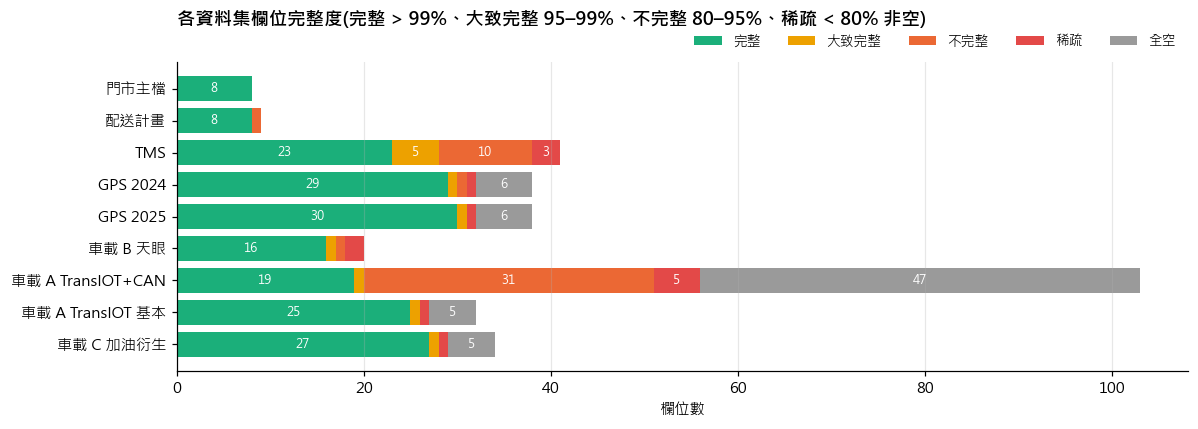

,🔑 識別碼,🕒 時間,🏷️ 類別,📏 量測值,🚩 旗標,📝 文字,🔒 個資,整欄全空
門市主檔,2,0,0,4,0,1,1,0
配送計畫,4,3,2,0,0,0,0,0
TMS,7,12,7,6,5,0,4,0
GPS 2024,2,3,7,15,1,4,0,6
GPS 2025,2,3,7,15,1,3,1,6
車載 B 天眼,4,1,5,5,2,2,1,0
車載 A TransIOT+CAN,1,2,17,31,2,3,0,47
車載 A TransIOT 基本,1,2,6,14,1,3,0,5
車載 C 加油衍生,1,2,7,14,2,3,0,5


In [3]:
# 欄位完整度與類型總覽(全資料,來自 results.pkl)
PROFS = [("門市主檔", R["store_master"]["profile"]), ("配送計畫", R["delivery_plan"]["profile"]), ("TMS", R["tms"]["profile"]),
         ("GPS 2024", R["gps_traces"]["profiles"]["2024"]["profile"]), ("GPS 2025", R["gps_traces"]["profiles"]["2025"]["profile"])]
PROFS += [(f"車載 {k.split('(')[0]}", v["profile"]) for k, v in R["vehicle_can_telematics"]["profiles"].items()]
LV = ["🟢 完整", "🟡 大致完整", "🟠 不完整", "🔴 稀疏", "⚫ 全空"]
qual = pd.DataFrame({n: pd.Series([("⚫ 全空" if k == "空" else level(r)) for r, k in zip(p["null_rate"], p["kind"])]).value_counts()
                     for n, p in PROFS}).T.reindex(columns=LV, fill_value=0).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(11, 4))
left = np.zeros(len(qual))
for lv, col in zip(LV, ["#1baf7a", "#eda100", "#eb6834", "#e34948", "#9a9a9a"]):
    ax.barh(qual.index, qual[lv], left=left, color=col, label=lv.split(" ")[1])
    for y, (l, v) in enumerate(zip(left, qual[lv])):
        if v >= 3: ax.text(l + v / 2, y, str(v), ha="center", va="center", fontsize=8, color="white")
    left += qual[lv].values
ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.set_xlabel("欄位數")
ax.legend(ncols=5, loc="lower right", fontsize=9, frameon=False, bbox_to_anchor=(1, 1))
ax.set_title("各資料集欄位完整度(完整 > 99%、大致完整 95–99%、不完整 80–95%、稀疏 < 80% 非空)", loc="left", fontweight="bold", pad=24)
plt.tight_layout(); plt.show()

types = pd.DataFrame({n: pd.Series([classify(r) for _, r in p[p["kind"] != "空"].iterrows()]).value_counts() for n, p in PROFS}).T
types = types.reindex(columns=[t for t in TYPE_ORDER if t in types.columns]).fillna(0).astype(int)
types["整欄全空"] = qual["⚫ 全空"]
types

**看圖重點:** 門市主檔與配送計畫的欄位幾乎都完整;TMS 大多完整,但第二溫區、物流中心端實際時間等少數欄位缺很多;車載「含 CAN」格式 103 欄中有 47 欄整欄全空(車輛電腦不支援),另有 31 欄缺約一成(V02、V22 的檔案整批沒有 CAN 數值),實際可用 56 欄。下表是各資料集「有資料的欄位」依類型的數量:**量測值**(可計算的數字)主要集中在 GPS 與車載資料,配送計畫幾乎沒有量測值,只有代碼與時間。

## 1. 資料盤點

課程提供 7 個資料夾(其中 `delivery_plan` 分成 3 種切法),助教後來補充 2 份資料:其他場站配送計畫與車型表。下表的列數是實際逐檔計算。

In [4]:
def count_rows(path):
    with open(path, "rb") as f:
        return max(sum(b.count(b"\n") for b in iter(lambda: f.read(1 << 22), b"")) - 1, 0)

INV = [
    ("store_master", "store_master/*.csv", "快照(無時間)", "一列 = 一家全家門市", "門市名稱、地址、座標"),
    ("delivery_plan/monthly", "delivery_plan/monthly/*.csv", "2024-01 ~ 2025-03", "一列 = 某日某車某路線的一個停靠點",
     "★配送計畫主檔:任務類型、路線、車號、門市、計畫與實際到店時間"),
    ("delivery_plan/by_vehicle", "delivery_plan/by_vehicle/*.csv", "2024-01 ~ 2025-03", "同上,依車輛分檔",
     "monthly 的另一種切法,約 59% 重複,不需另外使用"),
    ("delivery_plan/by_task_type", "delivery_plan/by_task_type/*.csv", "2024-01 ~ 2025-03", "同上,依任務分檔",
     "monthly 的子集,不需另外使用"),
    ("tms_delivery_records", "tms_delivery_records/**/*.csv", "2024-01 ~ 2026-01", "一列 = 一趟配送中的一站",
     "只有任務 12:表訂/預計/實際到店時間、準點判定、車廂溫度"),
    ("gps_traces", "gps_traces/**/*.csv", "2024-03/04、2025-03/04", "一列 = V13 的一筆 GPS 紀錄(約每秒)",
     "只有 V13 一輛車;兩套定位系統併列,含天眼車輛狀態"),
    ("vehicle_can_telematics", "vehicle_can_telematics/**/*.csv", "2025-01 ~ 2025-07", "一列 = 一筆車載紀錄",
     "14 輛車;4 種匯出格式,其中 7 輛有引擎 CAN 實測油耗"),
    ("delivery_plan_other_depots/linkou_LC(補充)", "delivery_plan_other_depots/**/linkou_LC/*.csv", "2024-01 ~ 2025-12",
     "一列 = 某日某趟的一個停靠點", "林口 DC 全部配別;與瑞芳共用 11 台車、9 位司機"),
    ("delivery_plan_other_depots/kaohsiung_YT(補充)", "delivery_plan_other_depots/**/kaohsiung_YT/*.csv", "2024-01 ~ 2026-10",
     "一列 = 某日某趟的一個停靠點", "高雄 DC 全部配別;獨立車隊;門市不在門市主檔"),
    ("vehicle_class_by_V.csv(補充)", "vehicle_class_by_V.csv", "快照(無時間)", "一列 = 一輛車",
     "車級、噸數、車長、排放期別、插電制冷、各任務趟數"),
]
rows = []
for name, pat, span, grain, use in INV:
    fs = [f for f in glob.glob(P(pat), recursive=True) if f.endswith(".csv")]
    rows.append({"資料夾": name, "檔案數": len(fs), "大小(MB)": round(sum(os.path.getsize(f) for f in fs) / 1e6, 1),
                 "列數": sum(count_rows(f) for f in fs), "時間範圍": span, "一列代表": grain, "主要內容": use})
inv = pd.DataFrame(rows)
inv.style.format({"大小(MB)": "{:,.1f}", "列數": "{:,}"}).hide(axis="index").set_properties(**{"text-align": "left"})

資料夾,檔案數,大小(MB),列數,時間範圍,一列代表,主要內容
store_master,1,0.2,"1,568",快照(無時間),一列 = 一家全家門市,門市名稱、地址、座標
delivery_plan/monthly,15,32.7,"346,612",2024-01 ~ 2025-03,一列 = 某日某車某路線的一個停靠點,★配送計畫主檔:任務類型、路線、車號、門市、計畫與實際到店時間
delivery_plan/by_vehicle,23,132.3,"1,149,731",2024-01 ~ 2025-03,"同上,依車輛分檔","monthly 的另一種切法,約 59% 重複,不需另外使用"
delivery_plan/by_task_type,5,26.7,"228,684",2024-01 ~ 2025-03,"同上,依任務分檔","monthly 的子集,不需另外使用"
tms_delivery_records,741,80.8,"220,584",2024-01 ~ 2026-01,一列 = 一趟配送中的一站,只有任務 12:表訂/預計/實際到店時間、準點判定、車廂溫度
gps_traces,116,916.1,"2,596,325",2024-03/04、2025-03/04,一列 = V13 的一筆 GPS 紀錄(約每秒),"只有 V13 一輛車;兩套定位系統併列,含天眼車輛狀態"
vehicle_can_telematics,90,"2,013.6","5,552,003",2025-01 ~ 2025-07,一列 = 一筆車載紀錄,"14 輛車;4 種匯出格式,其中 7 輛有引擎 CAN 實測油耗"
delivery_plan_other_depots/linkou_LC(補充),1,53.9,"135,292",2024-01 ~ 2025-12,一列 = 某日某趟的一個停靠點,林口 DC 全部配別;與瑞芳共用 11 台車、9 位司機
delivery_plan_other_depots/kaohsiung_YT(補充),1,124.9,"315,004",2024-01 ~ 2026-10,一列 = 某日某趟的一個停靠點,高雄 DC 全部配別;獨立車隊;門市不在門市主檔
vehicle_class_by_V.csv(補充),1,0.0,23,快照(無時間),一列 = 一輛車,車級、噸數、車長、排放期別、插電制冷、各任務趟數


### 各資料集之間怎麼串接

各資料集**沒有共用的主鍵**,要靠下列方式對應:

| 對應 | 連結方式 | 注意 |
|---|---|---|
| delivery_plan ↔ TMS | (日期, Route_seq, Car_licence, Store_id) | 只限任務 12;兩者重疊的 456 天,每日停靠數完全相同 |
| delivery_plan / TMS ↔ store_master | 店名去掉「全家」與「店」字後比對 | Store_id 與門市主檔「商店編號」是兩套編碼;約 80% 對得上;128 個店名對到多個 Store_id(門市換號) |
| delivery_plan ↔ GPS / 天眼 | 2024 年用 GPS「任務」或天眼 grp_id(`RF_任務_路線`);2025 年用車號＋時間 | 2025 年 GPS 沒有任務欄 |
| CAN ↔ 配送 | 車號(檔名 V##)＋時間 | CAN 檔裡沒有任務欄 |
| 其他場站 ↔ 瑞芳 | `Car_licence`、`Emp_name`(林口與瑞芳共用 11 台車、9 位司機,代號相同) | 高雄是獨立車隊;林口與瑞芳沒有共同門市;同一台車同一天可能跑兩個場站(第 8 節) |
| 其他場站 ↔ store_master | 店名比對(同上) | 林口 87% 對得上;高雄 0%(門市主檔只有北北基) |
| 車型表 ↔ 所有車輛資料 | `Car_licence`(V01–V23) | 6 台臨時或租用車沒有車型資料 |

## 2. 名詞、代碼與助教 Q&A

### 常用名詞

| 名詞 | 說明 |
|---|---|
| DC | Distribution Center,物流中心。本資料指全家**瑞芳物流中心**(新北市瑞芳區);一趟配送是「DC 裝貨 → 依序送 10–20 家門市 → 回 DC」。 |
| TMS | Transportation Management System,運輸管理系統;記錄每一站的表訂、預計、實際到店時間與車廂溫度。 |
| CAN | Controller Area Network,車上各電腦之間的通訊線路;從這裡讀出引擎轉速、油耗、怠速等訊號。 |
| 天眼 | 另一套車隊管理系統(車機),約 30 秒一筆,提供車輛狀態(行駛中、場內暫停、在外暫停…)、車廂溫度與任務代碼。 |
| DC 怠速 | 車子停在物流中心內、引擎沒熄火。 |
| 岸電 | 在物流中心停車位設插座,讓冷藏車停著時插電供冷,不必發動引擎。 |

### 任務類型 TaskType_id

資料字典沒有說明每個代碼的意思;**助教也確認這是後端 API 回傳的值,官方無法提供對應分類,要自行推論**。下表「推測用途」是依資料特徵判斷,報告中請寫明是推測。

| 代碼 | 門市停靠數 | 車輛 | 每趟停靠(中位數) | 計畫出車 | 實際到店時段(p10–p90) | 推測用途 |
|---|---:|---:|---:|---|---|---|
| 02 | 39,527 | 15 | 10 | 23 點 | 00–05 點 | 深夜/凌晨班配送 |
| 03 | 15,317 | 17 | 4 | 11 點 | 08–14 點 | 白天小趟次(推測為補送/加開) |
| 04 | 20,519 | 17 | 21 | 15 點 | 11–19 點 | 午後班配送 |
| 05 | 109,893 | 17 | 20 | 17 點 | 19 點–隔日 00 點 | 晚班主力配送(量最大) |
| 12 | 125,401 | 18 | 21 | 06 點 | 08–14 點 | 早班主力配送;車廂溫度中位數 17°C,與 18°C 鮮食溫層相符 |
| A2 | 5 | 0 | — | 不定 | 無 | 物流中心之間調撥,未派車 |
| A3 | 26 | 0 | — | 09 點 | 無 | 推測為向食品供應商取貨,未派車 |
| A4 | 614 | 11 | 9 | 10 點 | 13–17 點 | 2024-09 起出現,停靠點多為食品供應商,推測為集貨 |

### 其他代碼

| 欄位 / 代碼 | 意義 |
|---|---|
| Store_id `1001xxxxxx` | 全家門市 |
| Store_id `1006xxxxxx` | 食品供應商(只出現在 A3、A4) |
| Store_id `S3001888888` / `3001888888` | 瑞芳 DC:出發列(有 S)/ 回場列 |
| Store_id `3001111111`、`3001999999`、`3001555555`、`3001333333` | 林口、大肚、大溪、高雄 DC |
| Route_seq `LI05` | LI 路線的第 5 站;`LIDC` 是該路線的 DC 列 |
| 任務 / grp_id `RF_05_LI` | RF = 瑞芳 DC、05 = 任務類型、LI = 路線 |
| Car_licence `V01`–`V23` | 自有車輛(已去識別) |
| Car_licence `V24`–`V76` | 助教補充的林口、高雄新增車號;林口與瑞芳共用的 11 台沿用原代號 |
| Car_id `ZZ1xx` | 臨時外調車 |
| DiffStatus / mDiffStatus | -1 太早(`Ex_Arrive_diff` < −60)、0 準時、1 遲到(> +30);允收時窗 `InTime` = −60、`OutTime` = +30 是固定值。mDiffStatus 用 DC 端的 `Ex_M_Arrive_diff` 判斷 |
| last_dc | 0 = 門市停靠、1 = 回場 DC 列、空 = 出發 DC 列 |
| 預計 Pl_ / 表訂 Im_ / 實際 Ac_ | 預計 = ETA,執行中會重算、停靠完成後常回填成實際;表訂 = 門市的配送時刻(5 分鐘網格);實際 = 真正到達(秒級);`_M_` 代表 DC 端 |
| 天眼 `statusCode` | `status` 的數字代碼,一對一:0 行駛中、66 引擎熄火、67 引擎起動、68 場內關機、89 場內暫停、90 在外暫停、95 逾時停留、116/117 任務進/出圍籬 |
| 天眼 `CARCOLOR` | 不是車身顏色,是狀態圖示顏色:g 正常、r 警示(逾時停留、超速、急加減速等)、b 圍籬/熄火類 |
| 欄名前綴 `In_`、後綴 `_01`、`_02`、`1` | 同一欄位的重複副本或不同日期格式(實測 100% 相同),擇一使用 |

### 車載資料的四種匯出格式

| 格式 | 欄數 | 怎麼認 | 內容 |
|---|---|---|---|
| A TransIOT 基本 | 32 | 有 GPS Time,沒有 Total fuel used | GPS + 車廂溫度探頭 + 事件 |
| A TransIOT + CAN | 96–98 | 有 Total fuel used(L) | 上面全部 + 引擎 CAN 訊號 ★唯一能算實測油耗的格式 |
| B 天眼 | 20 | 有 dt24 欄 | GPS + 車輛狀態 + 車廂溫度 + 任務代碼;約 30 秒一筆 |
| C 加油衍生 | 34 | 檔名有 _refuel | A 基本 + 油位百分比、加油偵測 |

### 助教 Q&A 對照表

下表整理助教在 `綠色工程專案研究POC Proposal-1.docx` 的回答。**來源**欄區分助教直接回答、助教轉述 AI 的判斷(可信度較低,更需要驗證)、助教也不確定;**驗證**欄是本 notebook 用實際資料檢查的結果,細節在括號標示的章節。

In [5]:
from column_dictionary import TA_QA, TA_CAR_TASKS  # noqa: E402

SRC = {"助教": "🟢 助教", "助教引 AI": "🟡 助教引 AI", "助教不確定": "⚪ 助教不確定"}
qa = pd.DataFrame(TA_QA, columns=["資料集", "問題或欄位", "助教回答(精簡)", "來源", "驗證"])
qa["來源"] = qa["來源"].map(SRC)
print("來源統計:", qa["來源"].value_counts().to_dict(), "  驗證:",
      {k: int(qa["驗證"].str.startswith(k).sum()) for k in ["✅", "⚠️", "—"]})
qa.style.hide(axis="index").set_properties(**{"text-align": "left"})

來源統計: {'🟢 助教': 24, '🟡 助教引 AI': 5, '⚪ 助教不確定': 4}   驗證: {'✅': 22, '⚠️': 4, '—': 7}


資料集,問題或欄位,助教回答(精簡),來源,驗證
delivery_plan,TaskType_id 各代碼的定義,"後端 API 回傳值,無法確定對應分類,要自己推論",🟢 助教,— 第 2 節推測用途維持「推測」
delivery_plan,Pl_M_Arrive_dt / Ac_Arrive_dt_02,計畫到達時間 / 實際到達時間(網站沒有其他說明),🟢 助教,✅ 第 4 節:Pl_M 是整趟一個值
delivery_plan,各車輛跑哪些任務類型,附車輛 × 任務對照表(只列 02/03/04/12),🟢 助教,"⚠️ 第 4 節:漏了 05 與 A4,也漏了 V11、V22"
gps_traces,為什麼只有 2024、2025 年 3–4 月,"網站資料有時效性,當時手動爬取,量夠就停",🟢 助教,—
gps_traces,速度,瞬時車速 km/h,🟢 助教,✅ 第 6 節:與天眼「時速」r ≈ 0.91
gps_traces,路程的單位,km,🟢 助教,✅ 第 6 節:每日里程中位數合理
gps_traces,汽車電瓶,車輛電瓶電壓,🟢 助教,✅ 約 27 V(24 V 系統)
gps_traces,設備電池,推測是追蹤器本身的內建電池,⚪ 助教不確定,—
gps_traces,燃料,"油箱油位百分比,不是油耗;紅外線測油面深度換算,行駛晃動有誤差",🟢 助教,✅ 第 6 節:油位隨晃動上下跳
gps_traces,GPS有效性、衛星數量、訊號強度、實際緩速器百分比扭矩、當前使用網絡信息,不知道,⚪ 助教不確定,— 沿用資料字典與實測推論


**重點:** 助教的回答大多與資料吻合,但有四處要注意:

1. **車輛 × 任務對照表漏了任務 05 與 A4**(也漏了 V11、V22),不能拿來判斷某車有沒有跑晚班,要以 `monthly` 為準(第 4 節)。
2. **表訂時間 `Im_Arrive_dt` 並非每店固定一個時刻**:5 分鐘網格成立,但同一家店在兩年間常有 2–3 種時刻(第 5 節)。
3. **`carkit`、`DVRTYPE` 不是恆為 1**:V12 在 2025 年 6–7 月為 0(第 7 節)。
4. **天眼 `Temperature1` 並非大量為空**:全部天眼檔只缺約 10%(第 7 節)。

另外,助教提醒 TMS 有 **4,073 組可疑的共用時間戳**,本 notebook 已重現,計算行駛或停留時間前要先過濾(第 5 節)。

## 3. 門市主檔 store_master

| 項目 | 內容 |
|---|---|
| 用途 | 提供**門市座標**,供地圖與路線距離計算 |
| 一列代表 | 一家全家門市(快照,沒有時間欄) |
| 主鍵 | `name`(店名,無重複) |
| 建議使用欄位 | 座標 `lat`、`lng`;分組用「縣市」(由地址前 3 字取出) |
| 串接方式 | 用店名(去掉「全家」與「店」)對應配送資料的 `Store_Name` |

In [6]:
display(Markdown(f"**一列代表:** {R['store_master']['grain']}  **全資料:** {R['store_master']['rows']:,} 列 × {R['store_master']['cols']} 欄"))
col_table(R["store_master"]["profile"], "store_master")

**一列代表:** 一列 = 一家全家門市(快照,無時間欄)  **全資料:** 1,569 列 × 8 欄

類型,欄位,說明,完整度,相異值,範圍或常見值
🔑 識別碼,name,"門市名稱,格式「全家XXX店」",🟢 完整(缺 0.0%),"1,569",全家京江店 (0%) | 全家板橋花園店 (0%) | 全家板橋光復店 (0%) | 全家板橋新光仁店 (0%)
🔑 識別碼,商店編號,"全家內部 5 碼店號 ⚠ 與配送資料的 Store_id 是不同編碼,無法直接 join",🟢 完整(缺 0.8%),"1,556","10,003 ~ 63,658(中位數 51,465)"
📏 量測值,lng,經度(WGS84),🟢 完整(缺 0.0%),"1,568",121.34 ~ 121.94(中位數 121.51)
📏 量測值,lat,緯度(WGS84),🟢 完整(缺 0.0%),"1,566",24.86 ~ 25.29(中位數 25.04)
📏 量測值,X,"⚠ 前人爬取時自訂的座標,單位不確定,可忽略〔助教〕;一律用 lat/lng",🟢 完整(缺 0.0%),"1,567","331,703 ~ 392,691(中位數 348,899)"
📏 量測值,Y,"⚠ 同 X,可忽略〔助教〕",🟢 完整(缺 0.0%),"1,568","2,750,967 ~ 2,798,308(中位數 2,770,861)"
📝 文字,address,門市地址,🟢 完整(缺 0.0%),"1,569",臺北市中山區一江街２２號１樓 (0%) | 新北市板橋區中正路一巷１４號１樓 (0%) | 新北市板橋區中山路二段５０３
🔒 個資,tel,"門市電話(以數字儲存,開頭 0 被去掉)",🟢 完整(缺 0.8%),"1,556",(個資遮蔽)


In [7]:
sm = read(P("store_master", "store_master.csv"))
print("步驟 1 Peek"); display(peek(sm))
print("步驟 2 Dimensions:", sm.shape)
print("步驟 3 Data types"); display(dtype_table(sm, "store_master"))

步驟 1 Peek


,name,tel,address,商店編號,lng,lat,X,Y
0,全家京江店,(個資遮蔽),臺北市中山區一江街２２號１樓,18902.0,121.531351,25.052674,351017.865,2771827.523
1,全家錦原店,(個資遮蔽),臺北市中山區中原街１０１號１樓,14452.0,121.529042,25.060929,350794.796,2772744.317
2,全家新吉原店,(個資遮蔽),臺北市中山區中原街１６號１樓,54113.0,121.528785,25.056535,350763.656,2772257.979
3,全家市民店,(個資遮蔽),臺北市中山區中山北路一段５８號,18703.0,121.520604,25.048540,349928.554,2771381.515
4,全家柯達飯店,(個資遮蔽),臺北市中山區中山北路二段１１巷１號、３號,61939.0,121.523291,25.052909,350205.015,2771862.425


步驟 2 Dimensions: (1569, 8)
步驟 3 Data types


,欄位,pandas 型態,說明
0,name,object,"門市名稱,格式「全家XXX店」"
1,tel,float64,"門市電話(以數字儲存,開頭 0 被去掉)"
2,address,object,門市地址
3,商店編號,float64,"全家內部 5 碼店號 ⚠ 與配送資料的 Store_id 是不同編碼,無法直接 join"
4,lng,float64,經度(WGS84)
5,lat,float64,緯度(WGS84)
6,X,float64,"⚠ 前人爬取時自訂的座標,單位不確定,可忽略〔助教〕;一律用 lat/lng"
7,Y,float64,"⚠ 同 X,可忽略〔助教〕"


步驟 4 類別分布:門市所在縣市


,筆數,比例
縣市,,
新北市,909,57.9%
臺北市,597,38.0%
基隆市,63,4.0%


步驟 5 描述統計


,count,mean,std,min,25%,50%,75%,max
lng,1569.0,1.215154e+02,0.0811,1.213412e+02,1.214610e+02,1.215105e+02,1.215475e+02,1.219447e+02
lat,1569.0,2.504490e+01,0.0530,2.486450e+01,2.500660e+01,2.504390e+01,2.507180e+01,2.529210e+01
X,1569.0,3.493944e+05,8197.9030,3.317029e+05,3.439153e+05,3.488985e+05,3.526205e+05,3.926906e+05
Y,1569.0,2.770985e+06,5844.0440,2.750967e+06,2.766776e+06,2.770861e+06,2.773981e+06,2.798308e+06


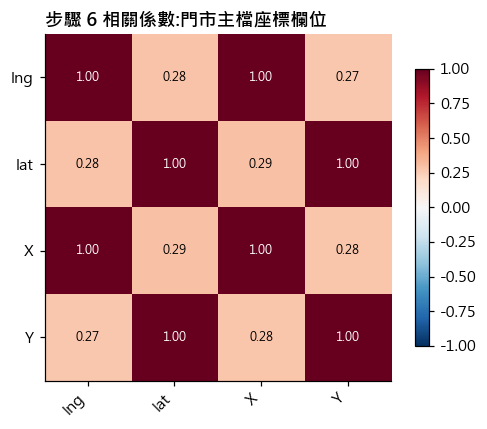

高度相關(|r| > 0.7)的欄位組合(相關不代表因果):
  lng ↔ X:r = 1.00
  lat ↔ Y:r = 1.00
步驟 7 偏態


,偏態,判讀
lng,1.13,右偏(右側長尾)
lat,0.58,右偏(右側長尾)
X,1.13,右偏(右側長尾)
Y,0.60,右偏(右側長尾)


In [8]:
sm["縣市"] = sm["address"].str[:3].str.replace("臺", "台")
print("步驟 4 類別分布:門市所在縣市"); display(vc(sm["縣市"], name="縣市"))
nums = ["lng", "lat", "X", "Y"]
print("步驟 5 描述統計"); display(num(sm, nums).describe().T.round(4))
corr_heat(num(sm, nums), "步驟 6 相關係數:門市主檔座標欄位", figsize=(5, 4))
print("步驟 7 偏態"); display(skew_table(num(sm, nums)))

**判讀:**
- **類別分布:** 門市集中在臺北市與新北市,基隆市較少;瑞芳物流中心服務的範圍主要就在這三個縣市。
- **相關係數:** `lng` 與 `X`、`lat` 與 `Y` 的相關係數接近 1,是同一個位置的兩種座標。**助教說明 X、Y 是前人爬取時自訂的座標,單位不確定,可以忽略**;本專案一律用 `lat`、`lng`(WGS84),距離用球面公式或 OSRM 路網計算。
- **資料品質:** 13 家門市沒有商店編號,其中包含瑞芳 DC 本身;門市主檔的「商店編號」和配送資料的 Store_id 是不同編碼,只能用店名對應。

In [9]:
show_issues("store_master")

等級,問題,說明
🔵 說明,主鍵,name 重複 0 列、商店編號(非空)重複 0 列、完全相同座標 2 列。
🟠 注意,缺商店編號,13 列沒有商店編號(含物流中心):瑞芳ＤＣ、林口ＤＣ、汐止金龍店、新光醫院店、松興店、新稻江店、汐止南陽店、護校店、汐止導航店、欣松春店、舊宗店、南港車站店、汐止鑫湖店
🟠 注意,電話格式,"電話以數字儲存,開頭 0 被去掉(如 225678224 應為 02-25678224);長度分佈:9碼×1556"


In [10]:
ESRI = [dict(below="traces", sourcetype="raster", sourceattribution="Tiles © Esri",
             source=["https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}"])]
kw = dict(lat="lat", lon="lng", hover_name="name", hover_data=["address"], zoom=9, height=520, color_discrete_sequence=["#1baf7a"])
if hasattr(px, "scatter_map"):
    f = px.scatter_map(sm, map_style="white-bg", **kw); f.update_layout(map_layers=ESRI)
else:
    f = px.scatter_mapbox(sm, mapbox_style="white-bg", **kw); f.update_layout(mapbox_layers=ESRI)
f.update_layout(margin=dict(t=30, b=0, l=0, r=0), title=f"全家門市分布({len(sm):,} 家)")
f.show()

## 4. 配送計畫 delivery_plan/monthly

| 項目 | 內容 |
|---|---|
| 用途 | 每天每輛車每條路線依序停靠哪些門市;路線、班次、車輛調度分析的主資料 |
| 一列代表 | 某日某車某路線的一個停靠點(含 DC 出發與回場列) |
| 主鍵 | 無單一主鍵;自然鍵為(日期、車號、路線站序 `Route_seq`、門市 `Store_id`),檢查結果見下方 |
| 建議分組欄 | 任務類型 `TaskType_id`、車號 `Car_licence`、路線(`Route_seq` 前 2 碼) |
| 時間欄 | 配送日 `Delivery_Dt`、整趟計畫時間 `Pl_M_Arrive_dt`、實際到店 `Ac_Arrive_dt_02` |
| 量測值 | **沒有**;要自行彙整(每趟停靠數、每趟時長) |
| 其他檔案 | `by_vehicle`、`by_task_type` 是同一份資料的不同切法,用 `monthly` 即可 |

In [11]:
display(Markdown(f"**一列代表:** {R['delivery_plan']['grain']}  **全資料:** {R['delivery_plan']['rows']:,} 列 × {R['delivery_plan']['cols']} 欄"))
col_table(R["delivery_plan"]["profile"], "delivery_plan")

**一列代表:** 一列 = 某日某車某路線的一個停靠點(含出發/回場 DC 列)  **全資料:** 346,612 列 × 8 欄

類型,欄位,說明,完整度,相異值,範圍或常見值
🔑 識別碼,Route_seq,路線代碼(前 2 碼)+ 站序(後 2 碼);後綴 DC = 物流中心列。例:LI05 = LI 路線第 5 站,🟢 完整(缺 0.0%),"2,800",SCDC (0%) | LMDC (0%) | SKDC (0%) | DLDC (0%)
🔑 識別碼,Car_licence,車輛代碼 V01–V23(已去識別),🟢 完整(缺 0.1%),23,V04 (11%) | V08 (11%) | V06 (10%) | V07 (9%)
🔑 識別碼,Store_id,"門市代碼 1001xxxxxx;S3001888888 = 出發 DC 列,3001888888 = 回場 DC 列",🟢 完整(缺 0.0%),861,S3001888888 (5%) | 3001888888 (5%) | 1001022211 (0%) | 10010
🔑 識別碼,Store_Name,門市名稱(不含「全家」);DC 列為「瑞芳ＤＣ」,🟢 完整(缺 0.0%),699,瑞芳ＤＣ (10%) | 行善公宅店 (0%) | 昌隆店 (0%) | 濟南二店 (0%)
🕒 時間,Delivery_Dt,配送日期,🟢 完整(缺 0.0%),456,2024-01-01 00:00:00 ~ 2025-03-31 00:00:00(中位數 )
🕒 時間,Pl_M_Arrive_dt,"計畫的 DC 到場/備車時間〔助教〕⚠ 同一趟所有站都相同,不是逐店預計到達",🟢 完整(缺 0.0%),"10,325",2023-12-31 17:00:00 ~ 2025-03-31 14:20:00(中位數 )
🕒 時間,Ac_Arrive_dt_02,實際到店時間(DC 列為空),🟠 不完整(缺 8.3%),"301,864",2023-12-31 17:54:05 ~ 2025-03-31 19:34:05(中位數 )
🏷️ 類別,TaskType_id,"任務類型代碼(02/03/04/05/12/A2/A3/A4);後端 API 回傳值,官方沒有定義〔助教〕,推測用途見「代碼對照」",🟢 完整(缺 0.0%),8,2 ~ 12(中位數 5)
🏷️ 類別,Dept_Name,"出發物流中心,全部是瑞芳DC",🟢 完整(缺 0.0%),1,瑞芳DC (100%)


In [12]:
dp = pd.concat([read(f) for f in sorted(glob.glob(P("delivery_plan", "monthly", "*.csv")))], ignore_index=True)
print("步驟 1 Peek"); display(peek(dp))
print("步驟 2 Dimensions:", dp.shape)
print("步驟 3 Data types(pandas 預設推論)"); display(dtype_table(dp, "delivery_plan"))

步驟 1 Peek


,TaskType_id,Delivery_Dt,Dept_Name,Route_seq,Car_licence,Store_id,Store_Name,Pl_M_Arrive_dt,Ac_Arrive_dt_02
0,02,2024-01-01,瑞芳DC,103DC,V18,S3001888888,瑞芳ＤＣ,2023-12-31 23:24:00,2023-12-31 23:55:59
1,02,2024-01-01,瑞芳DC,AD01,V18,1001022813,安富店,2023-12-31 23:24:00,2024-01-01 00:17:18
2,02,2024-01-01,瑞芳DC,AD02,V18,1001020647,宏勝店,2023-12-31 23:24:00,2024-01-01 00:29:32
3,02,2024-01-01,瑞芳DC,AD03,V18,1001021949,宏大店,2023-12-31 23:24:00,2024-01-01 00:29:32
4,02,2024-01-01,瑞芳DC,AJ05,V18,1001016790,大森店,2023-12-31 23:24:00,2024-01-01 00:54:20


步驟 2 Dimensions: (346612, 9)
步驟 3 Data types(pandas 預設推論)


,欄位,pandas 型態,說明
0,TaskType_id,object,"任務類型代碼(02/03/04/05/12/A2/A3/A4);後端 API 回傳值,官方沒有定義〔助教〕,推測用途見「代碼對照」"
1,Delivery_Dt,object,配送日期
2,Dept_Name,object,"出發物流中心,全部是瑞芳DC"
3,Route_seq,object,路線代碼(前 2 碼)+ 站序(後 2 碼);後綴 DC = 物流中心列。例:LI05 = LI 路線第 5 站
4,Car_licence,object,車輛代碼 V01–V23(已去識別)
5,Store_id,object,"門市代碼 1001xxxxxx;S3001888888 = 出發 DC 列,3001888888 = 回場 DC 列"
6,Store_Name,object,門市名稱(不含「全家」);DC 列為「瑞芳ＤＣ」
7,Pl_M_Arrive_dt,object,"計畫的 DC 到場/備車時間〔助教〕⚠ 同一趟所有站都相同,不是逐店預計到達"
8,Ac_Arrive_dt_02,object,實際到店時間(DC 列為空)


**型態注意:** pandas 預設會把 `TaskType_id` 的 `02`、`05` 讀成數字(前導 0 消失),時間欄則讀成文字。分析前要把代碼欄**當文字讀**、時間欄轉成日期時間,下一格就是這樣處理。

In [13]:
dp = pd.concat([pd.read_csv(f, encoding="utf-8-sig", dtype=str) for f in sorted(glob.glob(P("delivery_plan", "monthly", "*.csv")))],
               ignore_index=True)
dp["TaskType_id"] = dp["TaskType_id"].str.zfill(2)
dp["is_dc"] = dp["Store_id"].str.contains("3001888888", na=False)
dp["date"] = pd.to_datetime(dp["Delivery_Dt"], errors="coerce")
st = dp[~dp["is_dc"]].copy()
st["plan"] = pd.to_datetime(st["Pl_M_Arrive_dt"], errors="coerce")
st["act"] = pd.to_datetime(st["Ac_Arrive_dt_02"], errors="coerce")
print(f"門市停靠列 {len(st):,} 筆(另有 DC 出發/回場列 {dp['is_dc'].sum():,} 筆)")
key = ["Delivery_Dt", "Car_licence", "Route_seq", "Store_id"]
print(f"主鍵檢查:以 {key} 判斷,重複 {dp.duplicated(key).sum():,} 列;完全相同的列 {dp.duplicated().sum():,} 列")
print("步驟 4 類別分布")
display(vc(st["TaskType_id"], name="任務類型(門市停靠列)"))
display(vc(st["Car_licence"], n=23, name="車輛").T)

門市停靠列 311,302 筆(另有 DC 出發/回場列 35,310 筆)


主鍵檢查:以 ['Delivery_Dt', 'Car_licence', 'Route_seq', 'Store_id'] 判斷,重複 108 列;完全相同的列 0 列
步驟 4 類別分布


,筆數,比例
任務類型(門市停靠列),,
12,125401,40.3%
05,109893,35.3%
02,39527,12.7%
04,20519,6.6%
03,15317,4.9%
A4,614,0.2%
A3,26,0.0%
A2,5,0.0%


車輛,V04,V08,V06,V07,V19,V17,V14,V10,V16,V15,V18,V13,V02,V09,V12,V22,(空),V03,V05,V01,V23,V20,V21
筆數,34932,34253,32820,29676,25147,23163,20338,19894,18485,16451,16251,14918,12913,8444,2543,481,297,116,66,56,23,16,10
比例,11.2%,11.0%,10.5%,9.5%,8.1%,7.4%,6.5%,6.4%,5.9%,5.3%,5.2%,4.8%,4.1%,2.7%,0.8%,0.2%,0.1%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%


**判讀:** 任務 12(早班,40%)與 05(晚班,35%)合計約佔門市停靠的四分之三,是主力配送;A2/A3/A4 合計不到 0.3%。以任務類型做比較時,各類樣本量差距很大。車輛之間的停靠量也很不平均:V04、V08、V06 各佔一成以上,V01、V20、V21 等幾乎沒有出車。

### 助教說法驗證:車輛 × 任務類型

助教整理了一張「每輛車跑哪些任務類型」的表。下面拿 `monthly` 全部門市停靠列比對:**助教表**是助教列的任務,**實際**是資料中出現的任務,**助教表漏列**是實際有、助教表沒有的任務(括號內為停靠數)。

In [14]:
ct = pd.crosstab(st["Car_licence"], st["TaskType_id"])
rows = []
for v, r in ct.iterrows():
    real = [t for t in ct.columns if r[t] > 0]
    ta = TA_CAR_TASKS.get(v)
    miss = [f"{t}({r[t]:,})" for t in real if ta is None or t not in ta.split(",")]
    rows.append({"車輛": v, "助教表": ta or "(未列)", "實際": ",".join(real), "助教表漏列": "、".join(miss) or "—",
                 "停靠數": int(r.sum())})
cmp_car = pd.DataFrame(rows)
print(f"{len(cmp_car)} 輛車中,助教表與實際完全一致的有 {(cmp_car['助教表漏列'] == '—').sum()} 輛")
cmp_car.style.hide(axis="index").set_properties(**{"text-align": "left"})

23 輛車中,助教表與實際完全一致的有 5 輛


車輛,助教表,實際,助教表漏列,停靠數
V01,"04,12","04,12",—,56
V02,12,"05,12","05(12,911)",12913
V03,04,"04,05",05(84),116
V04,"02,03,04,12","02,03,04,05,12,A4","05(16,344)、A4(12)",34932
V05,"02,03","02,03",—,66
V06,"02,03,04,12","02,03,04,05,12,A4","05(15,643)、A4(26)",32820
V07,"02,03,04,12","02,03,04,05,12,A4","05(13,694)、A4(59)",29676
V08,"02,03,04,12","02,03,04,05,12,A4","05(13,642)、A4(38)",34253
V09,"02,03,12","02,03,05,12",05(620),8444
V10,"02,03,04,12","02,03,04,05,12,A4","05(13,492)、A4(9)",19894


**判讀:** 助教表的任務只有 02、03、04、12,**整個漏掉任務 05(晚班主力,佔門市停靠約 35%)與 A4**,也沒有列 V11、V22。最明顯的是 V02:助教表只寫任務 12,實際上幾乎都在跑任務 05(約 1.3 萬個停靠)。助教表不能拿來判斷車輛分工,以 `monthly` 為準。

步驟 5 描述統計(以趟為單位,共 19,007 趟)


,count,mean,std,min,25%,50%,75%,max
停靠店數,19007.0,16.26,8.42,1.00,9.00,20.00,22.00,43.00
計畫出車時刻,19007.0,12.28,6.78,0.00,6.33,11.50,17.00,23.98
首站到末站小時,19007.0,1.82,1.07,0.00,0.93,1.96,2.55,6.75
平均晚於計畫分鐘,19007.0,149.56,65.89,-532.87,115.40,156.42,187.06,1619.10


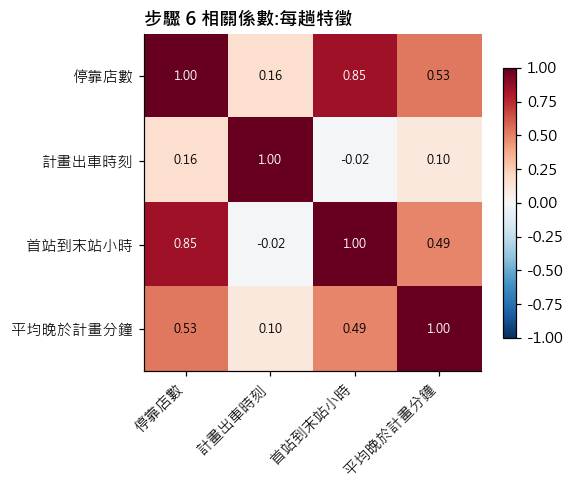

高度相關(|r| > 0.7)的欄位組合(相關不代表因果):
  停靠店數 ↔ 首站到末站小時:r = 0.85
步驟 7 偏態


,偏態,判讀
停靠店數,0.01,左右大致對稱
計畫出車時刻,0.13,左右大致對稱
首站到末站小時,0.19,左右大致對稱
平均晚於計畫分鐘,0.03,左右大致對稱


In [15]:
# 本資料沒有數值量測欄,改以「趟」為單位彙整出數值特徵
st["trip"] = st["Delivery_Dt"] + "|" + st["Car_licence"] + "|" + st["Route_seq"].str[:2] + "|" + st["TaskType_id"]
trips = st.groupby("trip").agg(停靠店數=("Store_id", "size"), 計畫出車時刻=("plan", lambda s: s.min().hour + s.min().minute / 60),
                               首站到末站小時=("act", lambda s: (s.max() - s.min()).total_seconds() / 3600),
                               平均晚於計畫分鐘=("act", "min")).copy()
trips["平均晚於計畫分鐘"] = st.assign(late=(st["act"] - st["plan"]).dt.total_seconds() / 60).groupby("trip")["late"].mean()
trips = trips[trips["首站到末站小時"].between(0, 16)]
print(f"步驟 5 描述統計(以趟為單位,共 {len(trips):,} 趟)"); display(trips.describe().T.round(2))
corr_heat(trips, "步驟 6 相關係數:每趟特徵", figsize=(5.5, 4.5))
print("步驟 7 偏態"); display(skew_table(trips))

**判讀:**
- 配送計畫本身**沒有數值量測欄位**(全是代碼與時間),所以第 5–7 步改用「每一趟」彙整出的特徵。
- **主鍵檢查:** 以(日期、車號、路線站序、門市)判斷有 108 列重複(約 0.03%),沒有完全相同的列,影響很小。
- **停靠店數**與**首站到末站時間**高度相關(r = 0.85):停越多店,一趟跑越久。
- 每趟停靠店數中位數 20 家,首站到末站約 2 小時。
- **實際到店平均比 `Pl_M_Arrive_dt` 晚約 2.5 小時**(中位數 156 分鐘):這個欄位是整趟在物流中心的計畫時間(助教說明為計畫的 DC 到場/備車時間,每趟一個),同一趟每家店都一樣,**不是逐店的到店時間**。逐店的準點表現要改用 TMS 的表訂時間。
- **缺值:** 實際到店時間 `Ac_Arrive_dt_02` 在門市列缺約 6%,依任務不同(A2/A3 全缺,因為沒派車)。

In [16]:
show_issues("delivery_plan")

等級,問題,說明
🔵 說明,重複列,"完全相同的列 0;以 (日期, 任務, Route_seq, 車, 店) 為鍵重複 0 列。"
🟠 注意,實際到達時間缺失,"門市停靠列中 Ac_Arrive_dt_02 缺失 5.9%(18,294 / 311,302)。依任務類型:02: 2%, 03: 3%, 04: 13%, 05: 4%, 12: 8%, A2: 100%, A3: 100%, A4: 55%"
🔵 說明,日期缺口,"2024-01-01 ~ 2025-03-31 共 456 天,無任何資料的日子 0 天"
🔵 說明,零星任務類型 A2/A3/A4,"A2: 13 列、0 輛車、2024-01-04~2024-06-08; A3: 36 列、0 輛車、2025-01-06~2025-01-06; A4: 780 列、11 輛車、2024-09-16~2025-03-29 —— A2/A3 未指派車輛、實際到達全缺;A4 自 2024-09 起才出現。三者合計不到總列數 0.3%,主分析可只取 02/03/04/05/12。"
🟠 注意,店號與店名一致性,"同一 Store_id 對應多個店名:1 個;同一店名對應多個 Store_id:128 個(如「七堵長安店」,多為門市換號/重新開店)。以門市為單位彙總時,請用店名或建立對照表,不要只用 Store_id。"
🔵 說明,Pl_M_Arrive_dt 的意義,"同一趟(日期×任務×路線×車)內 Pl_M_Arrive_dt 只有 1 個值的比例 95.4% —— 是整趟的計畫出發/備車時間,不是逐店計畫時間。"
🔵 說明,實際到店早於整趟計畫時間,1.0% 的停靠實際到達早於 Pl_M_Arrive_dt;到達−計畫 中位數 166 分、p99 365 分、最大 1653 分。
🔵 說明,停靠順序,"35.6% 的趟次,實際到達順序與 Route_seq 編號順序不一致(司機調整順序,或編號不代表行駛順序)。"
🟠 注意,與 store_master 的連結,"Store_id 與 商店編號 是不同編碼系統,只能用店名對應;去掉「全家/店」後可對上 80% 的店名(698 個中)。"
🟠 注意,by_vehicle / by_task_type 與 monthly 的關係,"by_vehicle 1,149,732 列,其中 100.0% 可在 monthly 找到相同紀錄、自身重複 69.9%;by_task_type 228,685 列,100.0% 在 monthly 中。→ 分析請只用 monthly。"


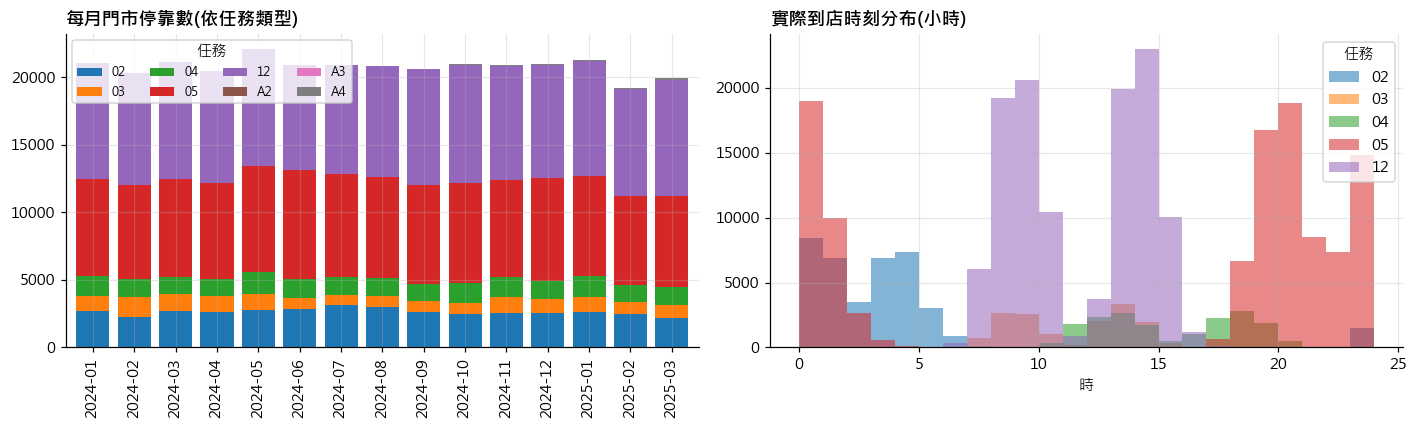

In [17]:
st["month"] = st["date"].dt.to_period("M").astype(str)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
st.groupby(["month", "TaskType_id"]).size().unstack(fill_value=0).plot.bar(stacked=True, ax=axes[0], width=0.8)
axes[0].set_title("每月門市停靠數(依任務類型)", loc="left", fontweight="bold"); axes[0].set_xlabel(""); axes[0].legend(title="任務", ncols=4, fontsize=8)
hr = st.dropna(subset=["act"])
for t in ["02", "03", "04", "05", "12"]:
    axes[1].hist(hr.loc[hr["TaskType_id"] == t, "act"].dt.hour, bins=range(25), alpha=0.55, label=t)
axes[1].set_title("實際到店時刻分布(小時)", loc="left", fontweight="bold"); axes[1].set_xlabel("時"); axes[1].legend(title="任務")
plt.tight_layout(); plt.show()

## 5. TMS 配送紀錄 tms_delivery_records

| 項目 | 內容 |
|---|---|
| 用途 | 逐店準點分析(表訂 vs 實際)、車廂溫度 |
| 一列代表 | 一趟配送中的一站(出發 DC 列 `last_dc` 空、回場列 = 1、門市列 = 0) |
| 範圍 | **只有任務 12**(早班);期間比配送計畫長,到 2026 年 1 月 |
| 主鍵 | 自然鍵(配送日、車號、路線站序、門市),檢查結果見下方 |
| 建議分組欄 | 準點狀態 `DiffStatus`、車號 `Car_id`、路線 `Route_id` |
| 量測值 | 實際 − 表訂 `Ex_Arrive_diff`(分鐘)、車廂溫度 `Temperature1` |
| 注意 | 與配送計畫的任務 12 是同一份資料(每日停靠數完全相同);同一欄位有多個副本(`_01`、`_02`、`In_`);實際到店時間有 4,073 組可疑的共用時間戳(見下方驗證) |

In [18]:
display(Markdown(f"**一列代表:** {R['tms']['grain']}  **全資料:** {R['tms']['rows']:,} 列 × {R['tms']['cols']} 欄"))
col_table(R["tms"]["profile"], "tms")

**一列代表:** 一列 = 一趟配送中的一站(含出發 DC 列 last_dc 空、回場 last_dc=1)  **全資料:** 220,584 列 × 41 欄

類型,欄位,說明,完整度,相異值,範圍或常見值
🔑 識別碼,Store_id,門市代碼(同 delivery_plan),🟢 完整(缺 0.0%),760,"1,001,010,822 ~ 3,001,888,888(中位數 1,001,021,233)"
🔑 識別碼,Route_id,路線代碼(如 QC、SI),🟢 完整(缺 0.0%),55,QJ (9%) | QI (8%) | SJ (8%) | SI (8%)
🔑 識別碼,Route_id1,與 Route_id 完全相同(冗餘),🟢 完整(缺 0.0%),55,QJ (9%) | QI (8%) | SJ (8%) | SI (8%)
🔑 識別碼,Route_seq,路線 + 站序;<路線>DC = 物流中心列,🟢 完整(缺 0.0%),655,SHDC (1%) | QHDC (1%) | QCDC (1%) | SJDC (1%)
🔑 識別碼,Car_id,車輛代碼;ZZ1xx = 臨時外調車,🟢 完整(缺 0.0%),26,V06 (12%) | V14 (12%) | V07 (12%) | V04 (11%)
🔑 識別碼,Store_Name,門市名稱,🟢 完整(缺 0.0%),562,瑞芳ＤＣ (9%) | 文湖店 (0%) | 金瑞店 (0%) | 麗山店 (0%)
🔑 識別碼,Car_licence,"車牌代碼,去識別化為 V##,共 18 種〔助教〕;97% 列與 Car_id 相同(外調車 ZZ 例外)",🟢 完整(缺 0.0%),18,V06 (12%) | V14 (12%) | V07 (12%) | V04 (12%)
🕒 時間,Pl_M_Arrive_dt,計畫的 DC 到場/備車時間(每趟一個)〔助教〕;與 Ac_M_Arrive_dt 比較判斷是否延遲發車,🟢 完整(缺 0.0%),"2,648",2024-01-01 06:00:00 ~ 2026-01-16 11:30:00(中位數 )
🕒 時間,Ac_Arrive_dt_02,與 Ac_Arrive_dt_01 相同(冗餘),🟠 不完整(缺 8.2%),"189,179",2024-01-01 07:01:16 ~ 2026-01-16 16:24:15(中位數 )
🕒 時間,Pl_Arrive_dt_01,"與 Pl_Arrive_dt 相同,ISO 格式",🟢 完整(缺 0.0%),"200,392",2024-01-01 05:58:58 ~ 2026-01-16 16:23:49(中位數 )


In [19]:
t0 = time.time()
tm = pd.concat([read(f) for f in sorted(glob.glob(P("tms_delivery_records", "**", "*.csv"), recursive=True))], ignore_index=True)
print(f"讀取 {time.time() - t0:.0f} 秒")
print("步驟 1 Peek"); display(peek(tm, 3))
print("步驟 2 Dimensions:", tm.shape)
print("步驟 3 Data types"); display(dtype_table(tm, "tms"))

讀取 10 秒
步驟 1 Peek


,last_dc,Store_id,PLDT,Ex_Arrive_diff,InTime,Pl_M_Arrive_dt,Dept,Route_id,Order_Index,Route_Name,Temperature2,Temperature1,In_Temperature2,OnTime,Ac_Arrive_dt_02,Route_id1,Pl_Arrive_dt_01,Ac_Arrive_dt,Route_seq,Car_id,Store_Name,Delivery_date,onlinetel,DiffStatus,Ex_M_Arrive_diff,TaskType_id,Ac_Arrive_dt_01,mDiffStatus,Car_licence,tel,START_TIME,Pl_Arrive_dt,Arrive_dt,Dept_Name,Ac_M_Arrive_dt,Im_Arrive_dt,Emp_tel,Im_arrive_dt_02,Emp_name,OutTime,In_Temperature1
0,NaN,S3001888888,NaN,NaN,-60,2024-01-01 07:00:00,RF,QC,-1,Carrier_A,NaN,NaN,NaN,0,NaN,QC,2024-01-01 06:03:27,NaN,QCDC,V07,瑞芳ＤＣ,1/1/2024 12:00:00 AM,(個資遮蔽),NaN,-52.0,12,NaN,0.0,V07,(個資遮蔽),07:30,1/1/2024 6:03:27 AM,2024-01-01 06:03:27,瑞芳DC,NaN,NaN,(個資遮蔽),NaN,(個資遮蔽),30,NaN
1,0.0,1001021426,0.0,-71.0,-60,2024-01-01 07:00:00,RF,QC,1,Carrier_A,NaN,16.3,NaN,0,2024-01-01 07:49:10,QC,2024-01-01 07:49:10,1/1/2024 7:49:10 AM,QC02,V07,敦安店,1/1/2024 12:00:00 AM,(個資遮蔽),-1.0,-52.0,12,2024-01-01 07:49:10,0.0,V07,(個資遮蔽),07:30,1/1/2024 7:49:10 AM,2024-01-01 07:49:10,瑞芳DC,NaN,1/1/2024 9:00:00 AM,(個資遮蔽),2024-01-01 09:00:00,(個資遮蔽),30,16.3
2,0.0,1001016909,0.0,-60.0,-60,2024-01-01 07:00:00,RF,QC,2,Carrier_A,NaN,16.3,NaN,0,2024-01-01 08:05:19,QC,2024-01-01 08:05:19,1/1/2024 8:05:19 AM,QC03,V07,和信店,1/1/2024 12:00:00 AM,(個資遮蔽),0.0,-52.0,12,2024-01-01 08:05:19,0.0,V07,(個資遮蔽),07:30,1/1/2024 8:05:19 AM,2024-01-01 08:05:19,瑞芳DC,NaN,1/1/2024 9:05:00 AM,(個資遮蔽),2024-01-01 09:05:00,(個資遮蔽),30,16.3


步驟 2 Dimensions: (220584, 41)
步驟 3 Data types


,欄位,pandas 型態,說明
0,last_dc,float64,"列類型:0 = 門市停靠,1 = 回場 DC,空 = 出發 DC"
1,Store_id,object,門市代碼(同 delivery_plan)
2,PLDT,float64,實際 − 預計 Ac_Arrive_dt − Pl_Arrive_dt(分鐘)〔助教〕
3,Ex_Arrive_diff,float64,實際 − 表訂 Ac_Arrive_dt − Im_Arrive_dt(分鐘)〔助教〕★準點指標;負 = 早到
4,InTime,int64,"允收時窗下限,固定 -60 分〔助教引 AI〕"
5,Pl_M_Arrive_dt,object,計畫的 DC 到場/備車時間(每趟一個)〔助教〕;與 Ac_M_Arrive_dt 比較判斷是否延遲發車
6,Dept,object,"物流中心代碼,全部 RF(瑞芳)"
7,Route_id,object,路線代碼(如 QC、SI)
8,Order_Index,int64,趟內停靠順序;-1 = 出發 DC 列
9,Route_Name,object,"承運商名稱(已去識別化)〔助教〕,全部 Carrier_A"


In [20]:
ts = tm[tm["last_dc"] == 0].copy()   # 只看門市停靠列
print(f"門市停靠列 {len(ts):,} 筆")
key = ["Delivery_date", "Car_licence", "Route_seq", "Store_id"]
print(f"主鍵檢查:以 {key} 判斷,門市列重複 {ts.duplicated(key).sum():,} 列")
print("步驟 4 類別分布")
display(vc(ts["DiffStatus"].map({-1: "早到(早 60 分以上)", 0: "準時", 1: "遲到(晚 30 分以上)"}), name="到店準點狀態"))
display(vc(tm["last_dc"].map({0: "門市停靠", 1: "回場 DC"}), name="列類型"))
display(vc(ts["Car_id"].astype(str).str.startswith("ZZ").map({True: "臨時外調車 ZZ", False: "自有車 V"}), name="車輛來源"))

門市停靠列 200,766 筆
主鍵檢查:以 ['Delivery_date', 'Car_licence', 'Route_seq', 'Store_id'] 判斷,門市列重複 0 列
步驟 4 類別分布


,筆數,比例
到店準點狀態,,
準時,142318,70.9%
早到(早 60 分以上),50514,25.2%
(空),6551,3.3%
遲到(晚 30 分以上),1383,0.7%


,筆數,比例
列類型,,
門市停靠,200766,91.0%
(空),9909,4.5%
回場 DC,9909,4.5%


,筆數,比例
車輛來源,,
自有車 V,195145,97.2%
臨時外調車 ZZ,5621,2.8%


**判讀(類別不平衡):** 準點狀態明顯不平衡,大多數停靠為「準時」,約四分之一「早到」,「遲到」很少。若要建模預測遲到,遲到樣本極少,不能只看整體準確率(全部猜準時也有很高的準確率),要看召回率與精確率。

步驟 5 描述統計


,count,mean,std,min,25%,50%,75%,max
Ex_Arrive_diff,194214.0,-55.28,31.94,-1327.0,-61.0,-57.0,-47.0,1348.0
PLDT,187799.0,18.33,37.88,-1142.0,0.0,1.0,33.0,298.0
Order_Index,200765.0,11.39,6.54,1.0,6.0,11.0,17.0,29.0
Temperature1,185599.0,17.28,1.77,-38.9,16.6,17.3,18.0,48.8


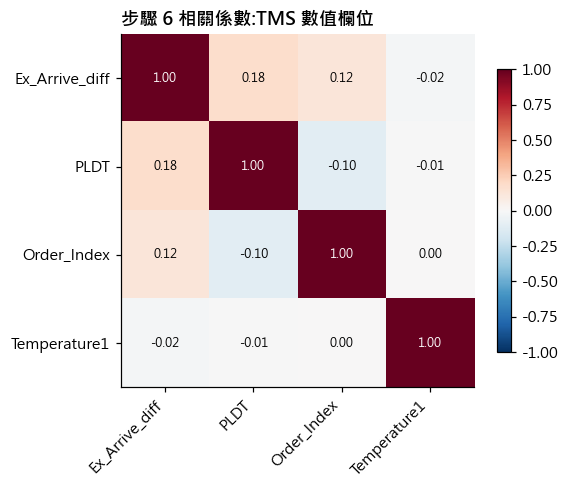

沒有 |r| > 0.7 的欄位組合。
步驟 7 偏態


,偏態,判讀
Ex_Arrive_diff,2.22,嚴重右偏
PLDT,0.63,右偏(右側長尾)
Order_Index,0.13,左右大致對稱
Temperature1,-4.52,嚴重左偏


In [21]:
tn = num(ts, ["Ex_Arrive_diff", "PLDT", "Order_Index", "Temperature1"])
tn = tn[tn["Temperature1"].between(-40, 50) | tn["Temperature1"].isna()]
print("步驟 5 描述統計"); display(tn.describe().T.round(2))
corr_heat(tn.dropna(), "步驟 6 相關係數:TMS 數值欄位", figsize=(5.5, 4.5))
print("步驟 7 偏態"); display(skew_table(tn))

**判讀:**
- `Ex_Arrive_diff` 是**實際 − 表訂**(分鐘),是逐店準點最好用的欄位;中位數 −57 分鐘,表示多數門市在表訂時間前約一小時到達,剛好落在準時窗口(−60~+30 分)的前緣,所以「早到」比例高達四分之一。`PLDT` 是實際 − 預計。
- `Temperature1` 嚴重左偏:絕大多數在 16–18°C,少數異常低溫(最低 −38.9°C)拉出左側長尾,推測為感測器異常,分析前要剔除。
- **「預計到達」約 27% 剛好等於實際到達**,疑為事後回填,分析準點請用「表訂」(`Im_Arrive_dt`)。
- `Temperature1` 是車廂溫度,中位數約 17°C;`Temperature2` 幾乎全空(99.9%),視為不存在。

### 助教說法驗證:TMS 欄位定義

助教回答了 TMS 幾乎每個欄位。下表逐項用全部 22 萬列檢查:差值欄用時間欄重算,看是否在 1 分鐘內吻合(原始差值有小數,重算有秒級誤差);旗標欄用助教說的規則重新判定;重複欄逐列比對。

In [22]:
T = lambda c: pd.to_datetime(tm[c], errors="coerce", format="mixed")
ac, im, pl, acm, plm = T("Ac_Arrive_dt_01"), T("Im_arrive_dt_02"), T("Pl_Arrive_dt_01"), T("Ac_M_Arrive_dt"), T("Pl_M_Arrive_dt")

def within1(calc, col):
    v = pd.to_numeric(tm[col], errors="coerce"); m = calc.notna() & v.notna()
    return f"{((calc[m] - v[m]).abs() <= 1).mean():.2%} 吻合(n = {m.sum():,})"

def rule(diff, flag, rows=slice(None)):
    d = pd.to_numeric(tm.loc[rows, diff], errors="coerce"); f = tm.loc[rows, flag]; m = d.notna() & f.notna()
    return f"{(np.select([d[m] < -60, d[m] > 30], [-1, 1], 0) == f[m]).mean():.2%} 重現(n = {m.sum():,})"

def same(a, b, parse=False):
    x, y = (T(a), T(b)) if parse else (tm[a], tm[b])
    return f"{((x == y) | (x.isna() & y.isna())).mean():.2%} 相同"

stop = tm["last_dc"] == 0
imd = im[stop].dropna()
tod_n = imd.dt.strftime("%H:%M").groupby(tm.loc[imd.index, "Store_id"]).nunique()
chk = [
    ("PLDT", "Ac_Arrive_dt − Pl_Arrive_dt", within1((ac - pl).dt.total_seconds() / 60, "PLDT")),
    ("Ex_Arrive_diff", "Ac_Arrive_dt − Im_Arrive_dt", within1((ac - im).dt.total_seconds() / 60, "Ex_Arrive_diff")),
    ("Ex_M_Arrive_diff", "Ac_M_Arrive_dt − Pl_M_Arrive_dt", within1((acm - plm).dt.total_seconds() / 60, "Ex_M_Arrive_diff")),
    ("DiffStatus", "依 Ex_Arrive_diff 與 [-60, +30] 判斷", rule("Ex_Arrive_diff", "DiffStatus", stop)),
    ("mDiffStatus", "依 Ex_M_Arrive_diff 與 [-60, +30] 判斷", rule("Ex_M_Arrive_diff", "mDiffStatus")),
    ("InTime / OutTime / OnTime", "恆為 -60 / 30 /(不知道)",
     " / ".join(str(sorted(tm[c].dropna().unique().tolist())) for c in ["InTime", "OutTime", "OnTime"])),
    ("Dept / TaskType_id / Route_Name", "恆為 RF / 12 / 承運商(去識別)",
     " / ".join(str(sorted(tm[c].dropna().astype(str).unique().tolist())) for c in ["Dept", "TaskType_id", "Route_Name"])),
    ("last_dc", "0 門市、1 回場、空 出場",
     f"空白列的 Order_Index 全為 -1:{(tm.loc[tm['last_dc'].isna(), 'Order_Index'] == -1).all()};"
     f"回場列 Store_id 全為 3001888888:{tm.loc[tm['last_dc'] == 1, 'Store_id'].astype(str).eq('3001888888').all()}"),
    ("Ac_Arrive_dt_01 / _02", "與 Ac_Arrive_dt 相同", same("Ac_Arrive_dt", "Ac_Arrive_dt_01", True) + " / " + same("Ac_Arrive_dt_01", "Ac_Arrive_dt_02", True)),
    ("Pl_Arrive_dt_01 / Arrive_dt", "與 Pl_Arrive_dt 相同", same("Pl_Arrive_dt", "Pl_Arrive_dt_01", True) + " / " + same("Pl_Arrive_dt", "Arrive_dt", True)),
    ("Im_arrive_dt_02", "與 Im_Arrive_dt 相同", same("Im_Arrive_dt", "Im_arrive_dt_02", True)),
    ("Route_id1 / In_Temperature1", "與 Route_id / Temperature1 相同", same("Route_id", "Route_id1") + " / " + same("Temperature1", "In_Temperature1")),
    ("Pl_Arrive_dt 回填", "停靠完成後常回填成實際", f"{(pl[stop] == ac[stop]).mean():.1%} 的門市列預計 = 實際"),
    ("Im_Arrive_dt 網格", "整分、5 分鐘網格", f"{((imd.dt.minute % 5 == 0) & (imd.dt.second == 0)).mean():.2%} 落在 5 分鐘網格"),
    ("Im_Arrive_dt 固定", "每家門市固定的配送時刻、跨日穩定",
     f"只有一種時刻的門市 {(tod_n == 1).mean():.0%};每店時刻數中位數 {tod_n.median():.0f}、最多 {tod_n.max()}"),
    ("Car_licence / Emp_name", "18 種 V## / Driver_01–29", f"{tm['Car_licence'].nunique()} 種 / {tm['Emp_name'].nunique()} 種(姓名不顯示)"),
]
pd.DataFrame(chk, columns=["欄位", "助教說法", "實測"]).style.hide(axis="index").set_properties(**{"text-align": "left"})

欄位,助教說法,實測
PLDT,Ac_Arrive_dt − Pl_Arrive_dt,"100.00% 吻合(n = 202,425)"
Ex_Arrive_diff,Ac_Arrive_dt − Im_Arrive_dt,"99.99% 吻合(n = 196,745)"
Ex_M_Arrive_diff,Ac_M_Arrive_dt − Pl_M_Arrive_dt,"99.55% 吻合(n = 173,233)"
DiffStatus,"依 Ex_Arrive_diff 與 [-60, +30] 判斷","100.00% 重現(n = 194,215)"
mDiffStatus,"依 Ex_M_Arrive_diff 與 [-60, +30] 判斷","100.00% 重現(n = 211,901)"
InTime / OutTime / OnTime,恆為 -60 / 30 /(不知道),[-60] / [30] / [0]
Dept / TaskType_id / Route_Name,恆為 RF / 12 / 承運商(去識別),['RF'] / ['12'] / ['Carrier_A']
last_dc,0 門市、1 回場、空 出場,空白列的 Order_Index 全為 -1:True;回場列 Store_id 全為 3001888888:True
Ac_Arrive_dt_01 / _02,與 Ac_Arrive_dt 相同,100.00% 相同 / 100.00% 相同
Pl_Arrive_dt_01 / Arrive_dt,與 Pl_Arrive_dt 相同,100.00% 相同 / 100.00% 相同


**判讀:** 助教對差值欄、準點旗標、重複欄的說明**全部吻合**,可以放心使用:準點一律用 `Ex_Arrive_diff`(或 `DiffStatus`),時間欄只需留 ISO 格式的 `_01`/`_02` 版本。唯一不符的是「表訂時間每店固定」:同一家店在兩年間常有 2–3 種表訂時刻(路線調整或班表變動),**做門市收貨時間窗時要依期間分開算**,不能每店只取一個值。

### 助教說法驗證:可疑的共用時間戳

助教(轉述 AI)提醒:有 **4,073 組「同一趟中不相鄰、不同門市卻共用同一秒」**的實際到店時間。正常情況下,車子不可能同一秒出現在兩家不相鄰的門市,這類紀錄多半是司機事後批次補按到店。下面重現這個檢查,並標出受影響的列。

In [23]:
s = tm[stop].copy()
s["ac"] = ac[stop]
s["trip"] = s["Delivery_date"].astype(str) + "|" + s["Car_id"].astype(str) + "|" + s["Route_id"].astype(str)
g = s.dropna(subset=["ac"])
multi = g[g.groupby(["trip", "ac"])["Store_id"].transform("nunique") > 1]
flag = multi.groupby(["trip", "ac"])["Order_Index"].apply(lambda o: bool((np.diff(np.sort(o.values)) > 1).any()))
bad = flag[flag].index
s["shared_ts"] = s.set_index(["trip", "ac"]).index.isin(bad)
print(f"同趟、同一秒、不同門市的組數:{len(flag):,};其中停靠順序不相鄰:{len(bad):,} 組(助教說 4,073 組)")
print(f"受影響門市列 {s['shared_ts'].sum():,} 筆(占門市列 {s['shared_ts'].mean():.1%}),"
      f"分布在 {s.loc[s['shared_ts'], 'trip'].nunique():,} 趟(占全部 {s['trip'].nunique():,} 趟的 {s.loc[s['shared_ts'], 'trip'].nunique() / s['trip'].nunique():.1%})")
display(vc(s.loc[s["shared_ts"], "Car_id"], n=8, name="受影響列最多的車輛"))

同趟、同一秒、不同門市的組數:11,474;其中停靠順序不相鄰:4,073 組(助教說 4,073 組)
受影響門市列 8,314 筆(占門市列 4.1%),分布在 3,179 趟(占全部 9,909 趟的 32.1%)


,筆數,比例
受影響列最多的車輛,,
V06,1156,13.9%
V07,1065,12.8%
V08,909,10.9%
V19,889,10.7%
V04,869,10.5%
V14,865,10.4%
V15,835,10.0%
V13,519,6.2%


**判讀:** 4,073 組完全重現,影響約 4% 的門市列,但分散在約三分之一的趟次。相鄰兩站共用同一秒還可能是門市緊鄰,但不相鄰的站共用同一秒一定不是真實到店時間。**算站間行駛時間、在店停留時間時,要先排除 `shared_ts` 標記的列**;算準點率影響較小,但仍建議做一次排除後的敏感度比較。

In [24]:
show_issues("tms")

等級,問題,說明
🟠 注意,日期缺口,"2024-01-01 ~ 2026-01-16 共 747 天、741 個檔;缺 6 天:2026-01-01, 2026-01-02, 2026-01-03, 2026-01-04, 2026-01-10, 2026-01-11"
🔵 說明,重複列,除 source_file 外完全相同的列 0。
🔵 說明,冗餘欄位(兩兩相同比例),Route_id≡Route_id1: 100.0%; Temperature1≡In_Temperature1: 100.0%; Temperature2≡In_Temperature2: 100.0%; Ac_Arrive_dt_01≡Ac_Arrive_dt_02: 100.0%; Ac_Arrive_dt_01≡Ac_Arrive_dt: 100.0%; Pl_Arrive_dt_01≡Pl_Arrive_dt: 100.0%; Pl_Arrive_dt_01≡Arrive_dt: 100.0%; Im_arrive_dt_02≡Im_Arrive_dt: 100.0%
🔵 說明,Ex_Arrive_diff 重算驗證,"以 實際 − 表訂(缺則預計) 重算,誤差 ≤1 分的比例 100.0%。"
🔵 說明,"DiffStatus 與窗口 (−60, +30) 一致性",100.0%
🔴 嚴重,「預計到達」= 實際到達,"Pl_Arrive_dt 與 Ac_Arrive_dt 完全相同的比例 27.3%,PLDT=0 的比例 32.2% —— 預計時間似乎是事後回填,不能當成獨立的計畫值;請用 Im_Arrive_dt(表訂)。"
🔵 說明,表訂時間缺失,"門市停靠列中 Im_arrive_dt_02 缺失 0.0%(此時 Ex_Arrive_diff 改用預計時間計算,等於 0)。"
🟠 注意,實際到達缺失,門市停靠列中 6.5%。
🔵 說明,外包車輛代碼,"Car_id 為 ZZ1xx(臨時外調車)的列 2.8%,共 11 個代碼。"
🔵 說明,Car_id vs Car_licence,不相同的列 2.8%。


C:\Users\a0903\AppData\Local\Temp\ipykernel_20408\3333194826.py:1: UserWarning:

Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.



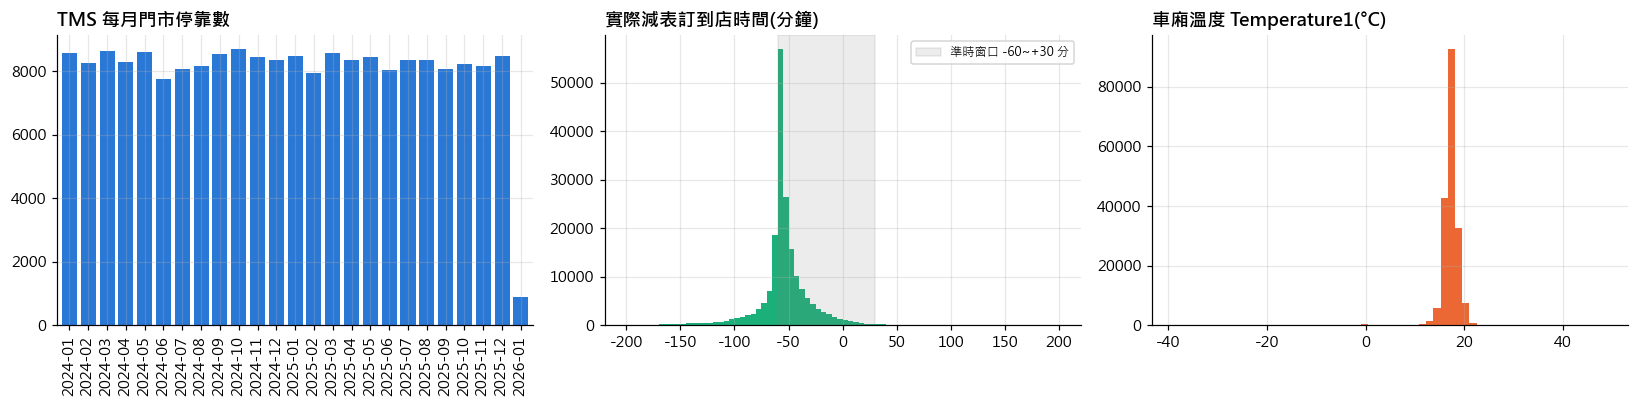

In [25]:
ts["date"] = pd.to_datetime(ts["Delivery_date"], errors="coerce")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
ts.groupby(ts["date"].dt.to_period("M").astype(str)).size().plot.bar(ax=axes[0], color="#2a78d6", width=0.8)
axes[0].set_title("TMS 每月門市停靠數", loc="left", fontweight="bold"); axes[0].set_xlabel("")
x = tn["Ex_Arrive_diff"].dropna(); axes[1].hist(x[x.between(-200, 200)], bins=80, color="#1baf7a")
axes[1].axvspan(-60, 30, color="grey", alpha=0.15, label="準時窗口 -60~+30 分"); axes[1].legend(fontsize=8)
axes[1].set_title("實際減表訂到店時間(分鐘)", loc="left", fontweight="bold")
tt = tn["Temperature1"].dropna(); axes[2].hist(tt, bins=60, color="#eb6834")
axes[2].set_title("車廂溫度 Temperature1(°C)", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 6. GPS 軌跡 gps_traces

| 項目 | 內容 |
|---|---|
| 用途 | 逐秒軌跡、停等與駕駛行為、2024 vs 2025 同期比較 |
| 一列代表 | V13 的一筆定位紀錄(約每秒);每列並排兩套系統:TransIOT(`GPS時間`、`速度`…)與天眼(`時間`、`時速`、`狀態`…) |
| 範圍 | **只有 V13 一輛車**;2024 與 2025 年各 3–4 月,一天一個檔(助教說明:來源網站資料有時效性,當時手動爬取,量夠就停,所以只有這兩段) |
| 建議分組欄 | 天眼車輛狀態 `狀態`、事件 `事件`、任務 `任務`(只有 2024 年) |
| 量測值 | 瞬時車速 `速度`(km/h)、累計里程 `路程`(**單位 km**,助教確認;當日最大 − 最小 = 當日里程)、車廂溫度 `Air`、車輛電瓶電壓 `汽車電瓶` |
| 注意 | `燃料` 是**油箱油位百分比,不是油耗**(助教確認):由油箱頂部紅外線測油面深度換算,行駛晃動會有誤差。GPS 檔不能用來算油耗 |

In [26]:
display(Markdown(f"**一列代表:** {R['gps_traces']['grain']}  **全資料:** {R['gps_traces']['rows']:,} 列"))
for y in ["2024", "2025"]:
    d = R["gps_traces"]["profiles"][y]
    display(Markdown(f"#### {y} 年檔案({d['files']} 個檔、{d['total']:,} 列)"))
    display(col_table(d["profile"], "gps_traces"))

**一列代表:** 一列 = V13 的一筆 GPS 紀錄(約每秒,兩套系統併列)  **全資料:** 2,596,325 列

#### 2024 年檔案(58 個檔、2,364,919 列)

類型,欄位,說明,完整度,相異值,範圍或常見值
🔑 識別碼,設備名稱,"追蹤器名稱,如 (V13)/82-(V13)",🟢 完整(缺 0.0%),1,82-(V13) (100%)
🔑 識別碼,#,第二套 GPS(天眼)的列序號,🟢 完整(缺 0.0%),"3,624",1 ~ 3649(中位數 959)
🕒 時間,GPS時間,GPS 定位時間 ★主要時間欄,🟢 完整(缺 0.0%),"118,269",2024-03-02 17:32:13 ~ 2024-04-30 16:41:09(中位數 )
🕒 時間,接收時間,伺服器收到資料的時間(通常晚幾秒),🟢 完整(缺 0.0%),"118,023",2024-03-02 17:32:25 ~ 2024-04-30 16:41:12(中位數 )
🕒 時間,時間,"天眼系統時間戳(對齊到最近一筆,不一定同秒)",🟢 完整(缺 0.0%),"85,930",2024-03-02 17:32:11 ~ 2024-04-30 16:41:06(中位數 )
🏷️ 類別,GPS有效性,定位是否有效:有效 / 無效(算距離前要排除無效點),🟢 完整(缺 0.0%),2,有效 (97%) | 無效 (3%)
🏷️ 類別,方向,"行進方位(8 方位文字,如 東南)",🟢 完整(缺 0.0%),8,西 (17%) | 東 (17%) | 西南 (12%) | 西北 (12%)
🏷️ 類別,設備電池,"追蹤器內建電池(單位不明,多為 0.01–0.03;助教也只能推測)",🟢 完整(缺 0.0%),4,0 ~ 0.03(中位數 0.02)
🏷️ 類別,目前使用網路資訊,追蹤器連線方式(4G / 無),🟢 完整(缺 0.0%),3,行動網路(4G) (97%) | Nothing(NULL) (3%) | 行動網路(3G) (0%)
🏷️ 類別,Camera access information,行車攝影機連線狀態(CH1/CH2 是否連線),🟡 大致完整(缺 2.9%),2,"CH1 Disconnected,CH2 Con (100%) | CH1 Disconnected,CH2 Dis ("


#### 2025 年檔案(58 個檔、231,406 列)

類型,欄位,說明,完整度,相異值,範圍或常見值
🔑 識別碼,設備名稱,"追蹤器名稱,如 (V13)/82-(V13)",🟢 完整(缺 0.0%),1,(V13) (100%)
🔑 識別碼,#,第二套 GPS(天眼)的列序號,🟢 完整(缺 0.1%),"1,219","-15,522 ~ 3,009,099(中位數 -7,729)"
🕒 時間,GPS時間,GPS 定位時間 ★主要時間欄,🟢 完整(缺 0.0%),"11,603",2025-03-01 05:52:22 ~ 2025-04-30 17:10:51(中位數 )
🕒 時間,接收時間,伺服器收到資料的時間(通常晚幾秒),🟢 完整(缺 0.0%),"11,603",2025-03-01 05:52:39 ~ 2025-04-30 17:10:53(中位數 )
🕒 時間,時間,"天眼系統時間戳(對齊到最近一筆,不一定同秒)",🟢 完整(缺 0.1%),"11,588",2025-03-01 05:52:20 ~ 2025-04-30 17:10:43(中位數 )
🏷️ 類別,GPS有效性,定位是否有效:有效 / 無效(算距離前要排除無效點),🟢 完整(缺 0.0%),2,有效 (96%) | 無效 (4%)
🏷️ 類別,方向,"行進方位(8 方位文字,如 東南)",🟢 完整(缺 0.0%),8,西 (19%) | 東 (18%) | 西南 (12%) | 南 (12%)
🏷️ 類別,訊號強度,行動網路訊號強度(0–31),🟢 完整(缺 0.0%),29,0 ~ 30(中位數 16)
🏷️ 類別,設備電池,"追蹤器內建電池(單位不明,多為 0.01–0.03;助教也只能推測)",🟢 完整(缺 0.0%),4,0 ~ 0.03(中位數 0.02)
🏷️ 類別,目前使用網路資訊,追蹤器連線方式(4G / 無),🟢 完整(缺 0.0%),2,Mobile network(4G) (99%) | Nothing(NULL) (1%)


步驟 1–7 使用 **2025 年 3–4 月全部 58 個日檔**(約 23 萬列);2024 年檔案較大(約 236 萬列),只用於下方的每日里程圖。

In [27]:
g25 = pd.concat([read(f) for f in sorted(glob.glob(P("gps_traces", "2025-*", "*.csv")))], ignore_index=True)
print("步驟 1 Peek"); display(peek(g25, 3))
print("步驟 2 Dimensions:", g25.shape)
print("步驟 3 Data types"); display(dtype_table(g25, "gps_traces"))

步驟 1 Peek


,駕駛,車牌號碼,處別,部門,設備名稱,綁定圍籬名稱,GPS時間,接收時間,GPS有效性,速度,緯度,經度,事件,海拔,方向,角度,衛星數量,訊號強度,路程,運行時間,設備電池,汽車電瓶,Air,Back door,Left,Right door,燃料,實際緩速器百分比扭矩,目前使用網路資訊,Camera access information,前車距離(CM),核選,#,時間,時速,狀態,位置,任務
0,(個資遮蔽),(個資遮蔽),NaN,NaN,(V13),NaN,2025-03-01 05:52:22,2025-03-01 05:52:39,有效,0.0,25.101132,121.772832,ACC ON,99,西北,321,24,12,107615.1,646day(s)11:42:22,0.02,25.17,13.31,19.50,19.81,19.87,89.66,-1,Mobile network(4G),"CH1 Disconnected,CH2 Connected,CH3 Connected,CH4 Disconnected",NaN,NaN,-8581.0,2025-03-01 05:52:20,0.0,引擎起動,新北市瑞芳區 瑞芳ＤＣ,NaN
1,(個資遮蔽),(個資遮蔽),NaN,NaN,(V13),NaN,2025-03-01 05:52:24,2025-03-01 05:52:39,有效,0.0,25.101132,121.772832,Input 1 Inactive,99,西北,321,24,12,107615.1,646day(s)11:42:22,0.02,26.32,11.87,18.00,18.25,18.37,89.39,-1,Mobile network(4G),"CH1 Disconnected,CH2 Connected,CH3 Connected,CH4 Disconnected",NaN,NaN,-8581.0,2025-03-01 05:52:20,0.0,引擎起動,新北市瑞芳區 瑞芳ＤＣ,NaN
2,(個資遮蔽),(個資遮蔽),NaN,NaN,(V13),NaN,2025-03-01 05:52:27,2025-03-01 05:52:40,無效,0.0,25.101132,121.772832,Input 5 Active,99,西北,321,0,17,107615.1,646day(s)16:19:57,0.01,28.34,11.87,17.93,18.25,18.37,88.94,-1,Mobile network(4G),"CH1 Disconnected,CH2 Connected,CH3 Connected,CH4 Disconnected",NaN,NaN,-8581.0,2025-03-01 05:52:31,0.0,逾時停留,新北市瑞芳區 瑞芳ＤＣ,NaN


步驟 2 Dimensions: (231406, 38)
步驟 3 Data types


,欄位,pandas 型態,說明
0,駕駛,float64,司機姓名(來源即為空)
1,車牌號碼,object,"車牌;2024 檔為空,2025 檔填車號代碼"
2,處別,float64,處別(來源即為空)
3,部門,float64,部門(來源即為空)
4,設備名稱,object,"追蹤器名稱,如 (V13)/82-(V13)"
5,綁定圍籬名稱,float64,綁定的電子圍籬(來源即為空)
6,GPS時間,object,GPS 定位時間 ★主要時間欄
7,接收時間,object,伺服器收到資料的時間(通常晚幾秒)
8,GPS有效性,object,定位是否有效:有效 / 無效(算距離前要排除無效點)
9,速度,float64,瞬時車速 km/h〔助教〕


In [28]:
print("步驟 4 類別分布")
display(vc(g25["事件"], name="事件(TransIOT)"))
display(vc(g25["狀態"], name="車輛狀態(天眼)"))
display(vc(g25["GPS有效性"], name="GPS 有效性"))

步驟 4 類別分布


,筆數,比例
事件(TransIOT),,
Track By Time Interval,202958,87.7%
Sharp Turn to Right,1385,0.6%
Harsh Braking,1376,0.6%
Harsh Acceleration,1270,0.5%
Far away from the set route(0),1238,0.5%
GPS Signal Lost,1113,0.5%
GPS Signal Recovery,1084,0.5%
Sharp Turn to Left,1034,0.4%
Input 5 Active,883,0.4%


,筆數,比例
車輛狀態(天眼),,
場內暫停,78748,34.0%
行駛中,66762,28.9%
在外暫停,27371,11.8%
逾時停留,20645,8.9%
超速,14120,6.1%
手煞車 OFF,5060,2.2%
任務進圍籬,3670,1.6%
場內關機,3239,1.4%
手煞車 ON,3113,1.3%


,筆數,比例
GPS 有效性,,
有效,223054,96.4%
無效,8352,3.6%


**判讀:** 「事件」約九成是定時回報,急煞、急加速、超速等駕駛行為事件很少,是典型的不平衡分布。天眼「狀態」可區分行駛中、場內暫停(物流中心內)、在外暫停(門市或路邊),是分析停等與怠速的線索。

步驟 5 描述統計


,count,mean,std,min,25%,50%,75%,max
速度,231406.0,17.91,30.52,0.00,0.00,0.00,26.00,137.00
時速,231177.0,17.60,30.89,0.00,0.00,0.00,21.00,138.00
海拔,231406.0,49.68,32.70,-143.00,25.00,42.00,76.00,529.00
衛星數量,231406.0,21.47,9.44,0.00,15.00,19.00,29.00,56.00
訊號強度,231406.0,15.40,3.72,0.00,13.00,16.00,18.00,31.00
Air,231405.0,8.01,13.17,-31.50,-1.31,12.31,17.87,27.37
汽車電瓶,231406.0,27.22,0.78,15.14,27.19,27.52,27.68,28.68


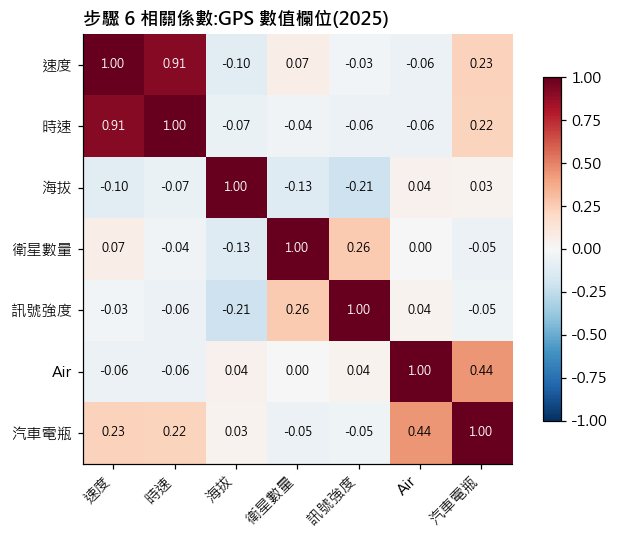

高度相關(|r| > 0.7)的欄位組合(相關不代表因果):
  速度 ↔ 時速:r = 0.91
步驟 7 偏態


,偏態,判讀
速度,1.71,右偏(右側長尾)
時速,1.73,右偏(右側長尾)
海拔,1.52,右偏(右側長尾)
衛星數量,0.14,左右大致對稱
訊號強度,-0.14,左右大致對稱
Air,-0.97,左偏(左側長尾)
汽車電瓶,-1.90,左偏(左側長尾)


In [29]:
gn = num(g25, ["速度", "時速", "海拔", "衛星數量", "訊號強度", "Air", "汽車電瓶"])
gn.loc[gn["Air"].eq(85), "Air"] = np.nan   # 85.0 是感測器異常固定值
print("步驟 5 描述統計"); display(gn.describe().T.round(2))
corr_heat(gn.dropna(), "步驟 6 相關係數:GPS 數值欄位(2025)", figsize=(6.5, 5))
print("步驟 7 偏態"); display(skew_table(gn))

**判讀:**
- `速度`(TransIOT)與 `時速`(天眼)是兩套系統量同一件事(r ≈ 0.91),擇一使用;不完全等於 1 是因為兩套系統的時間戳沒有完全對齊。
- `速度` 明顯右偏:大量時間停在 0(停等、卸貨),少數時間高速行駛。
- `Air` 名稱是空氣,實際上推測是**車廂溫度探頭**;85.0 是異常固定值,已剔除。
- 2025 年檔案沒有「任務」欄(100% 缺),只能用車號與時間對回配送計畫。
- `GPS有效性`、`衛星數量`、`訊號強度`、`實際緩速器百分比扭矩`、`當前使用網絡信息` 這幾欄**助教也不確定意義**,欄位說明沿用資料字典與實測推論。

### 助教說法驗證:`燃料` 是油位,不是油耗

助教說明 `燃料` 是油箱油位百分比,行駛時油面晃動會有誤差。下圖取 2025 年一天,把油位與車速畫在一起:如果是油位,行駛中應該**上下跳動**、停車時才穩定,加油時會**往上跳**;如果是累計油耗,則只會單調增加。

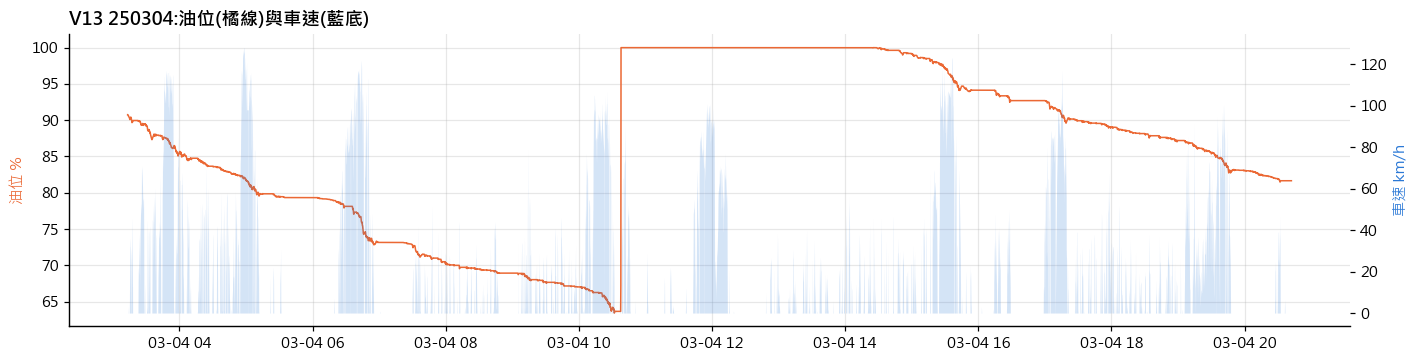

油位逐筆變化:上升 1,025 次、下降 1,569 次;當日最高 100.0%、最低 63.4%


In [30]:
gf = sorted(glob.glob(P("gps_traces", "2025-03", "*.csv")))[3]
g1 = read(gf, usecols=["GPS時間", "速度", "燃料"])
g1["t"] = pd.to_datetime(g1["GPS時間"], errors="coerce")
g1["油位"] = pd.to_numeric(g1["燃料"].astype(str).str.rstrip("%"), errors="coerce")   # 2024 檔為「89.78%」文字,2025 檔為數字
g1 = g1.dropna(subset=["t"]).sort_values("t")
fig, ax = plt.subplots(figsize=(13, 3.4))
ax.plot(g1["t"], g1["油位"], color="#eb6834", lw=1); ax.set_ylabel("油位 %", color="#eb6834")
ax2 = ax.twinx(); ax2.fill_between(g1["t"], g1["速度"], color="#2a78d6", alpha=0.2, lw=0); ax2.set_ylabel("車速 km/h", color="#2a78d6")
ax2.grid(False)
ax.set_title(f"V13 {os.path.basename(gf)[4:10]}:油位(橘線)與車速(藍底)", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()
dv = g1["油位"].diff()
print(f"油位逐筆變化:上升 {(dv > 0).sum():,} 次、下降 {(dv < 0).sum():,} 次;當日最高 {g1['油位'].max():.1f}%、最低 {g1['油位'].min():.1f}%")

**判讀:** 油位在行駛中有上升也有下降,不是單調遞減的油耗紀錄,與助教說明一致。若真的要用油位估油耗,只能比較**停車狀態下**加油前後的讀數,誤差仍大;本專案的油耗一律用車載 CAN 的 `Total fuel used(L)`。

In [31]:
show_issues("gps_traces")

等級,問題,說明
🟠 注意,2024 日期覆蓋,"58 個日檔;3/1–4/30 缺 3 天:03-01, 03-10, 04-16"
🟠 注意,2025 日期覆蓋,"58 個日檔;3/1–4/30 缺 3 天:04-13, 04-28, 04-29"
🔵 說明,取樣間隔,中位數取樣間隔 6 秒;每日行車時段長度中位數 11.9 小時。
🟠 注意,時間缺口(>10 分鐘無紀錄),"57 個日檔有缺口,總計 122 段、240 小時(含停車熄火)。"
🟠 注意,重複時間戳,"GPS時間 與前一筆重複的列 47,628 筆;落在「同一秒記錄多種事件」(如 定時追蹤 + 車輛起步)群組中的列共 85,182。算距離/速度前請先依 GPS時間 去重;天眼的『時間』是對齊到最近一筆,不是同一秒。"
🟠 注意,GPS 無效定位,"GPS有效性≠有效 的比例:平均 3.3%,最高 9.6%。"
🔵 說明,座標範圍,超出臺灣範圍的點平均 0.00%;座標為 0 的點 0.00%。
🔵 說明,速度,"日最高車速中位數 117 km/h,>110 km/h 的紀錄共 4299 筆。"
🟠 注意,未出車的日子,"6 個日檔整天速度皆為 0、路程不變(車輛未出車):2025-03-05(3列), 2025-03-06(3列), 2025-03-16(185列), 2025-03-18(35列), 2025-03-31(3列), 2025-04-22(216列)。計算平均日裡程時應排除。"
🔴 嚴重,任務欄位只有 2024 有值,"『任務』填值率:2024 87.8%、2025 0.0% → 2025 的軌跡無法直接對回 delivery_plan,需以時間+位置比對。"


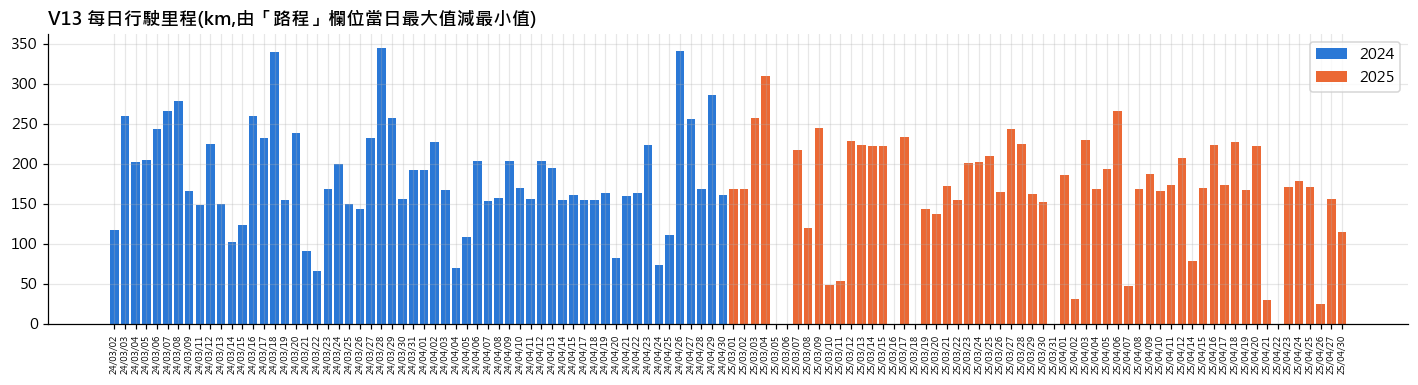

每日里程中位數(排除未出車日): {2024: 167.6, 2025: 172.5}


In [32]:
rows = []
for gf in sorted(glob.glob(P("gps_traces", "**", "V13_*.csv"), recursive=True)):
    g = read(gf, usecols=["GPS時間", "路程"])
    j = pd.to_numeric(g["路程"], errors="coerce").dropna()
    rows.append({"day": pd.to_datetime(os.path.basename(gf)[4:10], format="%y%m%d"), "km": (j.max() - j.min()) if len(j) else np.nan})
gd = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(13, 3.6))
for y, c in [(2024, "#2a78d6"), (2025, "#eb6834")]:
    d = gd[gd["day"].dt.year == y]
    ax.bar(d["day"].dt.strftime(f"{y % 100}/%m/%d"), d["km"], color=c, label=str(y))
ax.set_title("V13 每日行駛里程(km,由「路程」欄位當日最大值減最小值)", loc="left", fontweight="bold")
ax.tick_params(axis="x", labelrotation=90, labelsize=6); ax.legend()
plt.tight_layout(); plt.show()
print("每日里程中位數(排除未出車日):", gd[gd["km"] > 1].groupby(gd["day"].dt.year)["km"].median().round(1).to_dict())

## 7. 車載 CAN / Telematics vehicle_can_telematics

| 項目 | 內容 |
|---|---|
| 用途 | **實測油耗與排放基準**、怠速、引擎狀態、車廂溫度 |
| 一列代表 | 一筆車載紀錄;格式依匯出類型而異(4 種,見第 2 節) |
| 範圍 | 14 輛車、2025 年 1–7 月;每車每月一個檔 |
| 怎麼分辨格式 | 有 `dt24` 欄 = 天眼;檔名有 `_refuel` = 加油衍生;有 `Total fuel used(L)` = 含 CAN;其餘 = TransIOT 基本 |
| 核心量測值 | 累計油耗 `Total fuel used(L)`、里程 `High resolution vehicle distance(m)`、瞬時油耗率 `Engine Fuel Rate(L/H)`、轉速、輪速、**累計怠速油耗與時數** |
| 注意 | 只有 7 輛車(V04、V06、V07、V09、V17、V18、V19)有油耗;原始欄名多為簡體字 |

In [33]:
c = R["vehicle_can_telematics"]
display(Markdown(f"**一列代表:** {c['grain']}  **全資料:** {c['rows']:,} 列"))
fam = c["perfile"].groupby("family").agg(檔案數=("file", "count"), 列數=("rows", "sum"), 欄數=("cols", "max"),
                                         車輛=("vehicle", lambda s: ", ".join(sorted(set(s)))))
display(fam)
cov = c["coverage"].rename(columns={"start": "起", "end": "迄", "days": "有資料天數", "fams": "格式", "span_days": "跨越天數"})
display(cov)

**一列代表:** 一列 = 一筆車載紀錄;格式依匯出類型而異  **全資料:** 5,552,004 列

,檔案數,列數,欄數,車輛
family,,,,
A TransIOT 基本(32欄),37,1484349,32,"V12, V13, V14, V15"
A TransIOT+CAN(96–98欄),31,2967038,98,"V02, V04, V06, V07, V09, V17, V18, V19, V22"
B 天眼(20欄),21,973365,20,"V02, V12, V13, V14, V15, V16, V17, V18, V19"
C 加油衍生(34欄),1,127252,34,V13


,起,迄,有資料天數,格式,跨越天數
vehicle,,,,,
V02,2025-02-01 00:37:29,2025-07-31 23:58:52,120,"A, B",181
V04,2025-02-01 00:00:06,2025-04-30 23:59:56,89,A,89
V06,2025-02-01 00:00:00,2025-04-30 23:59:54,89,A,89
V07,2025-02-01 00:00:02,2025-03-31 21:54:13,59,A,59
V09,2025-02-01 00:00:07,2025-03-31 23:59:53,59,A,59
V12,2025-01-01 00:04:18,2025-07-21 10:41:50,160,"A, B",202
V13,2025-01-01 00:07:35,2025-07-31 17:16:38,395,"A, B, C",212
V14,2025-01-01 00:01:49,2025-07-31 20:14:08,150,"A, B",212
V15,2025-02-01 01:00:19,2025-07-31 20:31:36,141,"A, B",181


In [34]:
for k in ["A TransIOT+CAN(96–98欄)", "A TransIOT 基本(32欄)", "B 天眼(20欄)", "C 加油衍生(34欄)"]:
    d = c["profiles"][k]
    display(Markdown(f"#### {k}({d['files']} 個檔、{d['total']:,} 列)"))
    display(col_table(d["profile"], "vehicle_can_telematics"))

#### A TransIOT+CAN(96–98欄)(31 個檔、2,967,038 列)

類型,欄位,說明,完整度,相異值,範圍或常見值
🔑 識別碼,Tracker name,"追蹤器名稱,格式 (V##),用來辨識車輛",🟢 完整(缺 0.0%),9,(V04) (20%) | (V19) (19%) | (V06) (18%) | (V07) (13%)
🕒 時間,GPS Time,GPS 定位時間 ★主要時間欄,🟢 完整(缺 0.0%),"147,104",2025-02-01 00:00:00 ~ 2025-04-30 23:59:35(中位數 )
🕒 時間,Received time,伺服器收到資料的時間(通常晚幾秒),🟢 完整(缺 0.0%),"146,956",2025-01-31 23:59:59 ~ 2025-04-30 23:59:39(中位數 )
🏷️ 類別,Fix,"定位是否有效:Valid / Invalid(約 3% 無效,算距離前要排除)",🟢 完整(缺 0.0%),2,Valid (97%) | Invalid (3%)
🏷️ 類別,Direction,"行進方位(8 方位文字,如 West)",🟢 完整(缺 0.0%),8,West (18%) | East (17%) | North (12%) | South-West (12%)
🏷️ 類別,<空白欄名>,原始檔沒有欄名;內容為引擎狀態:啟動中 / 熄火,🟢 完整(缺 0.0%),2,啟動中 (96%) | 熄火 (4%)
🏷️ 類別,Current network information,追蹤器連線方式(4G / 無),🟢 完整(缺 0.0%),4,Mobile network(4G) (98%) | Nothing(NULL) (2%) | Mobile netwo
🏷️ 類別,Camera access information,行車攝影機連線狀態(CH1/CH2 是否連線),🟡 大致完整(缺 3.9%),3,"CH1 Disconnected,CH2 Con (86%) | CH1 Disconnected,CH2 Dis (1"
🏷️ 類別,Clutch switch,離合器開關,🟠 不完整(缺 10.6%),2,pedal pressed (54%) | pedal released (46%)
🏷️ 類別,Parking Brake Switch,手煞車開關,🟠 不完整(缺 10.6%),2,Parking brake not set (57%) | Parking brake set (43%)


#### A TransIOT 基本(32欄)(37 個檔、1,484,349 列)

類型,欄位,說明,完整度,相異值,範圍或常見值
🔑 識別碼,Tracker name,"追蹤器名稱,格式 (V##),用來辨識車輛",🟢 完整(缺 0.0%),4,(V13) (44%) | (V12) (25%) | (V14) (21%) | (V15) (9%)
🕒 時間,GPS Time,GPS 定位時間 ★主要時間欄,🟢 完整(缺 0.0%),"74,046",2025-01-01 00:01:49 ~ 2025-07-31 16:20:37(中位數 )
🕒 時間,Received time,伺服器收到資料的時間(通常晚幾秒),🟢 完整(缺 0.0%),"73,981",2025-01-01 00:02:05 ~ 2025-07-31 16:20:38(中位數 )
🏷️ 類別,Fix,"定位是否有效:Valid / Invalid(約 3% 無效,算距離前要排除)",🟢 完整(缺 0.0%),2,Valid (97%) | Invalid (3%)
🏷️ 類別,Direction,"行進方位(8 方位文字,如 West)",🟢 完整(缺 0.0%),8,West (18%) | East (17%) | South-West (12%) | North (12%)
🏷️ 類別,Tracker battery,"追蹤器內建電池(單位不明,多為 0.01–0.03)",🟢 完整(缺 0.0%),6,0 ~ 0.04(中位數 0.02)
🏷️ 類別,<空白欄名>,原始檔沒有欄名;內容為引擎狀態:啟動中 / 熄火,🟢 完整(缺 0.0%),2,啟動中 (95%) | 熄火 (5%)
🏷️ 類別,Current network information,追蹤器連線方式(4G / 無),🟢 完整(缺 0.0%),3,Mobile network(4G) (98%) | Nothing(NULL) (2%) | Mobile netwo
🏷️ 類別,Camera access information,行車攝影機連線狀態(CH1/CH2 是否連線),🟡 大致完整(缺 4.4%),2,"CH1 Disconnected,CH2 Con (100%) | CH1 Disconnected,CH2 Dis ("
📏 量測值,Speed,車速 km/h,🟢 完整(缺 0.0%),260,0 ~ 146(中位數 0)


#### B 天眼(20欄)(21 個檔、973,365 列)

類型,欄位,說明,完整度,相異值,範圍或常見值
🔑 識別碼,nodeId,地點節點 ID〔助教〕(-8581 推測為瑞芳 DC),🟢 完整(缺 0.5%),"2,059","-16111 ~ 3015058(中位數 -8,581)"
🔑 識別碼,carid1,車輛代碼 V##,🟢 完整(缺 0.0%),9,V13 (21%) | V16 (15%) | V17 (14%) | V18 (13%)
🔑 識別碼,CARNO,車號代碼,🟢 完整(缺 0.0%),9,V13 (21%) | V16 (15%) | V17 (14%) | V18 (13%)
🔑 識別碼,DVRID,"車機硬體序號(去識別為 DVR_V##,與車輛一對一)〔助教〕",🟡 大致完整(缺 3.9%),8,DVR_V13 (22%) | DVR_V16 (16%) | DVR_V17 (15%) | DVR_V18 (14%
🕒 時間,dt24,時間戳(24 小時制)〔助教〕,🟢 完整(缺 0.0%),"47,609",2025-03-01 05:52:20 ~ 2025-07-31 23:52:52(中位數 )
🏷️ 類別,direct,"行駛方向,8 個方位箭頭(↑ ↗ → ↘ ↓ ↙ ← ↖)〔助教〕",🟢 完整(缺 0.0%),8,↗ (19%) | ↙ (18%) | ↖ (17%) | ↘ (14%)
🏷️ 類別,status,車輛狀態:場內暫停、行駛中、場內關機、逾時停留、引擎起動/熄火…,🟢 完整(缺 0.0%),18,場內暫停 (31%) | 行駛中 (22%) | 場內關機 (12%) | 逾時停留 (8%)
🏷️ 類別,statusCode,"status 的數字代碼,一對一〔助教〕:0 行駛中、66 引擎熄火、67 引擎起動、68 場內關機、89 場內暫停、90 在外暫停、95 逾時停留、116/117 任務進/出圍籬…",🟢 完整(缺 0.0%),18,0 ~ 207(中位數 89)
🏷️ 類別,CARCOLOR,"不是車身顏色,是狀態圖示顏色〔助教引 AI〕:g 正常、r 警示、b 圍籬/熄火類,與 status 完全對應",🟢 完整(缺 0.0%),3,g (67%) | b (20%) | r (14%)
🏷️ 類別,Temperature2,"車廂溫度 °C(第二溫區,99.9% 空)",🔴 稀疏(缺 99.9%),18,16.1 ~ 18(中位數 17)


#### C 加油衍生(34欄)(1 個檔、127,252 列)

類型,欄位,說明,完整度,相異值,範圍或常見值
🔑 識別碼,Tracker name,"追蹤器名稱,格式 (V##),用來辨識車輛",🟢 完整(缺 0.0%),1,(V13) (100%)
🕒 時間,GPS Time,GPS 定位時間 ★主要時間欄,🟢 完整(缺 0.0%),"6,363",2025-03-01 00:52:46 ~ 2025-03-30 16:07:49(中位數 )
🕒 時間,Received time,伺服器收到資料的時間(通常晚幾秒),🟢 完整(缺 0.0%),"6,363",2025-03-01 00:52:52 ~ 2025-03-30 16:07:48(中位數 )
🏷️ 類別,Fix,"定位是否有效:Valid / Invalid(約 3% 無效,算距離前要排除)",🟢 完整(缺 0.0%),2,Valid (97%) | Invalid (3%)
🏷️ 類別,Direction,"行進方位(8 方位文字,如 West)",🟢 完整(缺 0.0%),8,West (20%) | East (18%) | South-West (11%) | South (11%)
🏷️ 類別,GSM Signal,行動網路訊號強度(0–31),🟢 完整(缺 0.0%),27,0 ~ 29(中位數 16)
🏷️ 類別,Tracker battery,"追蹤器內建電池(單位不明,多為 0.01–0.03)",🟢 完整(缺 0.0%),4,0 ~ 0.03(中位數 0.02)
🏷️ 類別,<空白欄名>,原始檔沒有欄名;內容為引擎狀態:啟動中 / 熄火,🟢 完整(缺 0.0%),2,啟動中 (97%) | 熄火 (3%)
🏷️ 類別,Current network information,追蹤器連線方式(4G / 無),🟢 完整(缺 0.0%),2,Mobile network(4G) (99%) | Nothing(NULL) (1%)
🏷️ 類別,Camera access information,行車攝影機連線狀態(CH1/CH2 是否連線),🟡 大致完整(缺 2.3%),1,"CH1 Disconnected,CH2 Con (100%)"


以下七個步驟以 **V04 的 2025 年 3 月檔**(A TransIOT + CAN 格式,含引擎訊號)示範;天眼格式另以一個檔案說明。

In [35]:
cf = [f for f in glob.glob(P("vehicle_can_telematics", "**", "*.csv"), recursive=True) if "V04_20250301" in f][0]
can = read(cf)
print("檔案:", os.path.relpath(cf, ROOT))
print("步驟 1 Peek"); display(peek(can, 3))
print("步驟 2 Dimensions:", can.shape)
empty = [tw(x) for x in can.columns if can[x].isna().all()]
print(f"其中 {len(empty)} 欄整欄皆空(車輛 ECU 不支援這些訊號)")
print("步驟 3 Data types(只列非空欄位)")
display(dtype_table(can[[x for x in can.columns if not can[x].isna().all()]], "vehicle_can_telematics"))

檔案: vehicle_can_telematics\V04\V04_20250301_0000_20250331_2359.csv
步驟 1 Peek


,Driver,License-Plate,Office,Department,Tracker name,Bind Geo-fence Name,GPS Time,Received time,Fix,Speed,Latitude,Longitude,Event,Altitude,Direction,Angle,Satellites,GSM Signal,Journey,Runtime,Tracker battery,Car battery,,Air,Left,Right door,Back door,Camera access information,Current network information,前車距離(CM),...,相對速度前軸右輪-1單位,相對速度前軸左輪-2單位,相對速度前軸右輪-2單位,減速器扭矩模式,緩速器使能-制動輔助開關,緩速器使能-換擋輔助開關,實際減速器-百分比扭矩(%),預期減速器百分比扭矩(%),引擎冷卻劑負荷增加,實際最大可用減速器-轉矩百分比(%),最高車速限制(KM/H),巡航控制高設定限速(KM/H),巡航控制低設定限速(KM/H),道路限速狀況,遠端油門踏板位置,巡航控制設定速度(km/h),引擎瞬時燃油經濟性(km/L),引擎油門位置(%),引擎中冷器溫控器開口(%),引擎的期望工作速度(rpm),引擎期望運轉速度不對稱調整,引擎燃油溫度(deg C),引擎機油溫度-1(deg C),渦輪油溫(deg C),引擎中冷器溫度(deg C),總行車時數(h),Total Power Takeoff Hours(h),總引擎PTO燃料使用 (L),行程平均燃油率(L/h),引擎總轉數(r)
0,(個資遮蔽),(個資遮蔽),NaN,NaN,(V04),NaN,2025-03-01 00:00:01,2025-03-01 00:00:03,Valid,16.0,25.042538,121.549152,Track By Time Interval,29,West,292,34,14,166656.0,563day(s)1:02:34,0.01,27.43,啟動中,23.87,17.5,2.5,16.81,"CH1 Disconnected,CH2 Disconnected,CH3 Connected,CH4 Disconnected",Mobile network(4G),NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,(個資遮蔽),(個資遮蔽),NaN,NaN,(V04),NaN,2025-03-01 00:00:11,2025-03-01 00:00:13,Valid,1.0,25.042606,121.549152,Track By Time Interval,9,South-West,237,34,14,166656.0,563day(s)1:02:44,0.01,27.36,啟動中,23.87,17.5,2.5,16.81,"CH1 Disconnected,CH2 Disconnected,CH3 Connected,CH4 Disconnected",Mobile network(4G),NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,(個資遮蔽),(個資遮蔽),NaN,NaN,(V04),NaN,2025-03-01 00:00:21,2025-03-01 00:00:23,Valid,28.0,25.042644,121.548680,Track By Time Interval,22,West,272,35,14,166656.1,563day(s)1:02:54,0.01,27.31,啟動中,23.87,17.5,2.5,16.81,"CH1 Disconnected,CH2 Disconnected,CH3 Connected,CH4 Disconnected",Mobile network(4G),NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


步驟 2 Dimensions: (205719, 97)


其中 44 欄整欄皆空(車輛 ECU 不支援這些訊號)
步驟 3 Data types(只列非空欄位)


,欄位,pandas 型態,說明
0,Tracker name,object,"追蹤器名稱,格式 (V##),用來辨識車輛"
1,GPS Time,object,GPS 定位時間 ★主要時間欄
2,Received time,object,伺服器收到資料的時間(通常晚幾秒)
3,Fix,object,"定位是否有效:Valid / Invalid(約 3% 無效,算距離前要排除)"
4,Speed,float64,車速 km/h
5,Latitude,float64,緯度(WGS84)
6,Longitude,float64,經度(WGS84)
7,Event,object,事件:Track By Time Interval=定時回報(約 90%);Harsh Braking=急煞;Harsh Accel...
8,Altitude,int64,海拔 m
9,Direction,object,"行進方位(8 方位文字,如 West)"


In [36]:
print("步驟 4 類別分布")
display(vc(can["Event"], name="事件"))
display(vc(can["Fix"], name="定位有效性"))

步驟 4 類別分布


,筆數,比例
事件,,
Track By Time Interval,181799,88.4%
CH2 video blind,4145,2.0%
Sharp Turn to Right,1418,0.7%
Far away from the set route(0),1188,0.6%
Sharp Turn to Left,1027,0.5%
GPS Signal Lost,1016,0.5%
Output 1 Active,961,0.5%
GPS Signal Recovery,961,0.5%
Output 1 Inactive,959,0.5%


,筆數,比例
定位有效性,,
Valid,199689,97.1%
Invalid,6030,2.9%


步驟 5 描述統計


,count,mean,std,min,25%,50%,75%,max
Speed,205719.0,17.05,28.71,0.00,0.00,0.00,25.00,110.00
Vehicle speed (wheel based)(km/h),197255.0,19.29,30.13,0.00,0.00,0.00,29.00,108.00
Engine speed(rpm),197251.0,997.35,505.54,0.00,600.00,799.00,1333.00,2924.00
Engine Fuel Rate(L/H),197243.0,3.70,5.17,0.00,0.95,1.45,3.80,33.35
Actual engine torque(%),197251.0,22.52,19.03,0.00,10.00,14.00,26.00,92.00
Accelerator pedal position(%),197277.0,17.02,26.87,0.00,0.00,0.00,38.00,100.00
Load at current speed(%),197277.0,4.62,15.92,0.00,0.00,0.00,0.00,100.00
Engine coolant temperature(deg C),197145.0,80.14,4.95,15.00,80.00,81.00,82.00,89.00
Air,205719.0,18.58,5.13,-13.25,16.06,18.31,22.12,30.00
Altitude,205719.0,47.95,32.29,-37.00,24.00,39.00,73.00,296.00


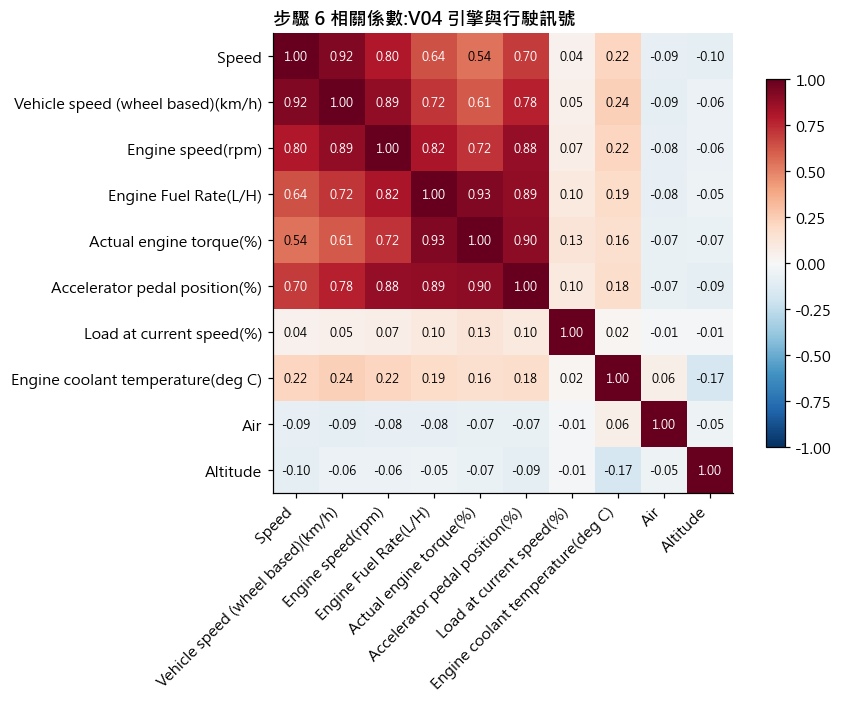

高度相關(|r| > 0.7)的欄位組合(相關不代表因果):
  Engine Fuel Rate(L/H) ↔ Actual engine torque(%):r = 0.93
  Speed ↔ Vehicle speed (wheel based)(km/h):r = 0.92
  Actual engine torque(%) ↔ Accelerator pedal position(%):r = 0.90
  Engine Fuel Rate(L/H) ↔ Accelerator pedal position(%):r = 0.89
  Vehicle speed (wheel based)(km/h) ↔ Engine speed(rpm):r = 0.89
  Engine speed(rpm) ↔ Accelerator pedal position(%):r = 0.88
  Engine speed(rpm) ↔ Engine Fuel Rate(L/H):r = 0.82
  Speed ↔ Engine speed(rpm):r = 0.80
  Vehicle speed (wheel based)(km/h) ↔ Accelerator pedal position(%):r = 0.78
  Engine speed(rpm) ↔ Actual engine torque(%):r = 0.72
  Vehicle speed (wheel based)(km/h) ↔ Engine Fuel Rate(L/H):r = 0.72
步驟 7 偏態


,偏態,判讀
Speed,1.68,右偏(右側長尾)
Vehicle speed (wheel based)(km/h),1.49,右偏(右側長尾)
Engine speed(rpm),1.16,右偏(右側長尾)
Engine Fuel Rate(L/H),2.40,嚴重右偏
Actual engine torque(%),1.67,右偏(右側長尾)
Accelerator pedal position(%),1.29,右偏(右側長尾)
Load at current speed(%),3.64,嚴重右偏
Engine coolant temperature(deg C),-6.83,嚴重左偏
Air,-1.47,左偏(左側長尾)
Altitude,1.34,右偏(右側長尾)


In [37]:
KEY = ["Speed", "Vehicle speed (wheel based)(km/h)", "Engine speed(rpm)", "Engine Fuel Rate(L/H)",
       "Actual engine torque(%)", "Accelerator pedal position(%)", "Load at current speed(%)",
       "Engine coolant temperature(deg C)", "Air", "Altitude"]
cn = num(can, [k for k in KEY if k in can.columns])
cn.loc[cn["Air"].eq(85), "Air"] = np.nan   # 85.0 是感測器異常固定值
print("步驟 5 描述統計"); display(cn.describe().T.round(2))
corr_heat(cn.dropna(), "步驟 6 相關係數:V04 引擎與行駛訊號", figsize=(8.5, 6.5))
print("步驟 7 偏態"); display(skew_table(cn))

**判讀:**
- **車速、轉速、油耗率、油門、扭力**彼此高度相關:引擎出力越大,油耗率越高。這些欄位若一起放進迴歸模型會有共線性問題,通常只挑一兩個代表。
- `Speed`(GPS 車速)與 `Vehicle speed (wheel based)`(輪速)高度相關(r ≈ 0.92)但不完全相同;隧道中 GPS 車速會掉到 0,**判斷怠速應以輪速為準**。
- 冷卻水溫嚴重左偏:引擎多數時間在 80°C 左右的正常工作溫度,冷車啟動時的低溫形成左側長尾。
- 油耗率與車速都明顯右偏:很多時間停著(車速 0、怠速油耗率低而穩定),少數時間高負載。
- **CAN 檔大量欄位整欄為空**(例如外氣溫度),外氣溫度需另找中央氣象署資料。

In [38]:
bf = sorted(f for f in glob.glob(P("vehicle_can_telematics", "**", "*.csv"), recursive=True) if "tmsV02" in f)[0]
b = read(bf)
print("天眼格式檔案:", os.path.relpath(bf, ROOT), b.shape)
display(peek(b, 3))
display(vc(b["status"], name="車輛狀態(天眼)"))
display(skew_table(num(b, ["speed", "Temperature1", "angle"])))

天眼格式檔案: vehicle_can_telematics\V02\V02\tmsV02_20250701_0000_20250731_2359.csv (37595, 20)


,x,y,dt24,caption,speed,direct,status,nodeId,statusCode,angle,carid1,carkit,carlicence,CARCOLOR,CARNO,DVRID,DVRTYPE,Temperature1,Temperature2,grp_id
0,121.77234,25.10453,2025-07-01 00:00:21,新北市瑞芳區 瑞芳ＤＣ,45,→,行駛中,-8581.0,0,84,V02,1,(個資遮蔽),g,V02,DVR_V02,1,20.6,NaN,NaN
1,121.77498,25.10332,2025-07-01 00:00:51,新北市瑞芳區 瑞芳ＤＣ,47,↓,行駛中,-8581.0,0,172,V02,1,(個資遮蔽),g,V02,DVR_V02,1,19.4,NaN,NaN
2,121.77273,25.10260,2025-07-01 00:01:17,新北市瑞芳區 瑞芳ＤＣ(回程),41,↙,行駛中,-12389.0,0,241,V02,1,(個資遮蔽),g,V02,DVR_V02,1,NaN,NaN,NaN


,筆數,比例
車輛狀態(天眼),,
場內暫停,11304,30.1%
行駛中,9093,24.2%
逾時停留,5606,14.9%
場內關機,5286,14.1%
Idle Alarm,1840,4.9%
在外暫停,1532,4.1%
任務進圍籬,1383,3.7%
任務出圍籬,792,2.1%
超速,338,0.9%


,偏態,判讀
speed,2.94,嚴重右偏
Temperature1,1.57,右偏(右側長尾)
angle,-0.17,左右大致對稱


### 助教說法驗證:天眼代碼

助教(部分轉述 AI)說明了天眼格式的 `statusCode`、`CARCOLOR`、`carkit`/`DVRTYPE`、`direct`/`angle`。下面讀全部天眼檔(只讀需要的欄位)檢查。

In [39]:
bcols = ["status", "statusCode", "CARCOLOR", "carkit", "DVRTYPE", "direct", "angle", "grp_id", "Temperature1"]
bfs = [f for f in glob.glob(P("vehicle_can_telematics", "**", "*.csv"), recursive=True)
       if "dt24" in pd.read_csv(f, encoding="utf-8-sig", nrows=0).columns]
ty = pd.concat([read(f, usecols=bcols).assign(file=os.path.basename(f)) for f in bfs], ignore_index=True)
print(f"天眼檔 {len(bfs)} 個、{len(ty):,} 列")
print("statusCode 對應幾種 status:", ty.groupby("statusCode")["status"].nunique().max(),
      ";status 對應幾種 statusCode:", ty.groupby("status")["statusCode"].nunique().max(), "→ 一對一")
sc = ty.groupby(["statusCode", "status", "CARCOLOR"]).size().rename("筆數").reset_index()
sc["status"] = sc["status"].map(tw)
display(sc.style.hide(axis="index").set_caption("statusCode × status × CARCOLOR(每個 status 只對應一種顏色)"))
print("CARCOLOR 每個 status 幾種顏色(最多):", ty.groupby("status")["CARCOLOR"].nunique().max())
kz = ty[ty["carkit"] == 0]
print(f"carkit = 0 的列 {len(kz):,} 筆,來自:{sorted(kz['file'].unique())};carkit 與 DVRTYPE 逐列相同:{(ty['carkit'] == ty['DVRTYPE']).all()}")
display(ty.groupby("direct")["angle"].agg(["min", "max", "size"]).sort_values("min").rename(columns={"min": "最小角度", "max": "最大角度", "size": "筆數"}))
print(f"grp_id 缺值 {ty['grp_id'].isna().mean():.1%};Temperature1 缺值 {ty['Temperature1'].isna().mean():.1%}")

天眼檔 21 個、973,365 列


statusCode 對應幾種 status: 1 ;status 對應幾種 statusCode: 1 → 一對一


statusCode,status,CARCOLOR,筆數
0,行駛中,g,217967
55,前室溫度異常,r,426
66,引擎熄火,b,2778
67,引擎起動,g,2803
68,場內關機,b,116470
70,進入禁區,r,3
71,超速,r,24651
89,場內暫停,g,297400
90,在外暫停,g,79534
91,場外關機,b,13672


CARCOLOR 每個 status 幾種顏色(最多): 1
carkit = 0 的列 38,117 筆,來自:['tmsV12_20250601_0000_20250630_2359.csv', 'tmsV12_20250701_0000_20250731_2359.csv'];carkit 與 DVRTYPE 逐列相同:True


,最小角度,最大角度,筆數
direct,,,
↑,0,360,65773
↗,12,79,180197
→,80,101,83789
↘,102,169,138267
↓,170,191,63264
↙,192,259,179084
←,260,281,99302
↖,282,349,163689


grp_id 缺值 24.7%;Temperature1 缺值 10.4%


**判讀:**
- `statusCode` 與 `status` **一對一**,助教列的代碼都正確;實際共 18 種,另有手煞車 ON/OFF(201/202)、Idle Alarm(203)、急加減速(206/207)、超速(71)等。**判斷怠速可直接用 `statusCode` 203(Idle Alarm)與 89/90(場內/在外暫停)**。
- `CARCOLOR` 與 `status` 完全對應:g 正常、r 警示、b 圍籬/熄火類,與助教(轉述 AI)的說法一致,不帶額外資訊。
- `carkit`、`DVRTYPE` **不是恆為 1**:V12 的 2025 年 6、7 月檔為 0,兩欄逐列相同,意義仍不明,分析用不到。
- `direct` 每個箭頭對應一段約 45° 的角度(↑ 跨 0°/360°),兩欄是同一資訊,擇一使用。
- `Temperature1` 助教說「大量為空」,但全部天眼檔合計只缺約 10%,可以當作天眼格式的車廂溫度來源。

In [40]:
show_issues("vehicle_can_telematics")

等級,問題,說明
🔴 嚴重,三種匯出格式混在一起,"A TransIOT 基本(32欄): 37 檔 / 1,484,349 列 / 4 車; A TransIOT+CAN(96–98欄): 31 檔 / 2,967,038 列 / 9 車; B 天眼(20欄): 21 檔 / 973,365 列 / 9 車; C 加油衍生(34欄): 1 檔 / 127,252 列 / 1 車。V16 2025-03~05 兩檔檔名無 tms 前綴,實為天眼格式。"
🟠 注意,各車涵蓋期間差異大,"V02: 02/01–07/31 (A, B); V04: 02/01–04/30 (A); V06: 02/01–04/30 (A); V07: 02/01–03/31 (A); V09: 02/01–03/31 (A); V12: 01/01–07/21 (A, B); V13: 01/01–07/31 (A, B, C); V14: 01/01–07/31 (A, B); V15: 02/01–07/31 (A, B); V16: 03/01–05/31 (B); V17: 02/01–07/31 (A, B); V18: 02/01–07/31 (A, B); V19: 02/01–06/30 (A, B); V22: 02/01–03/31 (A)"
🔴 嚴重,有 CAN 欄位但沒有油耗值,"14 個 96–98 欄檔案的 Total fuel used 全空:V02_20250201_0000_20250205_2359.csv, V02_20250206_0000_20250210_2359.csv, V02_20250211_0000_20250215_2359.csv, V02_20250216_0000_20250220_2359.csv, V02_20250221_0000_20250225_2359.csv, V02_20250226_0000_20250228_2359.csv, V02_20250301_0000_20250331_2359.csv, V22_20250201_0000_20250205_2359.csv, V22_20250206_0000_20250210_2359.csv, V22_20250211_0000_20250215_2359.csv, V22_20250216_0000_20250220_2359.csv, V22_20250221_0000_20250225_2359.csv, V22_20250226_0000_20250228_2359.csv, V22_20250301_0000_20250331_2359.csv"
🔵 說明,可算實測油耗的車,"7 輛(V04, V06, V07, V09, V17, V18, V19),共 24,882 L / 117,607 km → 平均 21.2 L/100km,約 567 gCO₂/km(柴油 2.68 kg/L,僅燃燒端)。"
🟠 注意,累計計數器倒退/跳動,"Total fuel used 倒退 245 次(最大倒退 -4 L)、單步跳增 >50 L 0 次;odometer 倒退 7,062 次(最大倒退 -8960 m)。odometer 倒退來自同秒多筆中個別點瞬間前跳(1–9 km)後回到正常值;實測 488 車日以 5 點中位數平滑後,日裡程 max−min 與平滑結果差 <0.01%,可直接使用。"
🟠 注意,時間缺口(>10 分鐘無紀錄),"100% 的檔案有缺口,合計 24,610 小時(多數為夜間熄火,屬正常)。"
🟠 注意,重複時間戳,"共 143,122 筆。"
🔵 說明,取樣間隔,A TransIOT 基本(32欄): 10 秒; A TransIOT+CAN(96–98欄): 10 秒; B 天眼(20欄): 30 秒; C 加油衍生(34欄): 10 秒
🔵 說明,怠速/停車比例(速度<1),A TransIOT 基本(32欄): 63%; A TransIOT+CAN(96–98欄): 67%; B 天眼(20欄): 66%; C 加油衍生(34欄): 60%(含整夜停車)。


### 實測油耗:7 輛車的排放基準

以 `Total fuel used(L)` 與里程計數器的**每日最大 − 最小**算出每車每日油耗與里程,排除異常車日後計算 L/100km。

,車日,總里程km,總油耗L,L/100km
vehicle,,,,
V04,88,25777.0,5013.0,19.0
V06,89,22982.0,4964.0,22.0
V07,58,15892.0,3280.0,21.0
V09,58,7491.0,1662.0,22.0
V17,49,8922.0,2174.0,24.0
V18,58,9849.0,2231.0,23.0
V19,88,25832.0,5376.0,21.0


7 車合計:21.2 L/100km ≈ 550 g CO₂/km(柴油 2.60 kg CO₂/L,僅燃燒端),共 488 個車日


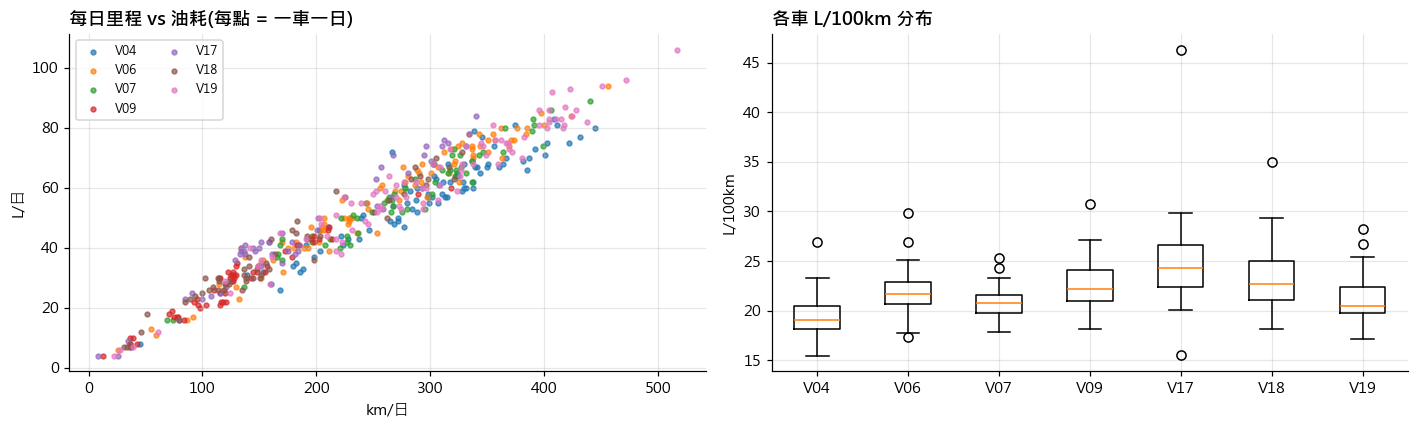

In [41]:
want = ["GPS Time", "Total fuel used(L)", "High resolution vehicle distance(m)"]
daily = []
for f in glob.glob(P("vehicle_can_telematics", "**", "*.csv"), recursive=True):
    hdr = pd.read_csv(f, encoding="utf-8-sig", nrows=0).columns
    if "Total fuel used(L)" not in hdr or "High resolution vehicle distance(m)" not in hdr:
        continue
    d = pd.read_csv(f, encoding="utf-8-sig", usecols=want, low_memory=False)
    d["day"] = pd.to_datetime(d["GPS Time"], errors="coerce").dt.normalize()
    d["fuel"] = pd.to_numeric(d["Total fuel used(L)"], errors="coerce")
    d["km"] = pd.to_numeric(d["High resolution vehicle distance(m)"], errors="coerce") / 1000
    g = d.dropna(subset=["day", "fuel", "km"]).groupby("day").agg(fuel=("fuel", lambda s: s.max() - s.min()),
                                                                   km=("km", lambda s: s.max() - s.min()))
    g["vehicle"] = re.search(r"V\d\d", os.path.basename(f)).group(0)
    daily.append(g.reset_index())
dy = pd.concat(daily, ignore_index=True)
dy = dy[(dy["km"] > 5) & (dy["km"] < 600) & (dy["fuel"] > 0.5) & (dy["fuel"] < 300)]
dy["L100"] = dy["fuel"] / dy["km"] * 100
dy = dy[dy["L100"].between(3, 80)]
agg = dy.groupby("vehicle").agg(車日=("day", "count"), 總里程km=("km", "sum"), 總油耗L=("fuel", "sum"))
agg["L/100km"] = (agg["總油耗L"] / agg["總里程km"] * 100).round(1)
display(agg.round(0))
fleet = dy["fuel"].sum() / dy["km"].sum() * 100
print(f"7 車合計:{fleet:.1f} L/100km ≈ {fleet * 2.60 * 10:.0f} g CO₂/km(柴油 2.60 kg CO₂/L,僅燃燒端),共 {len(dy):,} 個車日")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for v, gg in dy.groupby("vehicle"):
    axes[0].scatter(gg["km"], gg["fuel"], s=10, label=v, alpha=0.7)
axes[0].set_xlabel("km/日"); axes[0].set_ylabel("L/日"); axes[0].legend(fontsize=8, ncols=2)
axes[0].set_title("每日里程 vs 油耗(每點 = 一車一日)", loc="left", fontweight="bold")
axes[1].boxplot([g["L100"] for _, g in dy.groupby("vehicle")], tick_labels=sorted(dy["vehicle"].unique()))
axes[1].set_ylabel("L/100km"); axes[1].set_title("各車 L/100km 分布", loc="left", fontweight="bold")
plt.tight_layout(); plt.show()

## 8. 其他場站配送計畫 delivery_plan_other_depots(助教補充)

| 項目 | 內容 |
|---|---|
| 用途 | 與瑞芳比較每趟停靠數(容量的實際上限)、確認東北角門市由哪個物流中心配送、林口與瑞芳共用車隊的串接 |
| 一列代表 | 某日某趟的一個停靠點(出發 DC 列 `last_dc` 空、門市列 = 0、返場列 = 1),格式與 TMS 相同,共 42 欄 |
| 範圍 | **林口 LC** 2024-01 ~ 2025-12(另有 2026-04-22 一天零星);**高雄 YT** 2024-01 ~ 2026-10(仍在更新) |
| 與 TMS 的差別 | TMS 只有瑞芳的任務 12;這兩個場站含**全部配別** |
| 趟次鍵 | `(Delivery_date, TaskType_id, Route_id, Car_id)`;數字路線碼會被不同配別在同一天重複使用,只用 `Route_id` 不夠 |
| 建議分組欄 | 場站 `Dept`、配別 `TaskType_id`、車號 `Car_licence` |
| 注意 | 林口與瑞芳**共用 11 台車、9 位司機**(代號相同);`START_TIME` 可超過 24:00;高雄門市不在門市主檔內,無法定位 |


In [42]:
# 讀入兩個場站(代碼欄當文字讀,避免前導 0 消失)
t0 = time.time()
OD_DIR = P("delivery_plan_other_depots", "delivery_plan_other_depots")
od = pd.concat([read(os.path.join(OD_DIR, d, "all_delivery.csv"), dtype={"TaskType_id": str, "Route_id": str, "Route_id1": str,
                                                                        "Store_id": str, "tel": str, "onlinetel": str})
                for d in ["linkou_LC", "kaohsiung_YT"]], ignore_index=True)
print(f"讀取 {time.time() - t0:.0f} 秒")

def quick_profile(df):
    # 與 results.pkl 相同格式的欄位剖析(全資料):類型、缺失率、相異值、常見值或範圍
    rows = []
    for c in df.columns:
        s = df[c]
        s = s.where(~s.astype(str).str.strip().isin(["", "nan"])) if s.dtype == object else s
        v = s.dropna()
        r = dict(column=c, null_rate=s.isna().mean(), distinct=v.nunique(), kind="空", top="", min="", max="", p50="")
        if v.empty:
            rows.append(r); continue
        n = pd.to_numeric(v, errors="coerce")
        if n.notna().mean() > 0.95 and not c.endswith(("_id", "_seq", "tel")) and c not in ("Store_id", "Route_id1"):
            n = n.dropna(); r.update(kind="數值", min=n.min(), max=n.max(), p50=n.median())
        else:
            smp = v.astype(str).iloc[:: max(len(v) // 2000, 1)]
            if pd.to_datetime(smp, errors="coerce", format="mixed").notna().mean() > 0.9 and not c.endswith("TIME"):
                d = pd.to_datetime(v, errors="coerce", format="mixed")
                r.update(kind="時間", min=str(d.min()), max=str(d.max()))
            else:
                r.update(kind="文字", top=" | ".join(f"{k[:24]} ({x / len(v):.0%})" for k, x in v.astype(str).value_counts().head(4).items()))
        rows.append(r)
    return pd.DataFrame(rows)

od_prof = quick_profile(od)
display(Markdown(f"**一列代表:** 某日某趟的一個停靠點  **全資料:** {len(od):,} 列 × {od.shape[1]} 欄(林口 + 高雄)"))
col_table(od_prof, "other_depots")


讀取 11 秒


**一列代表:** 某日某趟的一個停靠點  **全資料:** 450,296 列 × 42 欄(林口 + 高雄)

類型,欄位,說明,完整度,相異值,範圍或常見值
🔑 識別碼,Store_id,"門市碼 1001…;S3001111111 / 3001111111 = 林口 DC 出發 / 返場列,S3001333333 = 高雄 DC 出發列",🟢 完整(缺 0.0%),"2,244",S3001333333 (5%) | 3001333333 (5%) | S3001111111 (1%) | 3001
🔑 識別碼,Route_id,路線碼 ⚠ 數字碼(101、401…)會被不同配別在同一天重複使用;兩字母碼(LA、QC…)才是配別專屬,🟢 完整(缺 0.0%),173,SG (5%) | QG (5%) | QI (4%) | YL (4%)
🔑 識別碼,Route_id1,與 Route_id 完全相同(冗餘),🟢 完整(缺 0.0%),173,SG (5%) | QG (5%) | QI (4%) | YL (4%)
🔑 識別碼,Route_seq,路線 + 站序;<路線>DC = 物流中心列,🟢 完整(缺 0.2%),"3,830",90101 (1%) | 101DC (0%) | DXDC (0%) | WUDC (0%)
🔑 識別碼,Car_id,"車輛碼;真實車牌已換成 V##,ZZ… 為外調車佔位碼",🟢 完整(缺 0.0%),83,V24 (10%) | V25 (10%) | V26 (10%) | V27 (9%)
🔑 識別碼,Store_Name,門市名稱(不含「全家」);DC 列為「林口ＤＣ」「高雄ＤＣ」,🟢 完整(缺 0.0%),"1,655",高雄ＤＣ (9%) | 林口ＤＣ (3%) | 高雄新左營店 (0%) | 高雄市集店 (0%)
🔑 識別碼,Car_licence,"車牌代碼 V## ★車輛分析用這欄;林口與瑞芳共用 11 台車,沿用同一代號;高雄是獨立車隊(V24–V76 範圍)",🟢 完整(缺 0.0%),64,V25 (10%) | V24 (10%) | V26 (10%) | V27 (9%)
🕒 時間,Pl_M_Arrive_dt,計畫的 DC 到場/備車時間(每趟一個)〔助教〕;與 Ac_M_Arrive_dt 比較判斷是否延遲發車,🟢 完整(缺 0.0%),"16,833",2023-12-31 18:39:00 ~ 2026-10-19 17:30:00(中位數 )
🕒 時間,Ac_Arrive_dt_02,與 Ac_Arrive_dt_01 相同(冗餘),🟠 不完整(缺 5.4%),"403,632",2023-12-31 18:47:18 ~ 2026-10-19 16:46:27(中位數 )
🕒 時間,Pl_Arrive_dt_01,"與 Pl_Arrive_dt 相同,ISO 格式",🟢 完整(缺 0.0%),"406,888",2023-12-31 18:20:19 ~ 2026-10-19 20:45:00(中位數 )


In [43]:
print("步驟 1 Peek"); display(peek(od, 3))
print("步驟 2 Dimensions:", od.shape, " 各場站:", od["Dept"].value_counts().to_dict())
print("步驟 3 Data types"); display(dtype_table(od, "other_depots"))


步驟 1 Peek


,last_dc,Store_id,PLDT,Ex_Arrive_diff,InTime,Pl_M_Arrive_dt,Dept,Route_id,Order_Index,Route_Name,Temperature2,Temperature1,In_Temperature2,OnTime,Ac_Arrive_dt_02,Route_id1,Pl_Arrive_dt_01,Ac_Arrive_dt,Route_seq,Car_id,Store_Name,Delivery_date,onlinetel,DiffStatus,Ex_M_Arrive_diff,TaskType_id,Ac_Arrive_dt_01,mDiffStatus,Car_licence,tel,START_TIME,Pl_Arrive_dt,Arrive_dt,Dept_Name,Ac_M_Arrive_dt,Im_Arrive_dt,Emp_tel,Im_arrive_dt_02,Emp_name,OutTime,In_Temperature1,source_file
0,NaN,S3001111111,NaN,NaN,-60,2023-12-31 18:39:00,LC,LA,-1,Carrier_A,NaN,NaN,NaN,0,NaN,LA,2023-12-31 18:39:34,NaN,LADC,V31,林口ＤＣ,1/1/2024 12:00:00 AM,(個資遮蔽),NaN,-22.0,05,NaN,0.0,V31,(個資遮蔽),18:00,12/31/2023 6:39:34 PM,2023-12-31 18:39:34,林口DC,NaN,NaN,(個資遮蔽),NaN,(個資遮蔽),30,NaN,2024/01/2024-01-01_all.json
1,0.0,1001022531,2.0,-37.0,-60,2023-12-31 18:39:00,LC,LA,1,Carrier_A,NaN,18.3,NaN,0,2023-12-31 18:48:53,LA,2023-12-31 18:46:00,12/31/2023 6:48:53 PM,LA01,V31,林口新都店,1/1/2024 12:00:00 AM,(個資遮蔽),0.0,-22.0,05,2023-12-31 18:48:53,0.0,V31,(個資遮蔽),18:00,12/31/2023 6:46:00 PM,2023-12-31 18:46:00,林口DC,NaN,12/31/2023 7:25:00 PM,(個資遮蔽),2023-12-31 19:25:00,(個資遮蔽),30,18.3,2024/01/2024-01-01_all.json
2,0.0,1001022869,2.0,-36.0,-60,2023-12-31 18:39:00,LC,LA,2,Carrier_A,NaN,18.2,NaN,0,2023-12-31 18:54:21,LA,2023-12-31 18:52:00,12/31/2023 6:54:21 PM,LA02,V31,林口忠一店,1/1/2024 12:00:00 AM,(個資遮蔽),0.0,-22.0,05,2023-12-31 18:54:21,0.0,V31,(個資遮蔽),18:00,12/31/2023 6:52:00 PM,2023-12-31 18:52:00,林口DC,NaN,12/31/2023 7:30:00 PM,(個資遮蔽),2023-12-31 19:30:00,(個資遮蔽),30,18.2,2024/01/2024-01-01_all.json


步驟 2 Dimensions: (450296, 42)  各場站: {'YT': 315004, 'LC': 135292}
步驟 3 Data types


,欄位,pandas 型態,說明
0,last_dc,float64,"列類型:0 = 門市停靠,1 = 回場 DC,空 = 出發 DC"
1,Store_id,object,"門市碼 1001…;S3001111111 / 3001111111 = 林口 DC 出發 / 返場列,S3001333333 = ..."
2,PLDT,float64,實際 − 預計 Ac_Arrive_dt − Pl_Arrive_dt(分鐘)〔助教〕
3,Ex_Arrive_diff,float64,實際 − 表訂 Ac_Arrive_dt − Im_Arrive_dt(分鐘)〔助教〕★準點指標;負 = 早到
4,InTime,int64,"允收時窗下限,固定 -60 分〔助教引 AI〕"
5,Pl_M_Arrive_dt,object,計畫的 DC 到場/備車時間(每趟一個)〔助教〕;與 Ac_M_Arrive_dt 比較判斷是否延遲發車
6,Dept,object,物流中心代碼:LC = 林口、YT = 高雄
7,Route_id,object,路線碼 ⚠ 數字碼(101、401…)會被不同配別在同一天重複使用;兩字母碼(LA、QC…)才是配別專屬
8,Order_Index,int64,趟內停靠順序;-1 = 出發 DC 列
9,Route_Name,object,"承運商名稱(已去識別化)〔助教〕,全部 Carrier_A"


In [44]:
od["date"] = pd.to_datetime(od["Delivery_date"], format="%m/%d/%Y %I:%M:%S %p").dt.normalize()
od["trip"] = od["date"].dt.strftime("%Y-%m-%d") + "|" + od["TaskType_id"] + "|" + od["Route_id"] + "|" + od["Car_id"].astype(str)
os_ = od[od["last_dc"] == 0].copy()   # 門市停靠列
print(f"門市停靠列 {len(os_):,} 筆;日期範圍:", od.groupby("Dept")["date"].agg(["min", "max", "nunique"]).to_dict("index"))
key = ["Dept", "date", "TaskType_id", "Route_id", "Car_id", "Order_Index"]
print(f"主鍵檢查:以 {key} 判斷,門市列重複 {os_.duplicated(key).sum():,} 列")
reuse = od.drop_duplicates(["Dept", "date", "TaskType_id", "Route_id"]).groupby(["Dept", "date", "Route_id"])["TaskType_id"].nunique()
print(f"同一天同一路線碼被 2 種以上配別使用:{(reuse > 1).mean():.1%} 的(場站, 日, 路線碼)組合")
st_h = od.drop_duplicates("trip")["START_TIME"].str.split(":").str[0].astype(float)
print(f"START_TIME ≥ 24:00 的趟次:{(st_h >= 24).mean():.0%}(最大 {st_h.max():.0f} 點)")

print("步驟 4 類別分布")
display(pd.crosstab(os_["TaskType_id"], os_["Dept_Name"], margins=True, margins_name="合計"))
for d, g in os_.groupby("Dept_Name"):
    display(vc(g["DiffStatus"].map({-1: "早到(早 60 分以上)", 0: "準時", 1: "遲到(晚 30 分以上)"}), name=f"{d} 到店準點狀態"))
display(vc(od["last_dc"].map({0: "門市停靠", 1: "回場 DC"}), name="列類型"))
display(vc(od["Car_id"].astype(str).str.startswith("ZZ").map({True: "臨時外調車 ZZ", False: "自有車 V"}), name="車輛來源"))


門市停靠列 398,102 筆;日期範圍: {'LC': {'min': Timestamp('2024-01-01 00:00:00'), 'max': Timestamp('2026-04-22 00:00:00'), 'nunique': 732}, 'YT': {'min': Timestamp('2024-01-01 00:00:00'), 'max': Timestamp('2026-10-19 00:00:00'), 'nunique': 1023}}


主鍵檢查:以 ['Dept', 'date', 'TaskType_id', 'Route_id', 'Car_id', 'Order_Index'] 判斷,門市列重複 0 列


同一天同一路線碼被 2 種以上配別使用:2.4% 的(場站, 日, 路線碼)組合
START_TIME ≥ 24:00 的趟次:30%(最大 62 點)
步驟 4 類別分布


Dept_Name,林口DC,高雄DC,合計
TaskType_id,,,
01,2,105,107
02,603,35823,36426
03,0,49872,49872
04,0,158489,158489
05,35384,10367,45751
12,87913,653,88566
A1,0,3700,3700
A2,0,1,1
A4,0,15190,15190


,筆數,比例
林口DC 到店準點狀態,,
準時,105562,85.2%
早到(早 60 分以上),16426,13.3%
遲到(晚 30 分以上),1283,1.0%
(空),631,0.5%


,筆數,比例
高雄DC 到店準點狀態,,
準時,187125,68.2%
早到(早 60 分以上),73324,26.7%
遲到(晚 30 分以上),9397,3.4%
(空),4354,1.6%


,筆數,比例
列類型,,
門市停靠,398102,88.4%
(空),26097,5.8%
回場 DC,26097,5.8%


,筆數,比例
車輛來源,,
自有車 V,443593,98.5%
臨時外調車 ZZ,6703,1.5%


步驟 5 描述統計:每趟門市停靠數(依場站、配別)


count  mean   std  min   50%   90%   99%   max
Dept_Name TaskType_id                                                  
林口DC      01               2.0   1.0   0.0  1.0   1.0   1.0   1.0   1.0
          02              52.0  11.6   2.0  8.0  11.0  14.0  16.0  16.0
          05            1539.0  23.0   3.1  9.0  24.0  25.0  27.0  30.0
          12            4102.0  21.4   7.6  1.0  25.0  28.0  29.0  34.0
高雄DC      01              36.0   2.9   1.6  1.0   3.0   5.0   6.6   7.0
          02            2493.0  14.4   2.6  1.0  15.0  17.0  18.0  24.0
          03            4950.0  10.1   3.9  1.0  11.0  14.0  15.0  26.0
          04           10037.0  15.8   5.0  1.0  17.0  21.0  24.0  35.0
          05             467.0  22.2   1.7  2.0  22.0  24.0  25.0  25.0
          12              51.0  12.8   8.3  1.0  13.0  23.0  24.0  24.0
          A1             774.0   4.8   2.6  1.0   4.0   9.0  11.0  12.0
          A2               1.0   1.0   NaN  1.0   1.0   1.0   1.0   1.0
          A4            1593.0   9.5  12.7  1.0   4.0  26.0  52.0  57.0

,count,mean,std,min,25%,50%,75%,max
Ex_Arrive_diff,393117.0,-55.03,82.33,-1982.0,-60.0,-52.0,-32.0,1439.0
PLDT,388195.0,8.63,64.92,-1945.0,-1.0,1.0,23.0,1297.0
Order_Index,398102.0,9.90,6.67,1.0,4.0,9.0,14.0,57.0
Temperature1,386567.0,-0.01,14.90,-32.0,-15.1,2.1,17.0,38.0
Temperature2,125624.0,6.66,9.50,-24.8,1.8,7.4,13.7,127.9


第二溫區缺失率: {'林口DC': '100.0%', '高雄DC': '54.2%'}


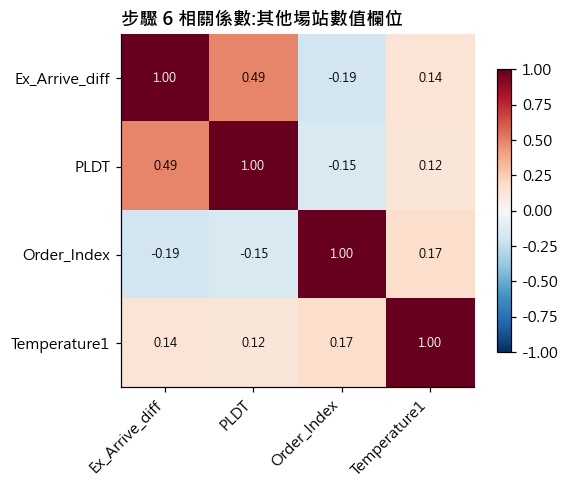

沒有 |r| > 0.7 的欄位組合。
步驟 7 偏態


,偏態,判讀
Ex_Arrive_diff,-4.96,嚴重左偏
PLDT,-5.42,嚴重左偏
Order_Index,0.90,右偏(右側長尾)
Temperature1,0.01,左右大致對稱
Temperature2,-0.45,左右大致對稱


In [45]:
# 步驟 5–7:每趟停靠數與逐店數值
trips = os_.groupby(["Dept_Name", "TaskType_id", "trip"]).size().rename("每趟停靠數").reset_index()
print("步驟 5 描述統計:每趟門市停靠數(依場站、配別)")
display(trips.groupby(["Dept_Name", "TaskType_id"])["每趟停靠數"].describe(percentiles=[.5, .9, .99]).round(1))
on = num(os_, ["Ex_Arrive_diff", "PLDT", "Order_Index", "Temperature1", "Temperature2"])
on = on[on["Temperature1"].between(-40, 50) | on["Temperature1"].isna()]
display(on.describe().T.round(2))
print("第二溫區缺失率:", os_.groupby("Dept_Name")["Temperature2"].apply(lambda s: f"{s.isna().mean():.1%}").to_dict())
corr_heat(on.drop(columns="Temperature2").dropna(), "步驟 6 相關係數:其他場站數值欄位", figsize=(5.5, 4.5))
print("步驟 7 偏態"); display(skew_table(on))


### 共用車隊:林口與瑞芳的車輛重疊

助教說明林口與瑞芳**共用 11 台車、9 位司機**,代號相同,可以直接串接。下表用瑞芳的配送計畫(2024-01 ~ 2025-03)與 TMS(任務 12,到 2026-01)合併算出每台車在兩個場站各出車幾天。**同日兩場站**代表那一天同一台車在瑞芳和林口都有趟次。


In [46]:
rf_days = pd.concat([
    pd.concat([read(f, usecols=["Delivery_Dt", "Car_licence"]) for f in glob.glob(P("delivery_plan", "monthly", "*.csv"))])
      .assign(date=lambda d: pd.to_datetime(d["Delivery_Dt"], errors="coerce"))[["date", "Car_licence"]],
    pd.concat([read(f, usecols=["Delivery_date", "Car_licence", "Emp_name"]) for f in glob.glob(P("tms_delivery_records", "**", "*.csv"), recursive=True)])
      .assign(date=lambda d: pd.to_datetime(d["Delivery_date"], format="%m/%d/%Y %I:%M:%S %p"))[["date", "Car_licence"]],
]).dropna().drop_duplicates()
lc_days = od.loc[od["Dept"] == "LC", ["date", "Car_licence"]].dropna().drop_duplicates()
yt_days = od.loc[od["Dept"] == "YT", ["date", "Car_licence"]].dropna().drop_duplicates()
shared = sorted(set(rf_days["Car_licence"]) & set(lc_days["Car_licence"]))
both = rf_days.merge(lc_days, on=["date", "Car_licence"])
CAN0, CAN1 = pd.Timestamp("2025-01-01"), pd.Timestamp("2025-07-31")
lc_can = lc_days[lc_days["date"].between(CAN0, CAN1)]
fleet = pd.DataFrame({
    "瑞芳出車天數": rf_days[rf_days["Car_licence"].isin(shared)].groupby("Car_licence").size(),
    "林口出車天數": lc_days[lc_days["Car_licence"].isin(shared)].groupby("Car_licence").size(),
    "同日兩場站": both.groupby("Car_licence").size(),
    "林口天數(CAN 期間 2025-01~07)": lc_can[lc_can["Car_licence"].isin(shared)].groupby("Car_licence").size(),
}).fillna(0).astype(int)
fleet["林口占比"] = (fleet["林口出車天數"] / (fleet["瑞芳出車天數"] + fleet["林口出車天數"])).map("{:.0%}".format)
fleet["有 CAN 資料"] = ["✅" if os.path.isdir(P("vehicle_can_telematics", v)) else "" for v in fleet.index]
print(f"共用車輛 {len(shared)} 台;與高雄重疊的車輛:{len(set(rf_days['Car_licence']) & set(yt_days['Car_licence']))} 台")
fleet.rename_axis("車號")


共用車輛 11 台;與高雄重疊的車輛:0 台


,瑞芳出車天數,林口出車天數,同日兩場站,林口天數(CAN 期間 2025-01~07),林口占比,有 CAN 資料
車號,,,,,,
V04,614,9,9,0,1%,✅
V06,659,11,9,0,2%,✅
V07,610,4,4,0,1%,✅
V12,111,182,0,0,62%,✅
V13,432,30,11,3,6%,✅
V14,614,9,5,2,1%,✅
V15,573,4,3,0,1%,✅
V16,436,12,10,0,3%,✅
V17,571,3,2,0,1%,✅


### 與瑞芳比較:每趟停靠數(容量的實際上限)

資料仍然**沒有貨量**,共同配送試作以「每趟最多停幾家店」代替容量。三個場站的實際每趟停靠數可以檢驗這個假設是否合理。


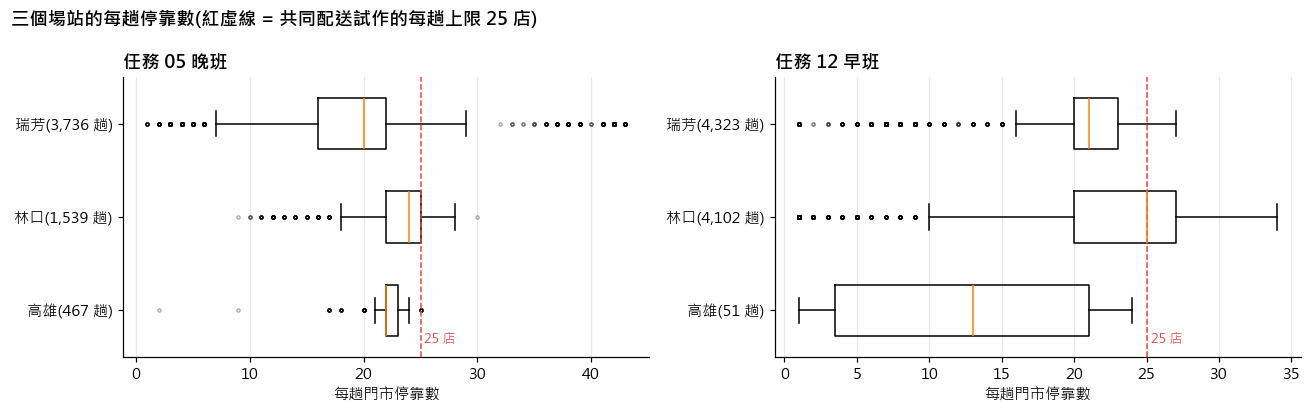

count  mean  std  min   50%   90%   99%   max
TaskType_id 場站                                                
05          林口  1539.0  23.0  3.1  9.0  24.0  25.0  27.0  30.0
            瑞芳  3736.0  19.4  8.4  1.0  20.0  25.0  42.0  43.0
            高雄   467.0  22.2  1.7  2.0  22.0  24.0  25.0  25.0
12          林口  4102.0  21.4  7.6  1.0  25.0  28.0  29.0  34.0
            瑞芳  4323.0  19.3  5.8  1.0  21.0  24.0  26.0  27.0
            高雄    51.0  12.8  8.3  1.0  13.0  23.0  24.0  24.0

In [47]:
rf05 = pd.concat([read(P("delivery_plan", "by_task_type", f"task_type_{t}.csv"), dtype=str).assign(TaskType_id=t) for t in ["05", "12"]])
rf05 = rf05[~rf05["Store_id"].fillna("").str.contains("3001888888")]
rf05["trip"] = rf05["Delivery_Dt"] + "|" + rf05["TaskType_id"] + "|" + rf05["Route_seq"].str[:2] + "|" + rf05["Car_licence"]
cmp_ = pd.concat([rf05.groupby(["TaskType_id", "trip"]).size().rename("n").reset_index().assign(場站="瑞芳"),
                  trips[trips["TaskType_id"].isin(["05", "12"])].rename(columns={"每趟停靠數": "n"})
                  .assign(場站=lambda d: d["Dept_Name"].str.replace("DC", ""))[["TaskType_id", "trip", "n", "場站"]]])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, t in zip(axes, ["05", "12"]):
    g = [cmp_[(cmp_["TaskType_id"] == t) & (cmp_["場站"] == s)]["n"] for s in ["瑞芳", "林口", "高雄"]]
    ax.boxplot(g, tick_labels=[f"瑞芳({len(g[0]):,} 趟)", f"林口({len(g[1]):,} 趟)", f"高雄({len(g[2]):,} 趟)"], vert=False,
               widths=0.55, flierprops=dict(markersize=2, alpha=0.3))
    ax.axvline(25, color="#e34948", ls="--", lw=1); ax.text(25.3, 3.35, "25 店", color="#e34948", fontsize=8.5)
    ax.set_title(f"任務 {t} {'晚班' if t == '05' else '早班'}", loc="left", fontweight="bold"); ax.set_xlabel("每趟門市停靠數")
    ax.invert_yaxis(); ax.grid(axis="y", visible=False)
fig.suptitle("三個場站的每趟停靠數(紅虛線 = 共同配送試作的每趟上限 25 店)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()
cmp_.groupby(["TaskType_id", "場站"])["n"].describe(percentiles=[.5, .9, .99]).round(1)


### 門市能不能定位:對應門市主檔


In [48]:
sm = read(P("store_master", "store_master.csv"), dtype=str)
sm["key"] = sm["name"].str.replace("^全家", "", regex=True)
sm["縣市"] = sm["address"].str[:3].str.replace("台", "臺")
mm = os_.drop_duplicates(["Dept_Name", "Store_Name"]).merge(sm.drop_duplicates("key")[["key", "address", "縣市"]],
                                                            left_on="Store_Name", right_on="key", how="left")
print("門市對應到門市主檔(店名比對)的比例:", mm.groupby("Dept_Name")["address"].apply(lambda s: f"{s.notna().mean():.0%}").to_dict())
print("林口門市所在縣市:", mm[mm["Dept_Name"] == "林口DC"]["縣市"].value_counts().to_dict())
ne = mm[mm["address"].fillna("").str.contains("瑞芳|貢寮|雙溪|平溪")]
print(f"林口、高雄配送的東北角(瑞芳、貢寮、雙溪、平溪)門市:{len(ne)} 家")
print(f"林口與瑞芳共同配送的門市:{len(set(os_.loc[os_['Dept'] == 'LC', 'Store_Name']) & set(rf05['Store_Name']) - {'專車'})} 家")


門市對應到門市主檔(店名比對)的比例: {'林口DC': '87%', '高雄DC': '0%'}
林口門市所在縣市: {'新北市': 349, '臺北市': 280}
林口、高雄配送的東北角(瑞芳、貢寮、雙溪、平溪)門市:0 家
林口與瑞芳共同配送的門市:0 家


**判讀:**

- **結構:** 林口與瑞芳相近,主力是任務 12 與 05;高雄以任務 04 為主,另有 A1、A4 等例外配別。到店遲到率林口 1.0%、高雄 3.4%;早到(早 60 分以上)林口 13%、高雄 27%。`Ex_Arrive_diff` 中位數約 −52 分,與瑞芳一樣,多數提早約一小時到店。
- **資料品質:**
  - 以(場站、日、配別、路線碼、車號、停靠序)判斷,沒有重複列。
  - 同一天同一路線碼被 2 種以上配別使用的情形占 2.4%,**趟次鍵一定要含 `TaskType_id`**。
  - `START_TIME` 有 30% 的趟次 ≥ 24:00(最大 62 點),要當成「從配送日午夜起算的時數」。
  - 第二溫區 `Temperature2` 林口全空、高雄缺 54%(高雄有部分雙溫車)。`Temperature1` 中位數 2.1°C、範圍 −32~38°C,冷凍與冷藏混在一起,分析溫度前要先依配別或溫層分開。
- **共用車隊:**
  - 11 台共用車中有 9 台主要在瑞芳跑(林口只占 0–6%),而且多半是同一天先跑瑞芳、再支援林口。
  - V12、V22 反而以林口為主(林口占 62%、64%)。
  - 車載 CAN 期間(2025-01~07)只有 V13 有 3 天、V14 有 2 天出現在林口。**用 CAN 算瑞芳的油耗時,要先排除這 5 個車日**,否則會混進林口的里程。
- **容量(每趟停靠數):**
  - 5t 車大約 25 店就到頂:晚班 05 林口中位數 24、99% 為 27;高雄 99% 為 25;瑞芳 05 有 90% 的趟次 ≤ 25。
  - 瑞芳 05 超過 30 店的趟次,幾乎都是 9.5t 大車 V02 跑的 LI 線(見第 9 節)。
  - 林口早班 12 的停靠數較高(中位數 25、90% 為 28),可停店數會依任務不同,25 店不是絕對上限。
- **東北角門市:** 林口、高雄**都沒有**配送東北角(瑞芳、貢寮、雙溪、平溪)門市,林口與瑞芳也沒有共同的門市。全家貢寮門市由哪個物流中心配送,這份資料仍然無法回答。
- **定位:** 林口門市有 87% 能用店名對到門市主檔;高雄門市不在門市主檔(只有北北基),無法畫地圖或算距離。


## 9. 車型表 vehicle_class_by_V.csv(助教補充)

| 項目 | 內容 |
|---|---|
| 用途 | 依車型分組分析油耗與排放(排放期別、噸數)、以車長粗估容量、對照插電制冷設備 |
| 一列代表 | 一輛車(V01–V23) |
| 範圍 | 瑞芳的 23 個車號;其中 17 台在業者車輛總表,6 台為臨時或租用車(車型欄位全空) |
| 主鍵 | `Car_licence`,可直接對應配送計畫、TMS、車載 CAN |
| 注意 | 「趟數」欄的統計期間與趟次定義沒有說明;`插電制冷` 的 X 有全形、半形兩種寫法 |


In [49]:
vcl = read(P("vehicle_class_by_V.csv"))
display(Markdown(f"**一列代表:** 一輛車  **全資料:** {len(vcl):,} 列 × {vcl.shape[1]} 欄"))
col_table(quick_profile(vcl), "vehicle_class")


**一列代表:** 一輛車  **全資料:** 23 列 × 23 欄

類型,欄位,說明,完整度,相異值,範圍或常見值
🔑 識別碼,Car_licence,"車輛代碼 V01–V23,與配送計畫、TMS、車載 CAN 的代號相同",🟢 完整(缺 0.0%),23,V01 (4%) | V13 (4%) | V22 (4%) | V21 (4%)
🏷️ 類別,在車輛總表,"是否列在業者的車輛總表;「否」= 臨時/租用車,其餘車型欄位全空",🟢 完整(缺 0.0%),2,是 (74%) | 否 (26%)
🏷️ 類別,車級,"噸數 + 車長 + 溫層 + 變速箱的組合標籤,如「5t 14尺 冷凍 自排」★分組用這欄",🟢 完整(缺 0.0%),5,5t 14尺 冷凍 自排 (48%) | 不在總表（臨時/租用車） (26%) | 5t 11尺 冷凍 手排 (17%)
🏷️ 類別,車型分類,小貨車 / 大貨車,🔴 稀疏(缺 26.1%),2,小貨車 (94%) | 大貨車 (6%)
🏷️ 類別,品牌,底盤品牌(HINO、ISUZU),🔴 稀疏(缺 26.1%),2,HINO (65%) | ISUZU (35%)
🏷️ 類別,底盤車型號,底盤型號,🔴 稀疏(缺 26.1%),3,XZU650L-WCTMVR3 (65%) | NLR85FM5 (29%) | NQR90KMH5 (6%)
🏷️ 類別,車長(尺),車廂長度(台尺);可作為容量的粗略指標(仍不是貨量),🔴 稀疏(缺 26.1%),4,11 ~ 16(中位數 14)
🏷️ 類別,排放期別,柴油車排放標準期別(五期 / 六期);選排放係數時用,🔴 稀疏(缺 30.4%),2,六期 (62%) | 五期 (38%)
🏷️ 類別,變速箱,手排 / 自排,🔴 稀疏(缺 26.1%),2,自排 (65%) | 手排 (35%)
🏷️ 類別,溫層,"車廂溫層,全部為冷凍",🔴 稀疏(缺 26.1%),1,冷凍 (100%)


In [50]:
print("步驟 1 Peek"); display(peek(vcl, 5))
print("步驟 2 Dimensions:", vcl.shape)
print("步驟 3 Data types"); display(dtype_table(vcl, "vehicle_class"))
print("主鍵檢查:Car_licence 重複", vcl["Car_licence"].duplicated().sum(), "列")
print("插電制冷原始寫法:", vcl["插電制冷"].value_counts(dropna=False).to_dict(), " 升降尾門原始寫法:", vcl["升降尾門"].value_counts(dropna=False).to_dict())


步驟 1 Peek


,Car_licence,在車輛總表,車級,車型分類,噸數(t),品牌,底盤車型號,車長(尺),排放期別,變速箱,溫層,廂體,冷凍機型號,插電製冷,升降尾門,車輛空重(t),車型描述(原文),趟數_12,趟數_05,趟數_02,趟數_03,趟數_04,趟數_合計
0,V01,否,不在總表（臨時/租用車）,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,0,0,0,1,3
1,V02,是,9.5t 16尺 冷凍 手排,大貨車,9.5,ISUZU,NQR90KMH5,16.0,五期,手排,冷凍,合昌發PU冷凍車廂,SV-800 Max 30 Spectrum,Ｘ,MBBC2000L,5.75,五期 ISUZU 9.5t 16尺 冷凍 手排,2,340,0,0,0,342
2,V03,否,不在總表（臨時/租用車）,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,4,0,0,2,6
3,V04,是,5t 14尺 冷凍 自排,小貨車,5.0,HINO,XZU650L-WCTMVR3,14.0,六期,自排,冷凍,合昌發 PU 冷凍,DENSO SS32LN+Standby,O,Ｘ,3.60,六期 5t 14尺 自排 冷凍,817,893,95,28,21,1854
4,V05,是,5t 14尺 冷凍 自排,小貨車,5.0,HINO,XZU650L-WCTMVR3,14.0,六期,自排,冷凍,合昌發 PU 冷凍,DENSO SS32LN+Standby,O,Ｘ,3.60,六期 5t 14尺 自排 冷凍,0,0,4,1,0,5


步驟 2 Dimensions: (23, 23)
步驟 3 Data types


,欄位,pandas 型態,說明
0,Car_licence,object,"車輛代碼 V01–V23,與配送計畫、TMS、車載 CAN 的代號相同"
1,在車輛總表,object,"是否列在業者的車輛總表;「否」= 臨時/租用車,其餘車型欄位全空"
2,車級,object,"噸數 + 車長 + 溫層 + 變速箱的組合標籤,如「5t 14尺 冷凍 自排」★分組用這欄"
3,車型分類,object,小貨車 / 大貨車
4,噸數(t),float64,車輛噸級(t)
5,品牌,object,底盤品牌(HINO、ISUZU)
6,底盤車型號,object,底盤型號
7,車長(尺),float64,車廂長度(台尺);可作為容量的粗略指標(仍不是貨量)
8,排放期別,object,柴油車排放標準期別(五期 / 六期);選排放係數時用
9,變速箱,object,手排 / 自排


主鍵檢查:Car_licence 重複 0 列
插電制冷原始寫法: {'O': 15, nan: 6, 'Ｘ': 1, 'X': 1}  升降尾門原始寫法: {'Ｘ': 15, nan: 6, 'MBBC2000L': 1, 'O': 1}


In [51]:
# 步驟 4:車型分布(只看在車輛總表的 17 台);插電制冷統一成 O / X
vk = vcl[vcl["在車輛總表"] == "是"].copy()
vk["插電制冷"] = vk["插電制冷"].str.replace("Ｘ", "X").str.upper()
print("步驟 4 類別分布")
display(vk.groupby(["車級", "排放期別", "插電制冷"], dropna=False)
          .agg(車數=("Car_licence", "size"), 車號=("Car_licence", lambda s: "、".join(s))).reset_index())
print("步驟 5 描述統計")
display(vk[["噸數(t)", "車長(尺)", "車輛空重(t)"] + [c for c in vk.columns if c.startswith("趟數")]].describe().T.round(2))
print("步驟 6–7:只有 17 台車、多數欄位是車型的固定屬性,相關係數與偏態沒有意義,略過。")


步驟 4 類別分布


,車級,排放期別,插電制冷,車數,車號
0,5t 11.5尺 冷凍 手排,五期,O,1,V22
1,5t 11尺 冷凍 手排,五期,O,4,V12、V13、V14、V15
2,5t 14尺 冷凍 自排,六期,O,10,V04、V05、V06、V07、V08、V09、V16、V17、V18、V19
3,5t 14尺 冷凍 自排,NaN,X,1,V10
4,9.5t 16尺 冷凍 手排,五期,X,1,V02


步驟 5 描述統計


,count,mean,std,min,25%,50%,75%,max
噸數(t),17.0,5.26,1.09,5.00,5.00,5.0,5.0,9.50
車長(尺),17.0,13.26,1.52,11.00,11.50,14.0,14.0,16.00
車輛空重(t),17.0,3.62,0.57,3.22,3.36,3.6,3.6,5.75
趟數_12,17.0,361.47,336.89,0.00,36.00,246.0,690.0,817.00
趟數_05,17.0,324.41,317.70,0.00,46.00,283.0,648.0,893.00
趟數_02,17.0,164.06,233.63,0.00,4.00,58.0,225.0,684.00
趟數_03,17.0,84.82,176.72,0.00,20.00,33.0,62.0,755.00
趟數_04,17.0,69.47,146.74,0.00,8.00,21.0,55.0,616.00
趟數_合計,17.0,1004.24,604.44,5.00,540.00,1085.0,1443.0,1854.00


步驟 6–7:只有 17 台車、多數欄位是車型的固定屬性,相關係數與偏態沒有意義,略過。


### 與其他資料的對應:哪些車有實測油耗、趟數欄能不能用


In [52]:
FUEL7 = ["V04", "V06", "V07", "V09", "V17", "V18", "V19"]   # 第 7 節:有 CAN 實測油耗的 7 輛車
mp = pd.concat([read(f, dtype=str) for f in glob.glob(P("delivery_plan", "monthly", "*.csv"))])
mp["route"] = mp["Route_seq"].str[:2]
plan_trips = (mp.drop_duplicates(["Delivery_Dt", "TaskType_id", "route", "Car_licence"])
                .groupby(["Car_licence", "TaskType_id"]).size().unstack(fill_value=0))
link = vk.set_index("Car_licence")[["車級", "排放期別", "插電制冷"]].copy()
link["有 CAN 檔"] = ["✅" if os.path.isdir(P("vehicle_can_telematics", v)) else "" for v in link.index]
link["有實測油耗"] = ["✅" if v in FUEL7 else "" for v in link.index]
link["趟數_05(車型表)"] = vk.set_index("Car_licence")["趟數_05"]
link["趟數_05(配送計畫推算)"] = plan_trips["05"].reindex(link.index).fillna(0).astype(int)
link["趟數_12(車型表)"] = vk.set_index("Car_licence")["趟數_12"]
link["趟數_12(配送計畫推算)"] = plan_trips["12"].reindex(link.index).fillna(0).astype(int)
link.rename_axis("車號")


,車級,排放期別,插電制冷,有 CAN 檔,有實測油耗,趟數_05(車型表),趟數_05(配送計畫推算),趟數_12(車型表),趟數_12(配送計畫推算)
車號,,,,,,,,,
V02,9.5t 16尺 冷凍 手排,五期,X,✅,,340,341,2,2
V04,5t 14尺 冷凍 自排,六期,O,✅,✅,893,1010,817,887
V05,5t 14尺 冷凍 自排,六期,O,,,0,0,0,0
V06,5t 14尺 冷凍 自排,六期,O,✅,✅,806,912,743,820
V07,5t 14尺 冷凍 自排,六期,O,✅,✅,716,788,690,741
V08,5t 14尺 冷凍 自排,六期,O,,,701,788,670,723
V09,5t 14尺 冷凍 自排,六期,O,✅,✅,33,34,3,3
V10,5t 14尺 冷凍 自排,NaN,X,,,648,782,200,229
V12,5t 11尺 冷凍 手排,五期,O,✅,,3,5,45,49


In [53]:
# 瑞芳每趟停靠數依車型(任務 05、12)
rf05["車級"] = rf05["Car_licence"].map(vcl.set_index("Car_licence")["車級"])
byc = rf05.groupby(["車級", "trip"]).size().rename("每趟停靠數").reset_index()
byc.groupby("車級")["每趟停靠數"].describe(percentiles=[.5, .9, .99]).round(1)


,count,mean,std,min,50%,90%,99%,max
車級,,,,,,,,
5t 11尺 冷凍 手排,1864.0,17.6,7.0,1.0,21.0,23.0,26.0,42.0
5t 14尺 冷凍 自排,5958.0,19.1,5.9,1.0,21.0,24.0,39.0,43.0
9.5t 16尺 冷凍 手排,230.0,40.0,3.5,2.0,41.0,43.0,43.0,43.0
不在總表（臨時/租用車）,7.0,21.4,8.7,9.0,21.0,29.0,37.1,38.0


**判讀:**

- **車隊組成(17 台總表車):**
  - 5t 14 尺 HINO 自排 11 台,其中 10 台為六期(V10 期別缺)。
  - 5t 11/11.5 尺 ISUZU 手排五期 5 台(V12–V15、V22)。
  - 9.5t 16 尺 ISUZU 手排五期 1 台(V02)。
  - 另有 6 台臨時或租用車(V01、V03、V11、V20、V21、V23)沒有車型資料,合計只跑過十多趟。
- **實測油耗只代表一種車型:** 第 7 節有 CAN 實測油耗的 7 輛車(V04、V06、V07、V09、V17、V18、V19)**全部是 5t 14 尺六期**。五期 11 尺車(V12–V15、V22)有 CAN 檔但沒有油耗,9.5t 的 V02 也沒有。推算其他車型的排放需要外部係數或假設,報告中要寫明。
- **插電制冷:** 15 台可以插電供冷,只有 V02 與 V10 不行,可以呼應全家瑞芳物流中心的插電預冷措施。
- **趟數欄不建議使用:** 車型表的趟數只有配送計畫推算值的約 4–10 成,統計期間與趟次定義都沒有說明。實際趟數請用配送計畫。
- **容量:**
  - 5t 車(11 尺或 14 尺)每趟停靠中位數 21 店、90% 為 23–24 店;9.5t 的 V02 中位數 41 店。
  - 共同配送試作的「每趟上限 25 店」符合 5t 車的實況;**30 店以上要改派 9.5t 大車**,而大車每公里排放也較高。
  - 車長只是容量的粗略指標,資料仍然沒有貨量。


## 10. 總結:資料能回答什麼、有哪些限制

各分析需求該用哪份資料,見第 0 節「我想做 X,該用哪份資料?」。

### 缺失資料總表(只列會影響分析的欄位)

| 資料集 · 欄位 | 缺失率 | 原因 | 建議處理 |
|---|---|---|---|
| delivery_plan · Ac_Arrive_dt_02 | 約 6%(門市列) | 依任務而異;A2/A3 未派車全缺 | 算服務指標時排除,不要補值 |
| TMS · Temperature1 | 約 8%(門市列) | 推測為溫度記錄器未回傳 | 依車輛與時段內插,或排除 |
| TMS · Temperature2 | 99.9% | 推測僅極少數車有第二溫區 | 視為不存在 |
| TMS · Ac_M_Arrive_dt | 21.5% | DC 端實際到場時間未記錄 | DC 端準點分析樣本較少 |
| CAN · Total fuel used / 里程 | 10.6% | V02、V22 共 14 個檔整欄空 | 只用 7 輛有值的車 |
| CAN · Fuel level(%)_CAN | 29.8% | 推測部分車型 ECU 未回報 | 用累計油耗,不要用油位差 |
| CAN · 外氣溫度等 47 欄 | 100% | 推測車輛 ECU 不支援 | 外氣溫度用中央氣象署資料 |
| 天眼 · grp_id(任務代碼) | 24.7% | 推測為非任務時段 | 以時間比對配送計畫 |
| TMS · Ac_Arrive_dt(可疑值) | 4,073 組共用時間戳 | 同趟不相鄰門市共用同一秒,疑為批次補按 | 算行駛/停留時間前排除(第 5 節 `shared_ts`) |
| GPS · 任務 | 2024:12% / 2025:100% | 2025 年匯出沒有此欄 | 用時間與停靠門市位置比對 |
| GPS/CAN · 駕駛、處別、部門、圍籬 | 100% | 來源即為空 | 直接刪除 |
| 其他場站 · Temperature2 | 林口 100% / 高雄 54% | 林口沒有雙溫車;高雄部分車有第二溫區 | 林口視為不存在;高雄分車分析 |
| 其他場站 · 門市座標 | 高雄 100% | 門市主檔只有北北基 | 高雄不做地圖或距離分析 |
| 車型表 · 車型欄位 | 26%(6 台) | 臨時或租用車不在車輛總表 | 只分析 17 台總表車 |

### 助教 Q&A 驗證結果

| 結果 | 項目 |
|---|---|
| ✅ 與資料吻合 | PLDT、Ex_Arrive_diff、Ex_M_Arrive_diff 的公式;DiffStatus/mDiffStatus 判定規則;InTime/OutTime 固定值;各重複欄;last_dc;statusCode;CARCOLOR;direct/angle;4,073 組可疑時間戳;GPS「燃料」是油位 |
| ⚠️ 部分不符 | 車輛 × 任務表漏了任務 05、A4 與 V11、V22;表訂時間並非每店固定;carkit/DVRTYPE 在 V12 2025-06/07 為 0;天眼 Temperature1 只缺約 10%,不是「大量為空」 |
| ❓ 助教也不確定 | TaskType_id 各代碼意義、GPS 有效性、衛星數量、訊號強度、緩速器扭矩、網路資訊、設備電池、OnTime、carkit/DVRTYPE |
| 🗑️ 可忽略 | 門市主檔 X、Y(自訂座標,單位不明) |

**助教轉述 AI 的說法**(last_dc、InTime、CARCOLOR、angle、可疑時間戳)本 notebook 都已用資料驗證通過,報告中可寫成「經資料驗證」而不是「AI 判斷」。

### 七個步驟的重點回顧

| 步驟 | 本資料的關鍵發現 |
|---|---|
| 1. Peek | 欄名混用中、英、簡體;同一欄位常有 `_01`、`_02`、`In_` 等重複副本 |
| 2. Dimensions | 列數從 1,569(門市)到 555 萬(車載)差距極大;車載檔欄數 20–103 不等,要先分辨格式 |
| 3. Data types | 代碼欄(`TaskType_id`、`Store_id`)要當文字讀,否則前導 0 消失;時間欄要轉日期時間 |
| 4. Class distribution | 準點狀態、駕駛事件、任務類型都明顯不平衡 |
| 5. Descriptive statistics | 有異常固定值(溫度探頭 85.0)、溫度超出合理範圍,要先剔除 |
| 6. Correlations | 經緯度與平面座標(X/Y 可忽略)、GPS 車速與輪速、兩套系統車速都近乎重複;引擎訊號彼此高度相關 |
| 7. Skew | 車速、油耗率、與表訂時間差都右偏(大量停車時間 + 少數高值);車廂溫度、冷卻水溫左偏(少數異常低值) |

### 建議的後續分析

1. **排放基準:** 用 7 輛車的 488 個車日,做「每日油耗 ~ 里程 + 停靠數 + 怠速時數」的迴歸,得到每公里與每停靠點的排放係數。這 7 輛車全部是 5t 14 尺六期(第 9 節),結果只代表這個車型;V13、V14 在 CAN 期間有 5 個車日跑林口,要先排除(第 8 節)。
2. **怠速量化:** 以輪速 < 1 km/h 且轉速 > 300 rpm 切出怠速段,依地點(物流中心、門市、路上)分類(已完成初步分析,見 `explore/idle/`)。
3. **路線與共同配送:** 以配送計畫的實際停靠順序與門市座標重建路線,作為共同配送試作的「各自配送」基準(見 `poc/`)。
4. **準點與時間窗:** 以 TMS 的 `Ex_Arrive_diff` 分析早到成因,並建立各門市的收貨時間窗;表訂時刻會隨期間變動,時間窗要分期間建立,行駛與停留時間先排除 4,073 組可疑時間戳。
5. **資料補強:** 向課程或業者詢問各店貨量(籠車數或箱數)、冷藏設備驅動方式,以及東北角貢寮門市由哪個物流中心配送(林口、高雄都沒有);外氣溫度可用中央氣象署觀測資料補上。助教已表示任務代碼沒有官方定義,報告中的任務用途請標明為推測。